<center>
<h5>Ilum - Escola de Ciência</h5>
<h2>Planeta ou falso positivo? Classificação de objetos de interesse do Kepler com aprendizado de máquina</h2>
<h3>Tiamat</h3>
<h4>Autora: Maria Vitória Dias Meneses</h4>
<h4>Professor: Daniel Roberto Cassar</h4>
</center>

## <b>Resumo</b>


A missão Kepler detectou milhares de sinais periódicos com aparência de trânsito planetário, os *Kepler Objects of Interest* (KOIs), mas muitos deles são **falsos positivos**, causados principalmente por binárias eclipsantes e por contaminação de outras estrelas. Este trabalho compara algoritmos de aprendizado de máquina na tarefa de separar **planetas confirmados** de **falsos positivos**, usando a tabela cumulativa de KOIs do NASA Exoplanet Archive: 7.587 KOIs com veredito definitivo, de 6.641 estrelas, descritos por 89 atributos numéricos do sinal, do planeta inferido, da estrela e de testes de diagnóstico.

Os dados foram divididos em treino (80%) e teste (20%) de forma **estratificada e agrupada por estrela**, para que KOIs de uma mesma estrela nunca ficassem nos dois lados. Cinco algoritmos (kNN, árvore de decisão, floresta aleatória, gradient boosting e SVM) foram otimizados com o **Optuna**, com 100 trials cada, em *pipelines* que incluem imputação, normalização e redução de dimensionalidade ou seleção de atributos (PCA, VIF ou RFE) controladas pela otimização. Todos foram avaliados com **validação cruzada agrupada de 5 dobras** no conjunto de treino e comparados com três baselines, tendo a **acurácia balanceada** como métrica principal.

O **gradient boosting** foi o melhor modelo na validação cruzada (acurácia balanceada de 0,976), à frente do SVM (0,972) e da floresta (0,970), e superou o baseline forte, uma regressão logística (0,949), em todas as dobras. No conjunto de teste, usado uma única vez, ele atingiu acurácia balanceada de **0,979** (intervalo de confiança de 95% por bootstrap: [0,971; 0,986]), contra 0,954 da regressão logística. A análise de explicabilidade, com importância por permutação de atributos e de grupos de atributos correlacionados e com gráficos de dependência parcial, mostrou que o modelo se apoia principalmente no **deslocamento do centroide** da imagem durante o trânsito, seguido do raio do planeta, da órbita e da intensidade do sinal, pistas coerentes com a física dos falsos positivos. Como os rótulos são os vereditos do processo de classificação dos KOIs, o modelo aprende a reproduzir esse veredito, e não a descobrir planetas de forma independente.

## <b>1. Introdução e objetivos</b>


A busca por planetas fora do Sistema Solar é uma das áreas mais ativas da astronomia. A missão Kepler, da NASA, foi responsável por boa parte dessas descobertas: ao monitorar o brilho de mais de 150 mil estrelas, ela detectou milhares de sinais compatíveis com o trânsito de um planeta [1]. No entanto, **nem todo sinal com aparência de trânsito é um planeta**, e decidir quais sinais são planetas reais exige análises detalhadas e, muitas vezes, observações de acompanhamento, que são caras e demoradas [3, 4, 6].

Esse cenário torna o problema adequado para o aprendizado de máquina: há milhares de exemplos já classificados, cada um descrito por dezenas de atributos numéricos, e um modelo capaz de reproduzir o veredito a partir desses atributos poderia ajudar a priorizar os sinais que merecem atenção [7, 8].

**Objetivo geral.** Comparar o desempenho de diferentes algoritmos e *pipelines* de aprendizado de máquina na classificação de KOIs do Kepler em **planetas confirmados** e **falsos positivos**, a partir dos atributos tabulares da tabela cumulativa do NASA Exoplanet Archive [9].

**Objetivos específicos:**

1. preparar os dados sem vazamento, removendo as colunas que revelam o veredito e dividindo os dados de forma estratificada e agrupada por estrela;
2. explorar os dados para fundamentar as escolhas de pré-processamento e verificar se eles são fisicamente consistentes;
3. otimizar cinco algoritmos (kNN, árvore de decisão, floresta aleatória, gradient boosting e SVM) com o Optuna, com 100 trials cada, deixando a otimização escolher também a normalização e a redução de dimensionalidade ou seleção de atributos;
4. comparar os modelos entre si e com baselines, usando validação cruzada nas mesmas dobras;
5. avaliar o modelo escolhido uma única vez no conjunto de teste;
6. interpretar o modelo final com ferramentas de explicabilidade e discutir os resultados à luz da física do problema.

**Como ler este notebook.** O trabalho está organizado como um artigo:

| Seção | Conteúdo |
|---|---|
| 2. Dados e fundamentação | o método de trânsito, os falsos positivos, o conjunto de dados e a escolha dos atributos |
| 3. Divisão treino/teste | a divisão agrupada por estrela e a verificação de vazamento |
| 4. Análise exploratória | classes, faltantes, assimetria, comparação por classes, checagem física, correlações e estrelas com vários KOIs |
| 5. Pré-processamento e desenho experimental | *pipelines*, validação cruzada, métricas, espaços de busca e estudo preliminar |
| 6. Baseline | os modelos de referência |
| 7. Algoritmos | a intuição de cada algoritmo e o resultado da sua otimização |
| 8. Comparação entre modelos | a escolha do modelo final, usando só o treino |
| 9. Avaliação final no teste | o desempenho do modelo escolhido em dados nunca vistos |
| 10. Explicabilidade | em que o modelo se apoia para decidir |
| 11. Discussão e limitações | o significado e os limites dos resultados |
| 12 a 14 | uso de IA, referências e conclusões |

O código compartilhado entre o notebook e o script de otimização fica na pasta `src/` (`data.py`, `pipelines.py` e `optimize.py`). Os estudos do Optuna estão em `results/optuna/`, e os resultados das avaliações mais demoradas ficam salvos em `results/cache/`, para que o notebook possa ser executado de cima para baixo sem refazer as contas mais lentas.

## <b>2. Dados e fundamentação</b>

### 2.1 O método de trânsito e a missão Kepler

A missão Kepler, lançada pela NASA em 2009, monitorou continuamente o brilho de mais de 150 mil estrelas com o objetivo de estimar a frequência de planetas do tamanho da Terra na zona habitável de estrelas semelhantes ao Sol [1]. A técnica empregada é a **fotometria de trânsito**: quando um planeta passa entre a estrela e o observador, ele bloqueia uma pequena fração da luz estelar, e a curva de luz da estrela apresenta uma queda periódica de brilho.

A profundidade dessa queda está diretamente ligada à razão entre os raios do planeta e da estrela. Em primeira aproximação, a fração de fluxo bloqueada é a razão entre as áreas dos dois discos [2]:

$$
\delta \approx \frac{\pi R_p^2}{\pi R_\star^2} = \left(\frac{R_p}{R_\star}\right)^2 .
$$

Como a profundidade é registrada em partes por milhão (ppm), tem-se $\delta_{\text{ppm}} \approx 10^6 \, (R_p/R_\star)^2$. Um planeta do tamanho da Terra diante de uma estrela do tamanho do Sol produz $\delta \approx (1/109)^2 \approx 84$ ppm, o que dá uma ideia da precisão necessária para esse tipo de detecção.


### 2.2 Objetos de interesse e falsos positivos

Cada sinal periódico com aparência de trânsito detectado pelo pipeline do Kepler e selecionado para análise detalhada recebe o nome de **Kepler Object of Interest (KOI)**. É importante destacar que um KOI é um *sinal*, e não uma estrela: uma mesma estrela pode ter vários KOIs, um para cada sinal periódico encontrado em sua curva de luz.

Nem todo sinal com aparência de trânsito é causado por um planeta. Os chamados **falsos positivos** têm origens diversas, entre as quais se destacam [3, 4]:

- **binárias eclipsantes**: duas estrelas que se eclipsam mutuamente produzem quedas de brilho semelhantes às de um trânsito, em geral mais profundas e frequentemente acompanhadas de um eclipse secundário;
- **binárias eclipsantes de fundo**: uma binária mais fraca, situada na mesma região do céu que a estrela-alvo, dilui seu eclipse na luz do alvo e imita um trânsito raso. Esse caso é identificado pelo deslocamento do centroide da imagem durante o evento [3];
- **artefatos instrumentais e contaminação**: sinais causados pelo próprio instrumento ou pela luz de outra fonte variável que vaza para os pixels do alvo [4].

A classificação de cada KOI é feita por um processo de *vetting*, que combina testes automáticos (o *Robovetter* [4, 5]), análise dos pixels, observações de acompanhamento e validação estatística [6]. Os KOIs que passam por esse processo recebem um veredito: **CONFIRMED** (planeta confirmado ou validado), **FALSE POSITIVE** ou, quando ainda não há veredito definitivo, **CANDIDATE**.

### 2.3 Motivação e trabalhos relacionados

O número de KOIs é grande demais para que cada sinal seja examinado manualmente com observações de acompanhamento, o que motivou o uso de aprendizado de máquina para priorizar candidatos. McCauliff et al. [7] usaram florestas aleatórias sobre atributos derivados do pipeline do Kepler para classificar sinais de trânsito, e Shallue e Vanderburg [8] usaram redes neurais convolucionais diretamente sobre as curvas de luz.

Este trabalho segue a primeira abordagem: usa **atributos tabulares** já calculados para cada KOI e compara diferentes algoritmos de aprendizado de máquina na tarefa de separar planetas confirmados de falsos positivos.

**Uma ressalva importante:** os rótulos usados neste trabalho são os vereditos do processo de classificação, e não uma verdade absoluta. Portanto, o modelo aprende a **reproduzir o veredito** desse processo a partir dos atributos do sinal, e não a descobrir planetas de forma independente.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import optuna
import itertools
import time
import warnings
from functools import partial
from matplotlib import pyplot as plt
from scipy.spatial.distance import cdist
from scipy.stats import mannwhitneyu
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MinMaxScaler
from sklearn import set_config
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import cross_val_score, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from src.data import carregar_dados, definir_colunas, preparar_X_y

from src.data import criar_cv
from src.pipelines import (
    ALGORITMOS,
    OPCOES_NORMALIZACAO,
    OPCOES_REDUCAO,
    SelecionadorVIF,
    cria_instancia_modelo,
    funcao_objetivo,
)

optuna.logging.set_verbosity(optuna.logging.WARNING)

SEMENTE_ALEATORIA = 810

sns.set_theme(style="whitegrid")

A célula acima reúne as bibliotecas usadas ao longo do notebook. As funções de leitura e preparação dos dados (`src/data.py`) e de construção dos pipelines (`src/pipelines.py`) ficam em módulos separados, porque são compartilhadas com o script de otimização (`src/optimize.py`). Assim, o notebook e o script usam exatamente o mesmo código. A extensão `autoreload` recarrega esses módulos automaticamente quando eles são editados.

Toda a aleatoriedade do trabalho (divisão dos dados, dobras da validação cruzada, modelos e amostrador do Optuna) é controlada por uma única semente, `SEMENTE_ALEATORIA = 810`, o que torna todos os resultados reprodutíveis.

In [2]:
NOMES_CLASSES = {0: "Falso positivo", 1: "Confirmado"}

COR_FALSO_POSITIVO = "#305898"
COR_CONFIRMADO = "#9854AB"
PALETA_CLASSES = {"Falso positivo": COR_FALSO_POSITIVO, "Confirmado": COR_CONFIRMADO}

PALETA_DISTANCIAS = {"Treino x Treino": "#B850A0", "Treino x Teste": "#3ABD91"}

COR_TRANSITO_RASANTE = "#748AAD"
COR_TRANSITO_CENTRAL = "#9A1C7B"

COR_BARRAS = "#671292"
MAPA_DE_COR = sns.diverging_palette(230, 20, as_cmap=True)

As cores dos gráficos são definidas por constantes, para que a mesma classe tenha sempre a mesma cor em todas as figuras: azul para **falso positivo** e roxo para **confirmado**. O rótulo numérico do alvo segue a convenção `0 = falso positivo` e `1 = confirmado`.

In [3]:
df = carregar_dados()

print(f"Número de exemplos: {len(df)}")
print(f"Número de colunas: {df.shape[1]}")

Número de exemplos: 9564
Número de colunas: 153


### 2.4 O conjunto de dados

Os dados vêm da **tabela cumulativa de KOIs do NASA Exoplanet Archive** [9], obtida pela interface de programação (API) do arquivo em formato CSV e salva em `data/raw/koi_cumulative.csv`. Essa tabela reúne, para cada KOI, a disposição mais atual e os parâmetros estelares e planetários mais precisos disponíveis no arquivo [9]. Como ela é atualizada periodicamente, o arquivo usado neste trabalho é mantido no repositório, e a data de acesso é registrada nas referências.

A tabela tem **9.564 KOIs** (linhas) e **153 colunas**. As colunas descrevem [10]:

- **o sinal de trânsito**: período orbital (`koi_period`, em dias), profundidade (`koi_depth`, em ppm), duração (`koi_duration`, em horas), razão de raios (`koi_ror`), parâmetro de impacto (`koi_impact`) e razão sinal-ruído (`koi_model_snr`);
- **o planeta inferido**: raio (`koi_prad`, em raios terrestres), temperatura de equilíbrio (`koi_teq`, em K) e insolação (`koi_insol`, em unidades do fluxo recebido pela Terra);
- **a estrela**: temperatura efetiva (`koi_steff`), gravidade superficial (`koi_slogg`), raio (`koi_srad`), massa (`koi_smass`), metalicidade (`koi_smet`) e magnitudes em várias bandas;
- **testes de diagnóstico**: deslocamentos de centroide (`koi_fwm_*`, `koi_dicco_*`, `koi_dikco_*`), comparação entre trânsitos pares e ímpares (`koi_bin_oedp_sig`) e estatísticas de detecção (`koi_max_sngle_ev`, `koi_max_mult_ev`);
- **identificadores, metadados e vereditos**, tratados adiante.

Muitas grandezas vêm acompanhadas de suas incertezas, nas colunas com sufixo `_err1` (limite superior) e `_err2` (limite inferior).

In [4]:
df["koi_disposition"].value_counts()

koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64

### 2.5 Definição do alvo e escolha dos atributos

A coluna `koi_disposition` tem três classes: **FALSE POSITIVE** (4.839 KOIs), **CONFIRMED** (2.748) e **CANDIDATE** (1.977). Os candidatos ainda não têm veredito definitivo, então não há como saber se são planetas ou falsos positivos, e por isso não podem ser usados nem para treinar nem para avaliar um classificador. O problema foi então formulado como uma **classificação binária**:

$$
y =
\begin{cases}
1, & \text{se o KOI é CONFIRMED (planeta)} \\
0, & \text{se o KOI é FALSE POSITIVE}
\end{cases}
$$

Ao descartar os candidatos, restam **7.587 KOIs**, distribuídos em **6.641 estrelas**.

Das 153 colunas, várias não podem ou não devem ser usadas como atributos. A escolha foi feita em grupos (listas em `src/data.py`):

1. **Identificadores** (`kepid`, `kepoi_name`, `kepler_name`, `ra_str`, `dec_str`): nomes e códigos não carregam informação física sobre o sinal. O `kepid`, que identifica a estrela, é mantido à parte, porque é usado para agrupar os KOIs na divisão dos dados (seção 3).
2. **Posição no céu e época** (`ra`, `dec`, `koi_time0bk`, `koi_time0` e seus erros): o enunciado recomenda evitar dados espacialmente autocorrelacionados, e a época do primeiro trânsito é um instante arbitrário, sem significado físico para a classificação.
3. **Colunas que vazam o alvo**: `koi_disposition` e `koi_pdisposition` são o próprio veredito; `koi_score` é a confiança do Robovetter na disposição; os *flags* `koi_fpflag_nt` (não parece trânsito), `koi_fpflag_ss` (eclipse estelar), `koi_fpflag_co` (deslocamento de centroide) e `koi_fpflag_ec` (contaminação por efemérides) são os motivos pelos quais um KOI foi classificado como falso positivo [4, 10]; `koi_comment`, `koi_disp_prov` e `koi_vet_stat` descrevem o próprio processo de classificação. Todas essas colunas são **consequência** do veredito, e não sua causa. Usá-las seria um caso clássico de **vazamento pelo alvo** [11]: o modelo teria desempenho altíssimo, mas apenas por ler a resposta.
4. **Metadados e textos** (datas, nomes de arquivos, modelos de ajuste e links), que descrevem a origem dos dados e não o sinal.

Depois dessas remoções sobram 116 colunas. Delas, ainda são excluídas as **colunas vazias ou constantes**, que não têm variação e, portanto, nenhuma informação para o modelo, como as incertezas das magnitudes, a excentricidade e a idade estelar. Essas 27 colunas são identificadas **apenas no conjunto de treino** (função `definir_colunas`), para que nenhuma decisão dependa dos dados de teste. Restam **89 atributos numéricos**, dos quais 28 são incertezas (`_err1`/`_err2`). As incertezas foram mantidas porque também carregam informação: um parâmetro mal determinado pode indicar um ajuste ruim, comum em sinais que não são trânsitos verdadeiros.

## <b>3. Divisão treino/teste</b>


Para estimar o desempenho de um modelo em dados que ele nunca viu, uma parte dos dados é reservada como **conjunto de teste**. Esse conjunto não participa de nenhuma etapa de modelagem: nem do pré-processamento, nem da escolha de hiperparâmetros, nem da escolha do melhor modelo. Ele é usado **uma única vez**, na avaliação final (seção 9). Toda a análise exploratória, a validação cruzada e a otimização usam apenas o conjunto de treino.

Neste trabalho, a divisão precisa respeitar duas condições:

1. **Estratificação pelo alvo**: o conjunto de treino e o de teste devem ter a mesma proporção de planetas confirmados. Assim, os dois são representativos, e as métricas são comparáveis.
2. **Agrupamento por estrela**: como mostrado na seção 4.7, uma mesma estrela pode ter vários KOIs, e eles compartilham propriedades da estrela. As magnitudes, por exemplo, são idênticas, e os parâmetros estelares são muito próximos. Se um KOI de uma estrela ficasse no treino e outro da mesma estrela no teste, o modelo poderia reconhecer a estrela em vez de aprender a classificar o sinal. Seria um vazamento por dados quase redundantes [13]. Por isso, **todos os KOIs de uma mesma estrela ficam do mesmo lado da divisão**.

A classe `StratifiedGroupKFold` do scikit-learn [12] satisfaz as duas condições ao mesmo tempo: ela cria dobras que respeitam os grupos (`kepid`) e tentam preservar a proporção das classes.

In [5]:
NOME_TARGET = "koi_disposition"
NOME_GRUPO = "kepid"
CLASSES_ALVO = ["CONFIRMED", "FALSE POSITIVE"]

NUM_FOLDS_SPLIT = 5

CAMINHO_TREINO = "data/processed/train.csv"
CAMINHO_TESTE = "data/processed/test.csv"

Com `NUM_FOLDS_SPLIT = 5`, cada dobra contém cerca de 1/5 dos dados. A **primeira dobra** é usada como conjunto de teste (≈ 20% dos KOIs), e as outras quatro formam o treino (≈ 80%). A proporção de 20% é um compromisso usual: um teste pequeno demais daria uma estimativa de desempenho muito ruidosa, e um teste grande demais retiraria exemplos do treino.

In [6]:
def divide_treino_teste(df, num_folds, semente_aleatoria):

    df = df[df[NOME_TARGET].isin(CLASSES_ALVO)].reset_index(drop=True)

    sgkf = StratifiedGroupKFold(
        n_splits=num_folds,
        shuffle=True,
        random_state=semente_aleatoria,
    )

    indices_treino, indices_teste = next(
        sgkf.split(df, df[NOME_TARGET], groups=df[NOME_GRUPO])
    )

    df_treino = df.iloc[indices_treino]
    df_teste = df.iloc[indices_teste]

    return df_treino, df_teste

A função primeiro filtra as duas classes de interesse (removendo os candidatos) e depois gera as dobras estratificadas e agrupadas. O embaralhamento (`shuffle=True`) com semente fixa garante que a divisão seja aleatória, mas sempre a mesma em todas as execuções.

In [7]:
if not Path(CAMINHO_TREINO).exists():
    df_treino, df_teste = divide_treino_teste(df, NUM_FOLDS_SPLIT, SEMENTE_ALEATORIA)
    df_treino.to_csv(CAMINHO_TREINO, index=False)
    df_teste.to_csv(CAMINHO_TESTE, index=False)

A divisão é feita **uma única vez** e salva em `data/processed/train.csv` e `data/processed/test.csv`. A condição `if not Path(...).exists()` impede que a divisão seja refeita em execuções posteriores. Isso garante que o conjunto de teste seja sempre exatamente o mesmo, inclusive para o script de otimização, que lê o mesmo `train.csv`. Se a semente for alterada, os dois arquivos precisam ser apagados para que a divisão seja refeita.

In [8]:
df_treino = pd.read_csv(CAMINHO_TREINO)

ATRIBUTOS = definir_colunas(df_treino)
X_treino, y_treino, grupos_treino = preparar_X_y(df_treino, ATRIBUTOS)

print(f"Exemplos de treino: {len(X_treino)}")
print(f"Número de atributos: {len(ATRIBUTOS)}")
print(f"Proporção de confirmados: {y_treino.mean():.3f}")

Exemplos de treino: 6070
Número de atributos: 89
Proporção de confirmados: 0.362


O conjunto de treino ficou com **6.070 KOIs** (de 5.307 estrelas), e o de teste com **1.517 KOIs** (de 1.334 estrelas), sem nenhuma estrela em comum entre os dois. A proporção de confirmados é praticamente a mesma nos dois conjuntos: **36,2%** no treino e **36,3%** no teste, o que mostra que a estratificação funcionou mesmo com a restrição de grupos.

A partir daqui, `X_treino`, `y_treino` e `grupos_treino` (o `kepid` de cada KOI) são as únicas variáveis usadas na modelagem.

### 3.1 Verificação de vazamento


Mesmo com o agrupamento por estrela, é recomendável verificar se o conjunto de teste ficou "longe o suficiente" do treino, isto é, se não há exemplos de teste quase idênticos a exemplos de treino. Para isso, segue-se o procedimento do material da disciplina [13]:

1. para cada exemplo de treino, calcula-se a distância até o **outro** exemplo de treino mais próximo (distribuição *treino × treino*);
2. para cada exemplo de teste, calcula-se a distância até o exemplo de treino mais próximo (distribuição *treino × teste*);
3. comparam-se as duas distribuições.

Se não houver vazamento, os exemplos de teste devem estar, em geral, **mais longe** do treino do que os exemplos de treino estão entre si. Se houvesse duplicatas ou quase duplicatas atravessando a divisão, muitos exemplos de teste teriam distâncias próximas de zero.

Esta é a única etapa, antes da avaliação final, em que o arquivo de teste é aberto. Apenas os atributos são usados, e os rótulos do teste nunca são lidos.

In [9]:
df_teste = pd.read_csv(CAMINHO_TESTE)
X_teste, _, _ = preparar_X_y(df_teste, ATRIBUTOS)

imputador = SimpleImputer(strategy="median")
normalizador = MinMaxScaler()

X_treino_norm = normalizador.fit_transform(imputador.fit_transform(X_treino))
X_teste_norm = normalizador.transform(imputador.transform(X_teste))

Antes de calcular distâncias, é preciso resolver dois problemas. O primeiro são os **valores faltantes** (seção 4.2), que são substituídos pela mediana de cada atributo. O segundo é a **escala**: atributos com valores grandes, como a temperatura em kelvin, dominariam a soma das distâncias. Por isso, todos os atributos são levados ao intervalo $[0, 1]$ com o `MinMaxScaler`:

$$
x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}} .
$$

O imputador e o normalizador são **ajustados apenas no treino**, com `fit_transform`. No teste, eles são apenas aplicados, com `transform`, usando a mediana, o mínimo e o máximo do treino. Se o ajuste incluísse o teste, essas estatísticas dependeriam dos dados de teste, o que já seria uma forma de vazamento [13].

In [10]:
vizinhos = NearestNeighbors(n_neighbors=1, metric="manhattan", n_jobs=-1)
vizinhos.fit(X_treino_norm)

treino_treino, _ = vizinhos.kneighbors()
treino_treino = treino_treino.ravel()

treino_teste = cdist(X_treino_norm, X_teste_norm, metric="cityblock").min(axis=0)

A distância usada é a de **Manhattan** (norma $L^1$):

$$
d_1(x, x') = \sum_{j=1}^{m} |x_j - x'_j| ,
$$

em vez da euclidiana, porque em espaços de dimensão alta (aqui, $m = 89$) as distâncias $L^1$ discriminam melhor o vizinho mais próximo do mais distante [14]. O `NearestNeighbors` com `kneighbors()` sem argumentos devolve, para cada exemplo de treino, o vizinho mais próximo **excluindo ele mesmo**. Já o `cdist(...).min(axis=0)` devolve, para cada exemplo de teste, a menor distância até qualquer exemplo de treino.

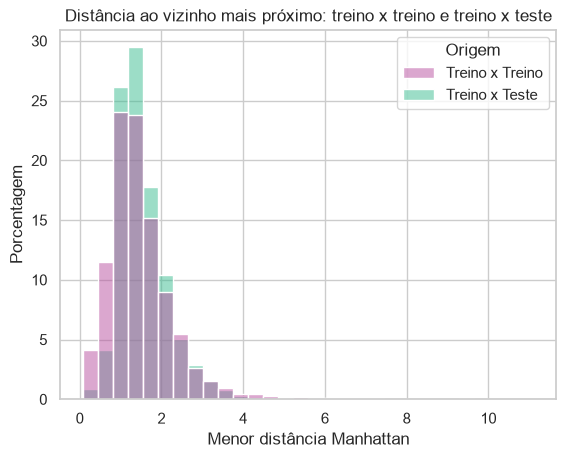

In [11]:
NUM_BINS = 30

distancias = pd.concat(
    [
        pd.DataFrame({"valor": treino_treino, "Origem": "Treino x Treino"}),
        pd.DataFrame({"valor": treino_teste, "Origem": "Treino x Teste"}),
    ],
    ignore_index=True,
)

bins = np.histogram_bin_edges(distancias["valor"], bins=NUM_BINS)

eixo = sns.histplot(
    data=distancias,
    x="valor",
    hue="Origem",
    bins=bins,
    alpha=0.5,
    stat="percent",
    common_norm=False,
    palette=PALETA_DISTANCIAS,
)
eixo.set(
    xlabel="Menor distância Manhattan",
    ylabel="Porcentagem",
    title="Distância ao vizinho mais próximo: treino x treino e treino x teste",
);

O histograma mostra que a distribuição *treino × teste* está levemente deslocada para a direita em relação à *treino × treino*: as medianas são **1,409** e **1,332**, respectivamente. Não há um acúmulo de distâncias de teste próximas de zero, que seria o sinal de exemplos de teste quase duplicados no treino.

Para verificar se esse deslocamento é estatisticamente significativo, usa-se o **teste de Mann-Whitney** [15], um teste não paramétrico que compara duas amostras sem supor que elas sejam normais. Isso é adequado aqui, porque as distâncias são assimétricas. A estatística $U$ conta, entre todos os pares possíveis, quantas vezes um valor da primeira amostra é menor que um valor da segunda. As hipóteses são:

- $H_0$: as duas distribuições são iguais, isto é, $P(D_{tt} < D_{te}) = 1/2$;
- $H_1$ (`alternative="less"`): as distâncias *treino × treino* tendem a ser **menores** que as distâncias *treino × teste*, isto é, $P(D_{tt} < D_{te}) > 1/2$.

Rejeitar $H_0$ significa que os exemplos de teste estão, em geral, mais afastados do treino do que os exemplos de treino entre si, que é o comportamento esperado de uma divisão saudável. O nível de significância adotado é de 5%.

In [12]:
NIVEL_CONFIANCA = 0.95

resultado = mannwhitneyu(treino_treino, treino_teste, alternative="less")
pvalor = resultado.pvalue

print("p-valor =", pvalor)

if pvalor < 1 - NIVEL_CONFIANCA:
    print("Rejeitar H0: split saudável.")
else:
    print("Não rejeitar H0: pode haver vazamento!")

p-valor = 2.7236721870130463e-09
Rejeitar H0: split saudável.


O p-valor obtido foi de aproximadamente $2{,}7 \times 10^{-9}$, muito abaixo de 0,05. Portanto, $H_0$ é rejeitada: a divisão agrupada por estrela **não apresenta indícios de vazamento por exemplos quase redundantes**.

Vale registrar o alcance desse teste: ele verifica apenas a proximidade entre exemplos no espaço dos atributos. Outras formas de vazamento, como o vazamento pelo alvo, foram tratadas separadamente, com a remoção das colunas listadas na seção 2.5. O vazamento por pré-processamento é evitado colocando todas as transformações dentro de *pipelines* (seção 5).

## <b>4. Análise exploratória de dados (EDA)</b>

A análise exploratória tem dois objetivos: **conhecer os dados** (escalas, faltantes, distribuições e redundâncias), para fundamentar as escolhas de pré-processamento da seção 5, e **verificar se os dados fazem sentido físico**.

Toda a análise é feita **apenas no conjunto de treino**. Olhar o conjunto de teste nesta etapa influenciaria decisões de modelagem, como quais transformações aplicar ou quais atributos remover, com informação que deveria estar reservada para a avaliação final.

### 4.1 Balanço de classes

O primeiro passo é verificar quantos exemplos há de cada classe. O desbalanceamento entre classes afeta diretamente a escolha das métricas de avaliação e a interpretação dos resultados.

In [13]:
def plota_balanco_classes(y, paleta):

    contagem = y.map(NOMES_CLASSES).value_counts()

    eixo = sns.barplot(
        x=contagem.index,
        y=contagem.values,
        hue=contagem.index,
        palette=paleta,
        legend=False,
    )
    eixo.set(
        xlabel="Classe",
        ylabel="Número de KOIs",
        title="Balanço das classes no conjunto de treino",
    )

    for i, valor in enumerate(contagem.values):
        eixo.text(i, valor, f"{valor} ({valor / contagem.sum():.1%})", ha="center", va="bottom")

A função `plota_balanco_classes` conta quantos KOIs há em cada classe, usando os nomes de `NOMES_CLASSES`, e desenha um gráfico de barras com as cores de `PALETA_CLASSES`. Acima de cada barra aparecem a contagem e a porcentagem do total.

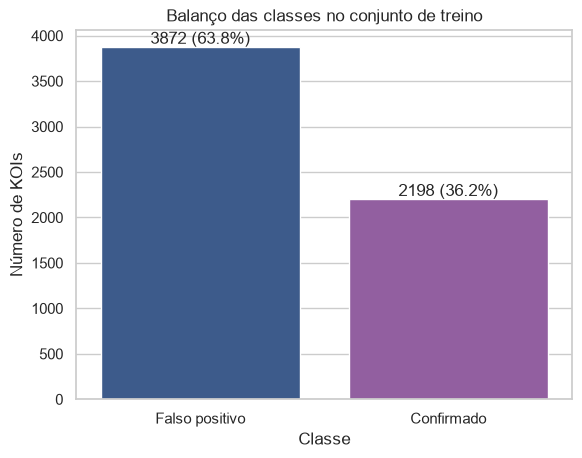

In [14]:
plota_balanco_classes(y_treino, PALETA_CLASSES)

O conjunto de treino tem **3.872 falsos positivos (63,8%)** e **2.198 confirmados (36,2%)**. O desbalanceamento é moderado, mas tem uma consequência importante: um classificador que sempre responde "falso positivo", sem olhar nenhum atributo, já acerta 63,8% dos exemplos. Por isso, a **acurácia** isolada pode ser enganosa, e a métrica principal deste trabalho é a **acurácia balanceada**, que dá o mesmo peso ao acerto de cada classe (seção 5.3). Essa comparação é feita explicitamente com os modelos de referência na seção 6.

Como o desbalanceamento não é extremo, não foram usadas técnicas de reamostragem, como a sobreamostragem com SMOTE. A estratificação na divisão e na validação cruzada garante que cada dobra mantenha essa mesma proporção.

### 4.2 Valores faltantes

Muitos algoritmos do scikit-learn não aceitam valores faltantes (`NaN`). Antes de decidir como tratá-los, é preciso saber quantos são e, principalmente, se eles se distribuem de forma igual entre as classes. Se a ausência de um valor for mais comum em uma das classes, ela própria carrega informação sobre o alvo [16].

In [15]:
def resume_faltantes(X, y):
    por_classe = X.isna().groupby(y).mean().T
    por_classe = por_classe.rename(columns={0: "falso_positivo", 1: "confirmado"})

    tabela = por_classe.assign(total=X.isna().mean())
    tabela = tabela[tabela["total"] > 0]

    return tabela.sort_values("total", ascending=False)

A função `resume_faltantes` calcula, para cada atributo, a **fração de valores faltantes em cada classe** e no total. O procedimento é o seguinte:

1. `X.isna()` gera uma tabela do mesmo tamanho de `X`, com `True` onde o valor está faltando e `False` onde ele existe;
2. `.groupby(y).mean()` separa as linhas por classe e calcula a média de cada coluna. Como `True` vale 1 e `False` vale 0, a média de uma coluna booleana é exatamente a **fração de faltantes**:

$$
f_j^{(c)} = \frac{1}{n_c} \sum_{i \,:\, y_i = c} \mathbb{1}\left[x_{ij} \text{ está faltando}\right] ,
$$

em que $n_c$ é o número de exemplos da classe $c$ e $\mathbb{1}[\cdot]$ vale 1 quando a condição é verdadeira e 0 caso contrário;
3. `.T` transpõe a tabela, para que cada **linha** corresponda a um atributo e cada **coluna** a uma classe. As colunas são renomeadas para `falso_positivo` e `confirmado`;
4. a coluna `total` recebe a fração de faltantes considerando todos os exemplos juntos;
5. por fim, são mantidos apenas os atributos com algum valor faltante (`total > 0`), ordenados do mais incompleto para o menos incompleto.

In [16]:
def plota_faltantes(tabela, num_atributos, cores):
    porcentagens = tabela.head(num_atributos).reindex(["falso_positivo", "confirmado"], axis=1) * 100

    eixo = porcentagens.plot.barh(figsize=(8, 5), color=cores)
    eixo.invert_yaxis()
    eixo.set(
        xlabel="% de valores faltantes",
        ylabel="Atributo",
        title=f"Faltantes por classe ({num_atributos} atributos mais incompletos)",
    )
    eixo.legend(title="Classe")

A função `plota_faltantes` transforma essa tabela em um **gráfico de barras horizontais**, comparando as duas classes lado a lado para cada atributo:

- `tabela.head(num_atributos)` seleciona apenas os atributos mais incompletos, já que a tabela está ordenada. Mostrar todos os 85 deixaria o gráfico ilegível;
- `.reindex([...], axis=1)` fixa a ordem das colunas (primeiro falso positivo, depois confirmado), para que as cores correspondam sempre à mesma classe;
- a multiplicação por 100 converte as frações em **porcentagens**;
- `eixo.invert_yaxis()` coloca o atributo mais incompleto no **topo** do gráfico, já que, por padrão, a primeira linha da tabela ficaria embaixo.

As cores das classes vêm das mesmas constantes usadas em todo o notebook.

(85, 3)


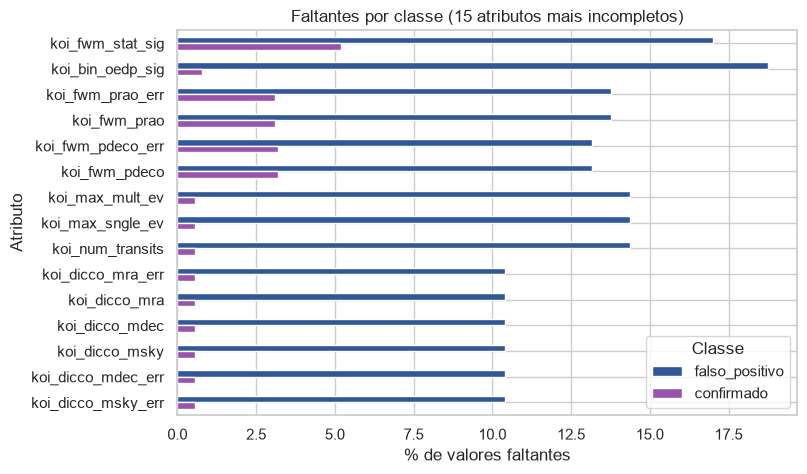

In [17]:
NUM_ATRIBUTOS_FALTANTES = 15

tabela_faltantes = resume_faltantes(X_treino, y_treino)
print(tabela_faltantes.shape)

plota_faltantes(tabela_faltantes, NUM_ATRIBUTOS_FALTANTES, [COR_FALSO_POSITIVO, COR_CONFIRMADO])

A tabela resultante tem formato **(85, 3)**: são **85 atributos com pelo menos um valor faltante** (de 89) e três colunas (fração nos falsos positivos, nos confirmados e no total). O gráfico mostra os **15 atributos mais incompletos** (`NUM_ATRIBUTOS_FALTANTES = 15`), número suficiente para revelar o padrão sem sobrecarregar a figura.

Dos 89 atributos, **85 têm algum valor faltante**, mas em proporções pequenas: o mais incompleto, `koi_fwm_stat_sig`, falta em **12,7%** dos KOIs. Por outro lado, como os faltantes se espalham por colunas diferentes, **30,8% dos KOIs** têm pelo menos um valor faltante.

O resultado mais importante é que **a ausência de valores não é aleatória**. Ela é muito mais frequente nos falsos positivos: 41,7% dos falsos positivos têm algum faltante, contra 11,5% dos confirmados. Alguns exemplos:

| Atributo | Falso positivo | Confirmado |
|---|---|---|
| `koi_bin_oedp_sig` (comparação entre trânsitos pares e ímpares) | 18,8% | 0,8% |
| `koi_fwm_stat_sig` (significância do deslocamento do centroide) | 17,0% | 5,2% |
| `koi_max_mult_ev`, `koi_num_transits`, `koi_max_sngle_ev` | 14,4% | 0,5% |
| colunas `koi_dicco_*` (centroides da imagem diferença) | 10,4% | 0,5% |

Os atributos de um mesmo grupo faltam juntos nas mesmas linhas, o que indica que são produzidos pela mesma etapa do pipeline do Kepler e deixam de ser calculados quando essa etapa não pode ser executada para um sinal. Na terminologia de Little e Rubin [16], os dados **não faltam completamente ao acaso**. Isso motivou três decisões:

1. **Não remover linhas com faltantes.** Remover 30,8% dos dados descartaria, desproporcionalmente, os falsos positivos e distorceria a distribuição das classes.
2. **Imputar pela mediana** dentro do *pipeline*. A mediana é usada em vez da média porque os atributos são muito assimétricos (seção 4.3), e a imputação é ajustada apenas no treino de cada dobra.
3. **Deixar o Optuna decidir se acrescenta indicadores de faltante** (`add_indicator`): colunas binárias que valem 1 quando o valor original estava ausente. Assim, a informação contida na própria ausência pode ser aproveitada pelo modelo.

### 4.3 Assimetria

A **assimetria** (*skewness*) mede o quanto uma distribuição se afasta da simetria em torno da média. Sua definição amostral é

$$
g_1 = \frac{1}{n}\sum_{i=1}^{n}\left(\frac{x_i - \bar{x}}{s}\right)^3 ,
$$

em que $\bar{x}$ é a média e $s$ o desvio-padrão. Como os desvios são elevados ao cubo, valores muito acima da média (uma cauda longa à direita) produzem $g_1 > 0$ e grande. Uma distribuição simétrica tem $g_1 = 0$, e, como regra prática, $|g_1| > 1$ indica assimetria forte. O pandas calcula a versão com correção de viés, $G_1 = g_1\sqrt{n(n-1)}/(n-2)$ [17], que, para $n = 6.070$, é praticamente igual a $g_1$.

In [18]:
def calcula_assimetria(X):
    return X.skew().abs().sort_values(ascending=False)

A função `calcula_assimetria` calcula a assimetria de cada atributo com o método `skew` do pandas (a versão $G_1$, com correção de viés), toma o módulo, porque interessa o tamanho da assimetria e não o lado da cauda, e ordena os atributos da maior para a menor assimetria.

In [19]:
assimetria = calcula_assimetria(X_treino)
assimetria.reindex(["koi_prad", "koi_impact", "koi_srad", "koi_depth", "koi_period"]).round(1)

koi_prad      48.7
koi_impact    24.0
koi_srad      19.4
koi_depth      4.8
koi_period     3.0
dtype: float64

A assimetria é extrema em vários atributos: `koi_prad` (48,7), `koi_impact` (24,0), `koi_srad` (19,4), `koi_depth` (4,8) e `koi_period` (3,0). No total, **73 dos 89 atributos** têm $|g_1| > 1$. Em `koi_prad`, por exemplo, a cauda vem de valores de raio impossíveis para planetas: **44,4% dos falsos positivos** têm raio implícito acima de 15 raios terrestres (maior que Júpiter), contra apenas 1,0% dos confirmados. Esses valores surgem quando o "planeta" é, na verdade, uma estrela companheira, e por isso não devem ser tratados como erros a remover: eles são justamente parte do sinal que separa as classes.

Essa assimetria orienta várias escolhas:

- a **média e o desvio-padrão são dominados pelos valores extremos**, o que explica o uso da **mediana** na imputação;
- para os modelos que dependem de distâncias ou de escala (kNN, SVM, PCA, VIF e RFE), o Optuna escolhe entre três normalizações: a padronização (`StandardScaler`), a escala robusta, baseada em mediana e intervalo interquartil (`RobustScaler`), e a **transformação de potência de Yeo-Johnson** (`PowerTransformer`) [18], que reduz a assimetria antes de padronizar;
- os modelos baseados em árvores não precisam de normalização: cada corte compara um atributo com um limiar e depende apenas da **ordem** dos valores, que não muda com transformações monotônicas;
- nos gráficos, os atributos mais assimétricos são exibidos em **escala logarítmica**.

### 4.4 Comparação por classes

Para verificar se os atributos carregam informação sobre o alvo, compara-se a distribuição de oito atributos físicos centrais entre as duas classes: período, profundidade, raio do planeta, razão sinal-ruído, parâmetro de impacto, temperatura de equilíbrio, temperatura efetiva e raio da estrela. Os gráficos de caixa (*boxplots*) mostram a mediana (linha central), os quartis (limites da caixa) e os valores extremos.

In [20]:
ATRIBUTOS_PRINCIPAIS = [
    "koi_period", "koi_depth", "koi_prad", "koi_model_snr",
    "koi_impact", "koi_teq", "koi_steff", "koi_srad",
]
ATRIBUTOS_ESCALA_LOG = ["koi_period", "koi_depth", "koi_prad", "koi_model_snr", "koi_srad"]
LIMITES_EIXO = {"koi_impact": (0, 1.5)}

As constantes acima definem o que será comparado e como será exibido:

- `ATRIBUTOS_PRINCIPAIS` reúne oito atributos escolhidos por sua relevância física para separar planetas de falsos positivos: quatro descrevem o **sinal de trânsito** (`koi_period`, `koi_depth`, `koi_model_snr`, `koi_impact`), dois descrevem o **planeta inferido** (`koi_prad`, `koi_teq`) e dois descrevem a **estrela** (`koi_steff`, `koi_srad`). Não faz sentido mostrar os 89 atributos, então a escolha privilegia grandezas com interpretação física direta;
- `ATRIBUTOS_ESCALA_LOG` lista os atributos exibidos em **escala logarítmica**. São os mais assimétricos (seção 4.3), cujos valores se espalham por várias ordens de grandeza. Em escala linear, a maior parte dos dados ficaria comprimida perto de zero e as diferenças entre as classes seriam invisíveis. Em escala logarítmica, intervalos iguais no eixo correspondem a **razões** iguais ($10 \to 100$ ocupa o mesmo espaço que $100 \to 1000$);
- `LIMITES_EIXO` restringe o eixo de `koi_impact` ao intervalo $[0; 1{,}5]$. O parâmetro de impacto tem valores extremos muito altos, consequência dos ajustes de trânsitos rasantes, que achatariam o gráfico. O limite de 1,5 mantém visível a região de interesse, em torno de $b = 1$, que separa trânsitos completos de rasantes. Esse corte afeta **apenas a visualização**: nenhum dado é removido.

In [21]:
def plota_por_classe(X, y, atributos, atributos_log, limites, paleta):

    num_colunas = (len(atributos) + 1) // 2

    fig, eixos = plt.subplots(2, num_colunas, figsize=(4 * num_colunas, 7))
    eixos = eixos.ravel()

    for eixo, atributo in zip(eixos, atributos):
        dados = pd.DataFrame({"valor": X[atributo], "classe": y.map(NOMES_CLASSES)})

        sns.boxplot(
            data=dados,
            x="classe",
            y="valor",
            hue="classe",
            order=list(paleta),
            hue_order=list(paleta),
            palette=paleta,
            legend=False,
            ax=eixo,
        )

        if atributo in atributos_log:
            eixo.set_yscale("log")

        if atributo in limites:
            eixo.set_ylim(*limites[atributo])

        sufixo = " (escala log)" if atributo in atributos_log else ""
        eixo.set(xlabel="Classe", ylabel=atributo + sufixo)

    for eixo in eixos[len(atributos):]:
        eixo.axis("off")

    fig.suptitle("Atributos principais por classe (conjunto de treino)", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.96))

A função `plota_por_classe` desenha um **gráfico de caixa** (*boxplot*) por atributo, com as duas classes lado a lado. Em um boxplot:

- a **linha central** da caixa é a mediana;
- os **limites da caixa** são o primeiro e o terceiro quartis ($Q_1$ e $Q_3$), de modo que a caixa contém os 50% centrais dos dados. Sua altura é o intervalo interquartil, $\text{IQR} = Q_3 - Q_1$;
- as **hastes** vão até o valor mais extremo que ainda esteja a no máximo $1{,}5 \times \text{IQR}$ da caixa;
- os **pontos isolados** são os valores além das hastes.

O boxplot foi escolhido porque se baseia em medianas e quartis, que, diferentemente da média e do desvio-padrão, **não são distorcidos pelos valores extremos** encontrados na seção 4.3.

Quanto à construção do gráfico:

- a figura é dividida em uma grade de duas linhas (`plt.subplots(2, num_colunas)`), com `num_colunas = (n + 1) // 2`, que é o número necessário para caber $n$ gráficos em duas linhas, arredondando para cima;
- para cada atributo, monta-se uma tabela com o valor e o nome da classe, e o `sns.boxplot` desenha as duas caixas com as cores de `PALETA_CLASSES`. Os argumentos `order` e `hue_order` fixam a mesma ordem das classes em todos os gráficos;
- os atributos de `ATRIBUTOS_ESCALA_LOG` recebem escala logarítmica, e os de `LIMITES_EIXO` têm o eixo restrito. O rótulo do eixo vertical indica quando a escala é logarítmica;
- se sobrar algum espaço vazio na grade, ele é escondido (`eixo.axis("off")`).

A chamada abaixo gera a figura com os oito atributos, comparando falsos positivos e confirmados no conjunto de treino.

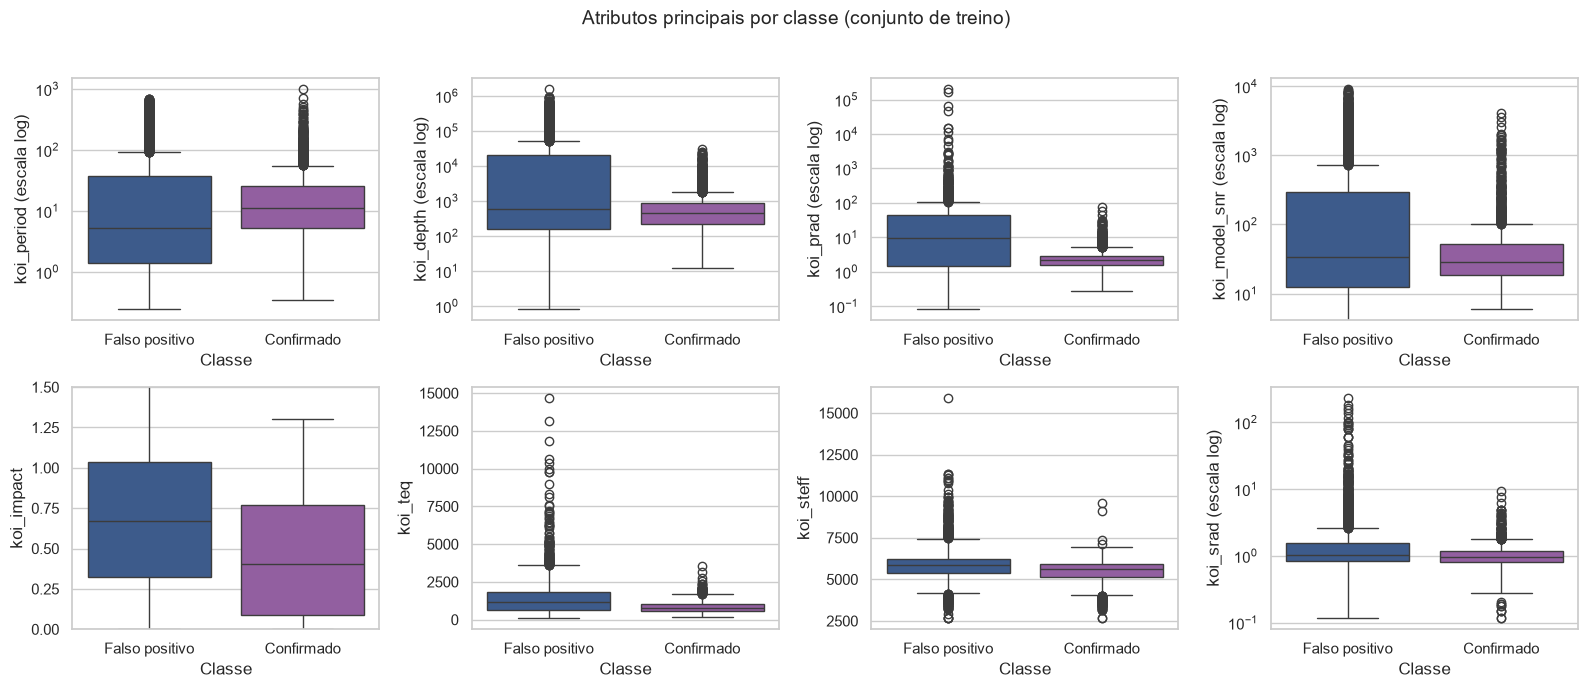

In [22]:
plota_por_classe(X_treino, y_treino, ATRIBUTOS_PRINCIPAIS, ATRIBUTOS_ESCALA_LOG, LIMITES_EIXO, PALETA_CLASSES)

As medianas de cada classe resumem as diferenças observadas:

| Atributo | Falso positivo | Confirmado |
|---|---|---|
| `koi_prad` (raios terrestres) | 9,32 | 2,17 |
| `koi_period` (dias) | 5,24 | 11,33 |
| `koi_impact` | 0,67 | 0,40 |
| `koi_teq` (K) | 1.149 | 779 |
| `koi_depth` (ppm) | 584 | 450 |
| `koi_model_snr` | 33,7 | 28,9 |
| `koi_steff` (K) | 5.871 | 5.616 |
| `koi_srad` (raios solares) | 1,01 | 0,96 |

As diferenças têm interpretação física:

- **Raio do planeta:** a mediana dos falsos positivos é cerca de quatro vezes maior. Quando o objeto que eclipsa é uma estrela, o "raio do planeta" calculado a partir da profundidade é o raio de uma estrela, grande demais para um planeta [4].
- **Parâmetro de impacto:** o parâmetro $b$ é a distância projetada entre os centros dos discos no meio do trânsito, em unidades do raio estelar. Valores próximos ou acima de 1 indicam trânsitos **rasantes**, em que o objeto só toca a borda da estrela. Esse é um padrão típico de binárias eclipsantes: **25,2% dos falsos positivos** têm $b > 1$, contra 0,7% dos confirmados.
- **Período e temperatura de equilíbrio:** os falsos positivos têm períodos mais curtos, o que é compatível com binárias próximas. A temperatura de equilíbrio maior é consequência direta disso: períodos mais curtos significam órbitas menores e mais próximas da estrela (seção 4.6).
- **Atributos estelares:** a temperatura efetiva e o raio da estrela são muito parecidos entre as classes. Sozinhos, eles discriminam pouco, mas são necessários para converter grandezas relativas em absolutas (por exemplo, $R_p = \text{ror} \times R_\star$).

Esta é uma análise **univariada**: as classes se sobrepõem bastante em todos os atributos, e nenhum deles separa as classes sozinho. É justamente a combinação de vários atributos que os algoritmos de aprendizado de máquina exploram.

### 4.5 Checagem física (profundidade versus razão de raios)

Uma forma de verificar a qualidade dos dados é testar se eles obedecem a uma relação física conhecida. Pela seção 2.1, a profundidade do trânsito deve seguir $\delta_{\text{ppm}} \approx 10^6 \, \text{ror}^2$ [2]. Aplicando o logaritmo dos dois lados,

$$
\log_{10} \delta_{\text{ppm}} \approx 2 \log_{10} \text{ror} + 6 ,
$$

ou seja, em um gráfico log-log de profundidade contra razão de raios, os pontos devem cair sobre uma **reta de inclinação 2**. A inclinação é estimada por um ajuste linear (`np.polyfit`) em escala logarítmica, com todos os KOIs e depois apenas com os trânsitos **centrais** ($b < 0{,}5$).

In [23]:
LIMITE_IMPACTO_CENTRAL = 0.5

A constante `LIMITE_IMPACTO_CENTRAL` define o que é considerado um trânsito **central**: aquele com parâmetro de impacto $b < 0{,}5$, isto é, em que o centro do objeto passa a menos de meio raio estelar do centro da estrela. O valor 0,5 é um critério conservador: nesses trânsitos, o disco do objeto fica inteiramente sobre o disco da estrela, e a aproximação $\delta \approx \text{ror}^2$ deve valer bem.

In [24]:
def checa_profundidade(X, limite_impacto, cor_rasante, cor_central):

    dados = X.reindex(["koi_depth", "koi_ror", "koi_impact"], axis=1).dropna()
    dados = dados[(dados["koi_depth"] > 0) & (dados["koi_ror"] > 0)]

    central = dados["koi_impact"] < limite_impacto

    def inclinacao(d):
        return np.polyfit(np.log10(d["koi_ror"]), np.log10(d["koi_depth"]), 1)[0]

    fig, eixo = plt.subplots(figsize=(7, 5))

    eixo.scatter(
        dados.loc[~central, "koi_ror"], dados.loc[~central, "koi_depth"],
        s=5, alpha=0.4, color=cor_rasante,
        label=f"impacto ≥ {limite_impacto} (mais rasante)",
    )
    eixo.scatter(
        dados.loc[central, "koi_ror"], dados.loc[central, "koi_depth"],
        s=5, alpha=0.4, color=cor_central,
        label=f"impacto < {limite_impacto} (central)",
    )

    eixo.set(
        xlabel="Razão de raios planeta/estrela (koi_ror)",
        ylabel="Profundidade do trânsito, ppm (koi_depth)",
        title="Profundidade do trânsito versus razão de raios",
        xscale="log",
        yscale="log",
    )
    eixo.legend(markerscale=3)

    return inclinacao(dados), inclinacao(dados[central])

A função `checa_profundidade` faz a verificação em quatro passos:

1. seleciona `koi_depth`, `koi_ror` e `koi_impact` e descarta as linhas com algum desses valores faltando;
2. mantém apenas profundidades e razões de raios **positivas**, porque o logaritmo de zero ou de um número negativo não está definido;
3. ajusta uma reta aos pontos em escala log-log com `np.polyfit(..., 1)`, ou seja, encontra $a$ e $c$ que minimizam o erro quadrático de $\log_{10}\delta = a\,\log_{10}\text{ror} + c$. A inclinação $a$ é o primeiro coeficiente devolvido;
4. faz o ajuste duas vezes, com todos os KOIs e só com os trânsitos centrais, e desenha os dois grupos com cores diferentes, em eixos logarítmicos.

Pela relação da seção 2.1, a inclinação esperada é $a = 2$.

Inclinação com todos os exemplos: 1.35
Inclinação só com trânsitos centrais: 1.98


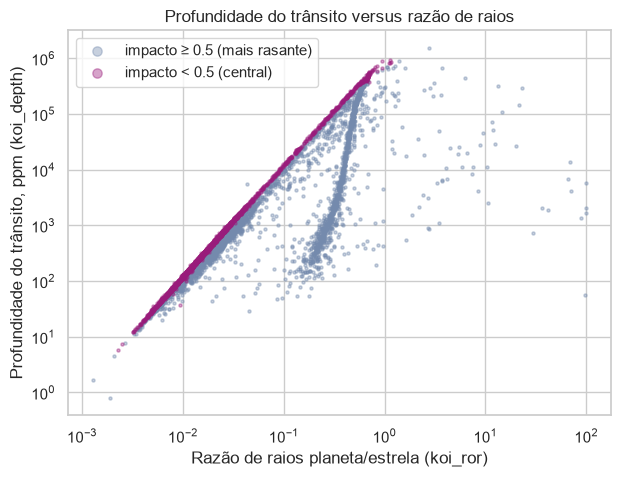

In [25]:
inclinacao_todos, inclinacao_central = checa_profundidade(
    X_treino, LIMITE_IMPACTO_CENTRAL, COR_TRANSITO_RASANTE, COR_TRANSITO_CENTRAL
)

print(f"Inclinação com todos os exemplos: {inclinacao_todos:.2f}")
print(f"Inclinação só com trânsitos centrais: {inclinacao_central:.2f}")

Com todos os KOIs, a inclinação ajustada é de **1,35**, bem abaixo do valor esperado. Considerando apenas os trânsitos centrais ($b < 0{,}5$), ela sobe para **1,98**, praticamente igual ao valor teórico de 2.

A explicação é geométrica. A relação $\delta \approx \text{ror}^2$ supõe que o disco do objeto fique **inteiramente** dentro do disco da estrela durante o trânsito. Em trânsitos rasantes ($b$ próximo ou acima de 1), apenas parte do disco do objeto cobre a estrela, e a profundidade fica **menor** que $\text{ror}^2$. Isso achata a relação e reduz a inclinação. O escurecimento de limbo, isto é, o fato de a borda da estrela ser menos brilhante que o centro, também contribui para desvios nesses casos.

Esse resultado tem duas consequências. A primeira é que os dados são **fisicamente consistentes**: onde a aproximação é válida, ela é obedecida. A segunda é que o desvio se concentra justamente nos trânsitos rasantes, que são muito mais comuns entre os falsos positivos (seção 4.4). Assim, a combinação de profundidade, razão de raios e parâmetro de impacto carrega informação útil para a classificação.

### 4.6 Correlação e redundância

Atributos fortemente correlacionados trazem informação redundante. Isso pode prejudicar modelos baseados em distância, como o kNN, em que a mesma informação é contada várias vezes, e modelos lineares, que sofrem com a multicolinearidade. Também dificulta a interpretação, porque atributos correlacionados "dividem" a importância entre si.

A correlação usada é a de **Spearman** [19], que é a correlação de Pearson calculada sobre os **postos** (as posições ordenadas) dos valores:

$$
\rho_s = \text{corr}\big(\text{posto}(x), \text{posto}(y)\big) .
$$

Ela foi escolhida por dois motivos. Primeiro, é robusta à assimetria e aos valores extremos encontrados na seção 4.3. Segundo, mede qualquer relação **monotônica**, não apenas a linear: $\rho_s = 1$ sempre que $y$ cresce com $x$, mesmo que a relação seja curva. As colunas de incerteza (`_err1`, `_err2`) foram omitidas do mapa de calor para torná-lo legível, o que deixa 61 atributos.

In [26]:
SUFIXOS_ERRO = ("_err1", "_err2")
LIMITE_CORRELACAO = 0.95

`SUFIXOS_ERRO` identifica as colunas de incerteza (`_err1` e `_err2`), que são retiradas do mapa de calor apenas para torná-lo legível. `LIMITE_CORRELACAO = 0,95` é o valor a partir do qual um par de atributos é considerado praticamente redundante: com $|\rho_s| \geq 0{,}95$, um atributo determina quase completamente a ordem do outro.

In [27]:
def plota_correlacao(X, mapa_de_cor):
    atributos = [c for c in X.columns if not c.endswith(SUFIXOS_ERRO)]
    correlacao = X.reindex(atributos, axis=1).corr(method="spearman")

    plt.figure(figsize=(14, 11))

    eixo = sns.heatmap(
        correlacao,
        cmap=mapa_de_cor,
        vmin=-1,
        vmax=1,
        center=0,
        xticklabels=True,
        yticklabels=True,
        cbar_kws={"label": "Correlação de Spearman"},
    )
    eixo.set(
        xlabel="Atributo",
        ylabel="Atributo",
        title="Correlação de Spearman entre os atributos (conjunto de treino)",
    )
    eixo.tick_params(labelsize=6)

A função `plota_correlacao` calcula a matriz de correlação de Spearman com `corr(method="spearman")` do pandas e a desenha como um mapa de calor. A escala de cores vai de $-1$ a $+1$ e é centrada em zero (`center=0`), com um mapa divergente: tons de vermelho indicam correlação positiva, tons de azul indicam correlação negativa, e cores claras indicam ausência de correlação monotônica.

In [28]:
def acha_pares_correlacionados(X, limite):
    correlacao = X.corr(method="spearman")

    triangulo = correlacao.where(np.triu(np.ones(correlacao.shape, dtype=bool), k=1))

    pares = triangulo.stack().rename("rho").reset_index()
    pares.columns = ["atributo_1", "atributo_2", "rho"]

    pares = pares[pares["rho"].abs() >= limite]

    return pares.sort_values("rho", key=abs, ascending=False)

A função `acha_pares_correlacionados` transforma a matriz de correlação em uma lista de pares. Como a matriz é simétrica ($\rho_{ij} = \rho_{ji}$) e a diagonal vale sempre 1, ela usa apenas o **triângulo superior sem a diagonal** (`np.triu(..., k=1)`), de modo que cada par aparece uma única vez. Em seguida, mantém os pares com $|\rho_s|$ acima do limite e os ordena do mais para o menos correlacionado, em valor absoluto.

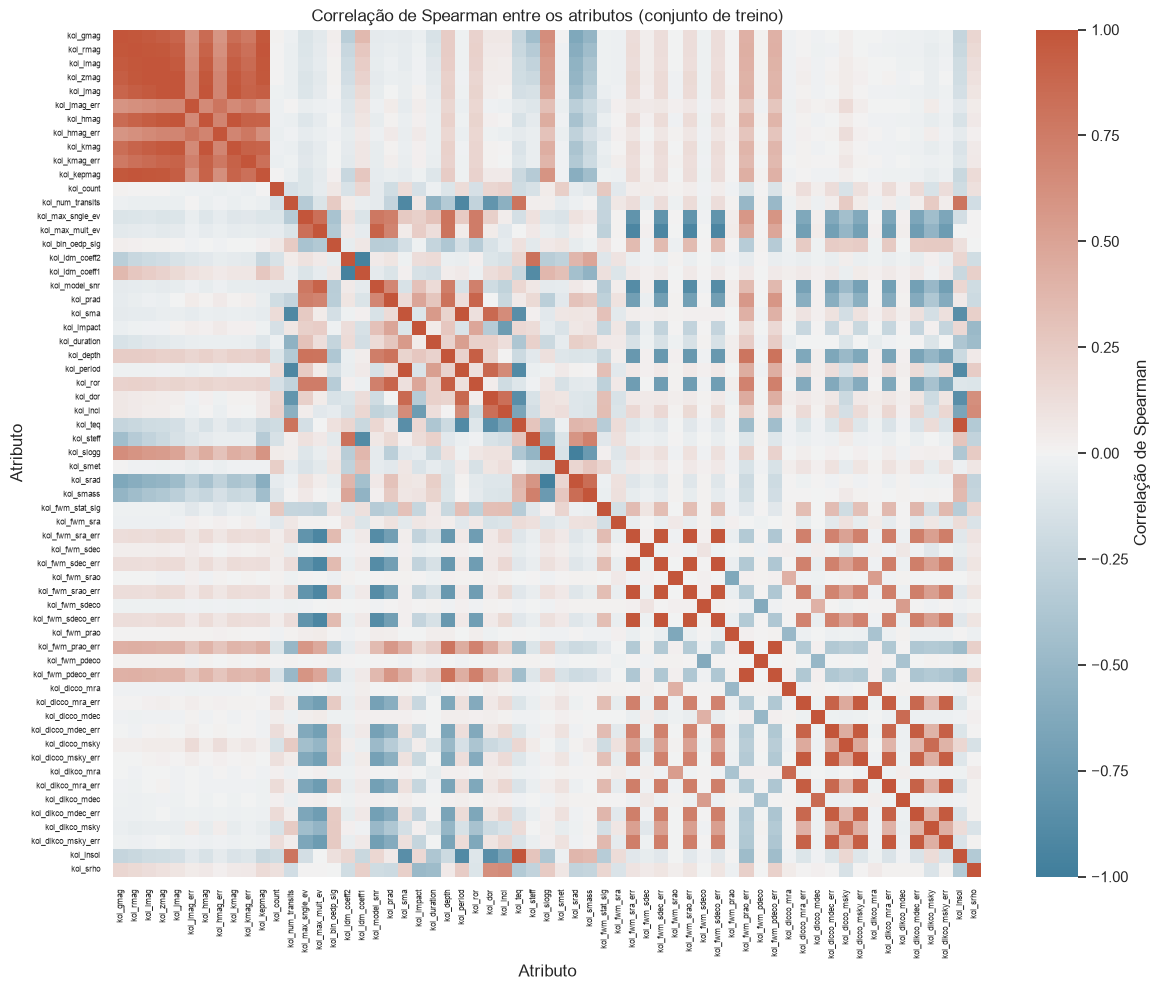

In [29]:
plota_correlacao(X_treino, MAPA_DE_COR)

O mapa de calor mostra blocos bem definidos de atributos fortemente correlacionados: no canto superior esquerdo, as **magnitudes** da estrela nas diferentes bandas; no canto inferior direito, as medidas e incertezas dos **deslocamentos de centroide** (`koi_fwm_*`, `koi_dicco_*`, `koi_dikco_*`); e, na região central, os atributos do **sinal de trânsito** (profundidade, razão de raios, razão sinal-ruído e estatísticas de detecção). Também se destacam pares isolados, como `koi_teq` com `koi_insol` e `koi_slogg` com `koi_srad`. A célula seguinte lista esses pares numericamente.

In [30]:
atributos_sem_erro = [c for c in ATRIBUTOS if not c.endswith(SUFIXOS_ERRO)]
pares = acha_pares_correlacionados(X_treino.reindex(atributos_sem_erro, axis=1), LIMITE_CORRELACAO)

print(f"Atributos sem erro: {len(atributos_sem_erro)}")
print(f"Pares com |rho| >= {LIMITE_CORRELACAO}: {len(pares)}")
pares.head(4)

Atributos sem erro: 61
Pares com |rho| >= 0.95: 31


,atributo_1,atributo_2,rho
1767,koi_teq,koi_insol,1.000000
2360,koi_fwm_sdec_err,koi_fwm_sdeco_err,0.999866
71,koi_rmag,koi_kepmag,0.999171
2236,koi_fwm_sra_err,koi_fwm_srao_err,0.998484


Entre os 61 atributos sem as colunas de erro, há **31 pares com $|\rho_s| \geq 0{,}95$**. Quase todos têm explicação física:

- **`koi_teq` × `koi_insol` ($\rho_s = 1{,}000$).** A temperatura de equilíbrio de um planeta que redistribui o calor uniformemente é $T_{eq} = T_\star (1 - A)^{1/4} \sqrt{R_\star / (2a)}$. A insolação é $S \propto L_\star / a^2$, e a luminosidade é $L_\star = 4\pi R_\star^2 \sigma T_\star^4$. Combinando as duas, $S \propto R_\star^2 T_\star^4 / a^2$, e portanto $T_{eq} \propto (1-A)^{1/4} S^{1/4}$. Como o arquivo usa um albedo fixo de $A = 0{,}3$ [10], $T_{eq}$ é uma função crescente de $S$, e a correlação de postos é exatamente 1: um dos dois atributos é totalmente redundante.
- **`koi_sma` × `koi_period` ($\rho_s = 0{,}996$).** É a terceira lei de Kepler: $P^2 = 4\pi^2 a^3 / [G(M_\star + M_p)]$, ou seja, $a \propto P^{2/3} M_\star^{1/3}$. A correlação não é exatamente 1 porque a massa estelar varia entre as estrelas.
- **`koi_slogg` × `koi_srad` ($\rho_s = -0{,}980$).** A gravidade superficial é $g = G M_\star / R_\star^2$. Como a massa varia pouco entre as estrelas da amostra, estrelas maiores têm gravidade superficial menor.
- **Magnitudes entre si** (por exemplo, `koi_rmag` × `koi_kepmag`, com $\rho_s = 0{,}999$): são medidas do brilho da mesma estrela em bandas vizinhas do espectro.
- **`koi_ldm_coeff1` × `koi_ldm_coeff2` ($\rho_s = -0{,}968$)**: os dois coeficientes de escurecimento de limbo são obtidos juntos, a partir dos mesmos parâmetros estelares.
- **Incertezas dos centroides** (`koi_fwm_*_err`, `koi_dicco_*_err`, `koi_dikco_*_err`): as incertezas nas duas coordenadas do céu são calculadas a partir das mesmas imagens.

Essa redundância **motivou a inclusão da redução de dimensionalidade e da seleção de atributos no espaço de busca do Optuna** (PCA, seleção por VIF e RFE, seção 5), em vez de remover atributos manualmente nesta etapa. Assim, a decisão de remover ou não a redundância é tomada com base no desempenho em validação cruzada, e não apenas na inspeção visual. A redundância também será considerada na interpretação dos modelos (seção 10), porque atributos correlacionados tendem a dividir a importância entre si.

### 4.7 Estrelas com mais de um KOI

Como um KOI é um sinal, e não uma estrela, uma mesma estrela pode ter vários KOIs. Esta seção verifica com que frequência isso acontece e se a multiplicidade se relaciona com o alvo.

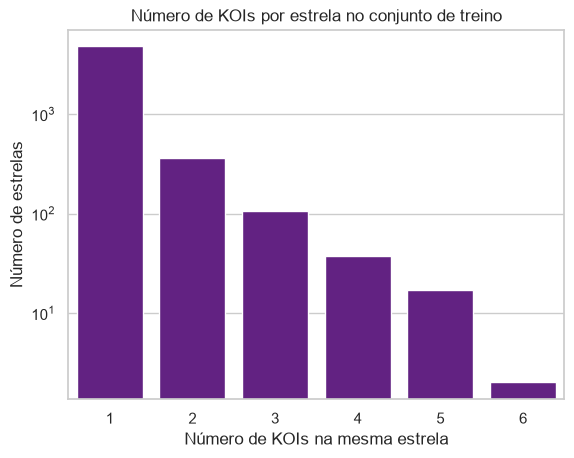

In [31]:
kois_por_estrela = df_treino.groupby(NOME_GRUPO).size().value_counts().sort_index()

eixo = sns.barplot(x=kois_por_estrela.index, y=kois_por_estrela.values, color=COR_BARRAS)
eixo.set(
    xlabel="Número de KOIs na mesma estrela",
    ylabel="Número de estrelas",
    title="Número de KOIs por estrela no conjunto de treino",
    yscale="log",
);

Os 6.070 KOIs de treino pertencem a **5.307 estrelas**. A grande maioria das estrelas (4.784) tem um único KOI, mas 360 têm dois, 107 têm três, e há estrelas com até seis KOIs (o eixo vertical está em escala logarítmica). No total, **21,2% dos KOIs** estão em estrelas com mais de um KOI.

A multiplicidade está fortemente associada ao alvo. Entre os KOIs de estrelas com mais de um KOI, **81,8% são confirmados**, contra apenas **24,0%** entre os KOIs de estrelas com um único KOI. Esse comportamento é conhecido na literatura. Os falsos positivos, em sua maioria causados por binárias, se distribuem quase aleatoriamente entre as estrelas, e seria muito improvável encontrar vários deles na mesma estrela. Já os planetas tendem a ocorrer em sistemas com vários planetas. Por isso, quase todos os candidatos em sistemas múltiplos são planetas reais [20].

Esse resultado tem duas consequências para a modelagem:

1. **Justifica o agrupamento por estrela** na divisão treino/teste (seção 3) e na validação cruzada (seção 5.2). KOIs de uma mesma estrela compartilham **12 atributos idênticos** (as magnitudes e o `koi_count`) e parâmetros estelares muito próximos. Separá-los entre treino e teste permitiria ao modelo reconhecer a estrela, inflando artificialmente as métricas.
2. **O atributo `koi_count`** (número de KOIs no sistema) carrega essa informação de multiplicidade. Foi verificado que ele é igual ao número total de KOIs da estrela na tabela, contando todas as disposições. Portanto, ele não depende do veredito de cada KOI e não constitui vazamento pelo alvo. Ainda assim, ele reflete o resultado da busca por sinais na mesma estrela, e seu peso no modelo final será discutido na seção 10.

## <b>5. Pré-processamento e desenho experimental</b>


Esta seção descreve como os dados são preparados para os modelos e como os modelos são avaliados e comparados. As decisões aqui tomadas seguem diretamente da análise exploratória: valores faltantes informativos (seção 4.2), atributos muito assimétricos (seção 4.3), atributos redundantes (seção 4.6) e KOIs agrupados por estrela (seção 4.7). Antes da otimização dos algoritmos, um **estudo preliminar de desenho** (seção 5.6) testa algumas dessas decisões, usando apenas o conjunto de treino.

### 5.1 Pipeline e pré-processamento

Todo o pré-processamento é feito **dentro de um `Pipeline`** do scikit-learn [12, 21]. Um pipeline encadeia as etapas de transformação e o modelo em um único objeto: quando ele é ajustado (`fit`), cada etapa é ajustada **apenas nos dados de treino** recebidos; quando ele faz previsões, as etapas já ajustadas são apenas aplicadas.

Isso é essencial para evitar o vazamento por pré-processamento [11, 13]. Por exemplo, se a média $\mu$ usada na padronização fosse calculada com os dados de treino e de validação juntos, ela seria

$$
\mu_{\text{tudo}} = \frac{n_{\text{tr}}\,\mu_{\text{tr}} + n_{\text{val}}\,\mu_{\text{val}}}{n_{\text{tr}} + n_{\text{val}}} ,
$$

ou seja, dependeria de $\mu_{\text{val}}$, uma informação dos dados que deveriam estar sendo avaliados como "nunca vistos". Dentro do pipeline, a validação cruzada reajusta todas as etapas em cada dobra, usando somente o treino daquela dobra.

O pipeline de cada modelo tem até quatro etapas, montadas pela função `cria_instancia_modelo` (`src/pipelines.py`):

| Etapa | Opções | Quando entra |
|---|---|---|
| `imputador` | mediana, com ou sem indicador de faltante | sempre |
| `normalizador` | `StandardScaler`, `RobustScaler` ou `PowerTransformer` (Yeo-Johnson) | no kNN e no SVM, e sempre que houver redução |
| `reducao` | nenhuma, PCA, seleção por VIF ou RFE | escolhida pelo Optuna |
| `modelo` | kNN, árvore, floresta, gradient boosting ou SVM | sempre |

As justificativas de cada etapa são:

- **Imputação pela mediana:** os atributos são muito assimétricos (seção 4.3), e a média seria puxada pelos valores extremos. O **indicador de faltante** (`add_indicator`) acrescenta uma coluna binária para cada atributo com valores faltantes no treino, valendo 1 quando o valor original estava ausente. Ele é uma opção porque a ausência de valores é muito mais comum nos falsos positivos (seção 4.2) [16].
- **Normalização:** modelos baseados em distâncias (kNN) ou em kernels que dependem de distâncias (SVM com kernel RBF) são sensíveis à escala dos atributos. As técnicas de redução também são: o PCA procura direções de máxima variância, e a variância depende da escala; o VIF e o RFE (que usa uma regressão logística regularizada) também dependem dela. Já as árvores não precisam de normalização, porque cada corte compara um atributo com um limiar e depende apenas da **ordem** dos valores. As três opções são a padronização ($z = (x - \mu)/\sigma$), a escala robusta, que usa a mediana e o intervalo interquartil, e a transformação de potência de Yeo-Johnson [18], que reduz a assimetria antes de padronizar.
- **Redução de dimensionalidade e seleção de atributos:** motivadas pela redundância encontrada na seção 4.6. O **PCA** [22] projeta os dados nas direções de maior variância, mantendo componentes até atingir a fração de variância explicada escolhida. A **seleção por VIF** [23] remove, um a um, os atributos mais redundantes (seção 5.6.4). O **RFE** (*recursive feature elimination*) [24, 23] ajusta uma regressão logística, remove os atributos de menor peso e repete o processo até restar a fração escolhida. O `VarianceThreshold` não foi incluído: como $\text{Var}(aX) = a^2\,\text{Var}(X)$, a variância depende da escala, e depois da padronização todas as variâncias valem 1.

A escolha das etapas e de seus hiperparâmetros é feita pelo Optuna (seção 5.4). A célula abaixo monta um pipeline de exemplo, com escolhas sorteadas ao acaso, apenas para ilustrar a estrutura.

In [32]:
set_config(display="diagram")

estudo_exemplo = optuna.create_study(sampler=optuna.samplers.RandomSampler(seed=SEMENTE_ALEATORIA))
trial_exemplo = estudo_exemplo.ask()

pipeline_exemplo = cria_instancia_modelo(trial_exemplo, "knn", SEMENTE_ALEATORIA)
pipeline_exemplo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputador', ...), ('normalizador', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimator

O pipeline de exemplo, sorteado com um `RandomSampler` de semente 810, tem três etapas: imputação pela mediana, escala robusta e um kNN com 36 vizinhos e distância de Manhattan ($p = 1$). A etapa `reducao` não aparece porque o sorteio escolheu "nenhuma". O normalizador aparece mesmo sem redução porque o modelo é um kNN, que sempre precisa de normalização.

In [33]:
trial_exemplo.params

{'adiciona_indicador_faltante': False,
 'reducao': 'nenhuma',
 'normalizacao': 'robusto',
 'knn_num_vizinhos': 36,
 'knn_pesos': 'uniform',
 'knn_p': 1}

O dicionário acima mostra as escolhas do trial de exemplo. Os hiperparâmetros da redução (`pca_variancia_explicada`, `vif_limiar` e `rfe_fracao_mantida`) não aparecem, porque só são sorteados quando a técnica correspondente é escolhida. Esse é um **espaço de busca condicional**: no Optuna, ele é definido diretamente pelo código da função que monta o pipeline (*define-by-run*) [25].

### 5.2 Validação cruzada

A **validação cruzada** em $k$ dobras divide o conjunto de treino em $k$ partes. Cada parte é usada uma vez como validação, enquanto as outras $k-1$ servem de treino, e a nota final é a média das $k$ notas [26]. Isso dá uma estimativa de desempenho mais estável do que uma única divisão em treino e validação, e o desvio-padrão entre as dobras indica o quanto essa estimativa varia.

As dobras seguem as mesmas regras da divisão treino/teste (seção 3): são **estratificadas** pelo alvo e **agrupadas** por estrela (`StratifiedGroupKFold` [12]), para que os KOIs de uma mesma estrela nunca fiquem ao mesmo tempo no treino e na validação.

In [34]:
NUM_FOLDS_CV = 5

cv = criar_cv(SEMENTE_ALEATORIA, NUM_FOLDS_CV)

São usadas $k = 5$ dobras, criadas pela função `criar_cv` (`src/data.py`) com a semente 810. Como o embaralhamento tem semente fixa, o mesmo objeto `cv` produz **sempre as mesmas dobras**. Ele é reutilizado em todo o trabalho (estudo preliminar, baselines, otimização e comparação final), de modo que todos os modelos são avaliados exatamente nos mesmos exemplos.

In [35]:
def descreve_dobras(cv, X, y, grupos):

    linhas = []

    for numero, (indices_treino, indices_validacao) in enumerate(cv.split(X, y, grupos), start=1):
        estrelas_treino = set(grupos.iloc[indices_treino])
        estrelas_validacao = set(grupos.iloc[indices_validacao])

        linhas.append({
            "dobra": numero,
            "exemplos_treino": len(indices_treino),
            "exemplos_validacao": len(indices_validacao),
            "confirmados_treino": y.iloc[indices_treino].mean(),
            "confirmados_validacao": y.iloc[indices_validacao].mean(),
            "estrelas_em_comum": len(estrelas_treino & estrelas_validacao),
        })

    return pd.DataFrame(linhas)

A função `descreve_dobras` percorre as cinco divisões geradas por `cv.split` e registra, para cada uma, o número de exemplos de treino e de validação, a proporção de confirmados em cada parte e o número de estrelas que aparecem nos dois lados (que deve ser zero).

In [36]:
dobras = descreve_dobras(cv, X_treino, y_treino, grupos_treino)
dobras.round(3)

,dobra,exemplos_treino,exemplos_validacao,confirmados_treino,confirmados_validacao,estrelas_em_comum
0,1,4856,1214,0.362,0.362,0
1,2,4856,1214,0.362,0.362,0
2,3,4856,1214,0.362,0.362,0
3,4,4856,1214,0.362,0.362,0
4,5,4856,1214,0.362,0.362,0


As cinco dobras têm **4.856 KOIs de treino e 1.214 de validação**, com **36,2% de confirmados** nos dois lados e **nenhuma estrela em comum** entre treino e validação. Ou seja, a estratificação e o agrupamento funcionaram juntos.

In [37]:
def plota_composicao_dobras(cv, X, y, grupos, paleta):

    contagens = []

    for numero, (_, indices_validacao) in enumerate(cv.split(X, y, grupos), start=1):
        contagem = y.iloc[indices_validacao].map(NOMES_CLASSES).value_counts()
        contagens.append(contagem.rename(f"Dobra {numero}"))

    tabela = pd.DataFrame(contagens).reindex(list(paleta), axis=1)

    eixo = tabela.plot.bar(stacked=True, color=paleta, rot=0, figsize=(7, 4))
    eixo.set(
        xlabel="Dobra",
        ylabel="Exemplos na validação",
        title="Composição de cada dobra de validação",
    )
    eixo.legend(title="Classe")

A função `plota_composicao_dobras` conta, em cada dobra, quantos KOIs de cada classe estão na validação e desenha essas contagens como barras empilhadas, com as cores das classes usadas em todo o notebook.

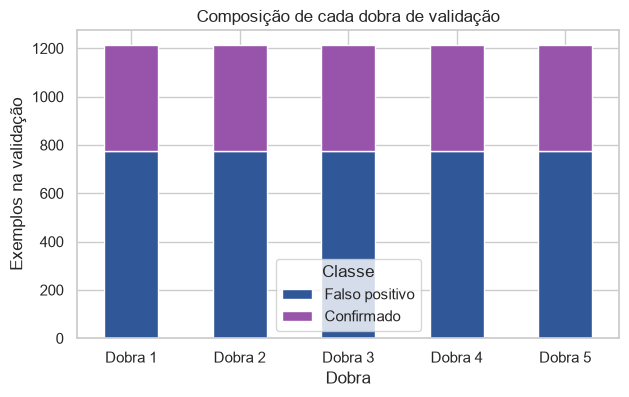

In [38]:
plota_composicao_dobras(cv, X_treino, y_treino, grupos_treino, PALETA_CLASSES)

As cinco dobras de validação têm praticamente a mesma composição, com 439 ou 440 confirmados e 774 ou 775 falsos positivos em cada uma. Assim, as diferenças de nota entre as dobras não podem ser atribuídas a uma dobra ter mais exemplos de uma classe do que outra.

### 5.3 Métricas e funções de avaliação

Cinco métricas são calculadas para cada modelo. Com a classe positiva sendo "confirmado" e usando VP, VN, FP e FN para verdadeiros positivos, verdadeiros negativos, falsos positivos e falsos negativos do modelo:

- **Acurácia:** fração de acertos, $\frac{VP + VN}{VP + VN + FP + FN}$. É intuitiva, mas pode ser enganosa com classes desbalanceadas (seção 6).
- **Acurácia balanceada:** média dos recalls das duas classes [27, 28],
$$
\text{AB} = \frac{1}{2}\left(\frac{VP}{VP+FN} + \frac{VN}{VN+FP}\right) .
$$
Ela dá o mesmo peso ao acerto de cada classe, e um classificador que chuta vale cerca de 0,5, independentemente do desbalanceamento.
- **F1 da classe confirmado:** média harmônica entre a precisão $P = \frac{VP}{VP+FP}$ e o recall $R = \frac{VP}{VP+FN}$, $F_1 = \frac{2PR}{P+R}$.
- **Precisão média:** resume a curva precisão-recall em todos os limiares de decisão. Assim como a ROC-AUC, ela é calculada a partir de um escore contínuo (a probabilidade prevista), e não da classe prevista.
- **ROC-AUC:** área sob a curva ROC, igual à probabilidade de um planeta sorteado ao acaso receber um escore maior que um falso positivo sorteado ao acaso.

A **métrica principal**, usada para otimizar os hiperparâmetros e escolher o modelo final, é a **acurácia balanceada**. A escolha foi feita no estudo preliminar (seção 5.6.2) e se baseou em três motivos: (1) entre as métricas testadas, ela foi a que mais claramente separou os dois melhores modelos; (2) ela é adequada para classes desbalanceadas; e (3) ela é fácil de interpretar. Nenhuma métrica é superior em todos os aspectos: o F1 e a precisão média também seriam escolhas defensáveis, enquanto a ROC-AUC fica muito próxima de 1 para todos os bons modelos e diferencia pouco entre eles.

In [39]:
METRICAS = {
    "acuracia": "accuracy",
    "acuracia_balanceada": "balanced_accuracy",
    "f1": make_scorer(f1_score, zero_division=0),
    "precisao_media": "average_precision",
    "roc_auc": "roc_auc",
}

METRICA_PRINCIPAL = "balanced_accuracy"

METRICAS_DO_GRAFICO = ["acuracia", "acuracia_balanceada", "f1", "precisao_media", "roc_auc"]
CORES_METRICAS = ["#8172B3", "#4C72B0", "#AC7A5C", "#3B7648", "#A04347"]

O dicionário `METRICAS` associa um nome em português a cada métrica do scikit-learn. O F1 é definido com `make_scorer(f1_score, zero_division=0)`: um modelo que nunca prevê a classe positiva (como o Dummy mais frequente, seção 6) tem precisão $\frac{0}{0}$, indefinida, e o argumento `zero_division=0` define essa precisão como zero, em vez de gerar um aviso. A constante `METRICA_PRINCIPAL` permite trocar a métrica de otimização em um único lugar, e `CORES_METRICAS` fixa uma cor para cada métrica nos gráficos.

In [40]:
def avalia_modelo(modelo, X, y, grupos, cv, metricas):

    resultados = cross_validate(modelo, X, y, groups=grupos, cv=cv, scoring=metricas, n_jobs=-1)

    notas = pd.DataFrame({nome: resultados[f"test_{nome}"] for nome in metricas})
    notas["tempo_treino_s"] = resultados["fit_time"]

    return notas

A função `avalia_modelo` usa o `cross_validate` do scikit-learn com as dobras agrupadas por estrela (`groups=grupos`) e calcula todas as métricas de uma vez. As dobras são processadas em paralelo (`n_jobs=-1`). Ela devolve uma tabela com uma linha por dobra, uma coluna por métrica e o tempo de ajuste do modelo em cada dobra (`tempo_treino_s`).

In [41]:
def resume_notas(notas_por_modelo):

    medias = pd.DataFrame({nome: notas.mean() for nome, notas in notas_por_modelo.items()}).T
    desvios = pd.DataFrame({nome: notas.std() for nome, notas in notas_por_modelo.items()}).T

    return medias, desvios

A função `resume_notas` resume as notas de vários modelos em duas tabelas: a **média** e o **desvio-padrão** de cada métrica entre as cinco dobras. O pandas calcula o desvio-padrão amostral, $s = \sqrt{\frac{1}{k-1}\sum_{i=1}^{k}(x_i - \bar{x})^2}$, com $k = 5$.

In [42]:
def formata_media_desvio(medias, desvios, casas):

    return medias.round(casas).astype(str) + " ± " + desvios.round(casas).astype(str)

A função `formata_media_desvio` apenas junta as duas tabelas no formato "média ± desvio", que é o formato usado nas tabelas de resultados.

In [43]:
def plota_metricas(medias, desvios, metricas, cores, titulo):

    eixo = medias[metricas].plot.bar(
        yerr=desvios[metricas],
        capsize=3,
        color=cores,
        rot=0,
        figsize=(10, 5),
    )
    eixo.set(
        xlabel="Modelo",
        ylabel="Nota (média das dobras)",
        title=titulo,
        ylim=(0, 1),
    )
    eixo.legend(title="Métrica", loc="upper left", bbox_to_anchor=(1.01, 1))

A função `plota_metricas` desenha, para cada modelo, uma barra por métrica com a média das dobras, e uma barra de erro com o desvio-padrão entre as dobras. O eixo vertical vai de 0 a 1, o intervalo de todas as métricas, para que as diferenças não sejam exageradas visualmente.

In [44]:
PASTA_CACHE = Path("results/cache")
RECALCULAR = False


def carrega_ou_calcula(caminho, funcao, *args, **kwargs):

    caminho = Path(caminho)

    if caminho.exists() and not RECALCULAR:
        return pd.read_csv(caminho)

    resultado = funcao(*args, **kwargs)

    caminho.parent.mkdir(parents=True, exist_ok=True)
    resultado.to_csv(caminho, index=False)

    return resultado


def avalia_varios_modelos(modelos, X, y, grupos, cv, metricas):

    tabelas = [
        avalia_modelo(modelo, X, y, grupos, cv, metricas).assign(modelo=nome)
        for nome, modelo in modelos.items()
    ]
    return pd.concat(tabelas, ignore_index=True)


def separa_por_modelo(tabela):

    return {
        nome: grupo.drop(columns="modelo").reset_index(drop=True)
        for nome, grupo in tabela.groupby("modelo", sort=False)
    }

Algumas avaliações deste notebook levam minutos. Para não refazê-las a cada execução, a função `carrega_ou_calcula` salva o resultado em um arquivo CSV em `results/cache/` na primeira vez e apenas o lê nas execuções seguintes. Os números não mudam entre execuções, porque as sementes são fixas. Para refazer as contas, basta apagar o arquivo correspondente ou trocar `RECALCULAR` para `True`. Se um modelo, uma métrica ou as dobras forem alterados, o arquivo correspondente precisa ser apagado; do contrário, o notebook continuará mostrando o resultado antigo.

As funções `avalia_varios_modelos` e `separa_por_modelo` adaptam `avalia_modelo` ao cache: a primeira avalia vários modelos e junta tudo em uma única tabela (que pode ser salva em CSV), e a segunda separa essa tabela de volta em um dicionário com um modelo por chave.

### 5.4 Espaços de busca

Os hiperparâmetros são escolhidos com o **Optuna** [25, 29]. Cada **trial** é um conjunto de hiperparâmetros (incluindo as escolhas de pré-processamento) avaliado pela **média da acurácia balanceada nas cinco dobras** da validação cruzada, usando apenas o conjunto de treino.

O amostrador usado é o **TPE** (*Tree-structured Parzen Estimator*) [30]. A cada novo trial, ele separa os trials anteriores em um grupo "bom" (as melhores notas) e um grupo "ruim", estima a densidade dos hiperparâmetros em cada grupo, $\ell(x)$ e $g(x)$, e sorteia o próximo trial onde a razão $\ell(x)/g(x)$ é alta, isto é, em regiões parecidas com as dos bons trials e diferentes das dos ruins. Isso é muito mais eficiente que uma busca em grade: com 5 hiperparâmetros e 10 valores cada, a grade teria $10^5$ combinações. Foram usadas as opções `multivariate=True`, que modela os hiperparâmetros em conjunto, e `group=True`, necessária porque o espaço é condicional.

Foram feitos **100 trials completos por algoritmo**, como exige o enunciado. O primeiro trial de cada estudo usa os hiperparâmetros padrão do scikit-learn (ou o valor mais próximo dentro da faixa), o que permite medir quanto a otimização melhorou em relação a eles.

Hiperparâmetros que variam em ordens de grandeza (como $C$ e $\gamma$ do SVM) são sorteados em **escala logarítmica**: sorteia-se o expoente, e cada ordem de grandeza tem a mesma chance. Em escala linear, com $C$ uniforme em $[0{,}01;\,1000]$, cerca de 90% dos sorteios cairiam acima de 100, e a região de valores pequenos quase não seria explorada.

A tabela abaixo reúne os 24 hiperparâmetros otimizados, com a faixa, a escala e a justificativa de cada um.

In [45]:
LINHAS_ESPACO_DE_BUSCA = [
    ("Pré-processamento", "adiciona_indicador_faltante", "True ou False", "-",
     "O faltante é informativo: é bem mais frequente nos falsos positivos em colunas como koi_bin_oedp_sig."),
    ("Pré-processamento", "normalizacao", "padrao, robusto ou potencia", "-",
     "Há atributos com caudas muito pesadas (assimetria de até cerca de 49); compara padronização, escala robusta e Yeo-Johnson."),
    ("Pré-processamento", "reducao", "nenhuma, pca, vif ou rfe", "-",
     "Há 31 pares de atributos com |rho| >= 0,95, o que motiva a redução de redundância."),
    ("Pré-processamento", "pca_variancia_explicada", "0,80 a 0,999", "linear",
     "Mantém de 80% até quase toda a variância."),
    ("Pré-processamento", "vif_limiar", "2 a 100", "log",
     "VIF entre 5 e 10 é a regra usual; a faixa larga vai de seleção agressiva a quase nenhuma."),
    ("Pré-processamento", "rfe_fracao_mantida", "0,2 a 0,9", "linear",
     "Fração dos atributos que sobra na eliminação recursiva."),
    ("kNN", "knn_num_vizinhos", "1 a 50", "linear",
     "Poucos vizinhos dão variância alta; muitos suavizam demais a fronteira."),
    ("kNN", "knn_pesos", "uniform ou distance", "-", "Vizinhos mais próximos podem pesar mais."),
    ("kNN", "knn_p", "1 ou 2", "-", "Distância de Manhattan ou euclidiana."),
    ("Árvore", "arvore_criterio", "gini ou entropy", "-", "Duas medidas usuais de impureza."),
    ("Árvore", "arvore_profundidade_maxima", "2 a 30", "linear", "Controla a complexidade da árvore."),
    ("Árvore", "arvore_min_exemplos_folha", "1 a 50", "log", "Evita folhas com poucos exemplos."),
    ("Árvore", "arvore_ccp_alpha", "1e-5 a 1e-1", "log", "Poda por custo-complexidade; varia em ordens de grandeza."),
    ("Floresta", "floresta_num_arvores", "100 a 300", "linear", "Mais árvores estabilizam, com ganho decrescente e custo crescente."),
    ("Floresta", "floresta_profundidade_maxima", "3 a 30", "linear", "Controla o sobreajuste de cada árvore."),
    ("Floresta", "floresta_min_exemplos_folha", "1 a 20", "linear", "Regulariza as folhas."),
    ("Floresta", "floresta_fracao_atributos", "0,1 a 1,0", "linear",
     "Fração de atributos sorteada em cada corte; 0,1 é próximo de raiz(89)/89."),
    ("Gradient Boosting", "gb_taxa_aprendizado", "0,01 a 0,3", "log", "Taxa e número de iterações se compensam."),
    ("Gradient Boosting", "gb_num_iteracoes", "100 a 500", "linear", "Número de árvores em sequência."),
    ("Gradient Boosting", "gb_max_folhas", "8 a 64", "linear", "Complexidade de cada árvore."),
    ("Gradient Boosting", "gb_min_exemplos_folha", "10 a 100", "linear", "Evita folhas pequenas."),
    ("Gradient Boosting", "gb_l2", "1e-6 a 10", "log", "Regularização L2 dos pesos das folhas."),
    ("SVM", "svm_c", "1e-2 a 1e3", "log", "Penalidade dos erros; varia em ordens de grandeza."),
    ("SVM", "svm_gamma", "1e-4 a 1e1", "log", "Alcance de cada exemplo no kernel RBF; varia em ordens de grandeza."),
]

ESPACOS_DE_BUSCA = pd.DataFrame(
    LINHAS_ESPACO_DE_BUSCA,
    columns=["etapa_ou_algoritmo", "hiperparametro", "faixa", "escala", "justificativa"],
)

ESPACOS_DE_BUSCA

,etapa_ou_algoritmo,hiperparametro,faixa,escala,justificativa
0,Pré-processamento,adiciona_indicador_faltante,True ou False,-,O faltante é informativo: é bem mais frequente...
1,Pré-processamento,normalizacao,"padrao, robusto ou potencia",-,Há atributos com caudas muito pesadas (assimet...
2,Pré-processamento,reducao,"nenhuma, pca, vif ou rfe",-,"Há 31 pares de atributos com |rho| >= 0,95, o ..."
3,Pré-processamento,pca_variancia_explicada,"0,80 a 0,999",linear,Mantém de 80% até quase toda a variância.
4,Pré-processamento,vif_limiar,2 a 100,log,VIF entre 5 e 10 é a regra usual; a faixa larg...
5,Pré-processamento,rfe_fracao_mantida,"0,2 a 0,9",linear,Fração dos atributos que sobra na eliminação r...
6,kNN,knn_num_vizinhos,1 a 50,linear,Poucos vizinhos dão variância alta; muitos sua...
7,kNN,knn_pesos,uniform ou distance,-,Vizinhos mais próximos podem pesar mais.
8,kNN,knn_p,1 ou 2,-,Distância de Manhattan ou euclidiana.
9,Árvore,arvore_criterio,gini ou entropy,-,Duas medidas usuais de impureza.


Dos 24 hiperparâmetros, 6 são do pré-processamento e valem para todos os algoritmos, e 18 são específicos dos modelos. Os três hiperparâmetros da redução (`pca_variancia_explicada`, `vif_limiar` e `rfe_fracao_mantida`) são condicionais e só existem quando a técnica correspondente é escolhida. As faixas foram definidas para incluir o valor padrão do scikit-learn e se estender, nos dois sentidos, até configurações claramente mais simples e mais complexas. A única exceção deliberada é o número de árvores da floresta, limitado a 300 por causa do custo computacional (seção 5.5).

### 5.5 Estimativa de tempo da otimização

Antes de iniciar os 500 trials (100 por algoritmo), foi feita uma estimativa do tempo necessário, rodando alguns trials sorteados ao acaso e extrapolando para 100.

In [46]:
NUM_TRIALS_TESTE = 2
NUM_TRIALS_FINAL = 100
ALGORITMOS_TESTE = ["knn", "arvore"]

`NUM_TRIALS_TESTE = 2` define quantos trials aleatórios são usados na estimativa, e `NUM_TRIALS_FINAL = 100` é o número de trials da otimização real. A estimativa foi feita apenas para o kNN e a árvore (`ALGORITMOS_TESTE`), porque cada trial da floresta leva vários minutos.

In [47]:
def mede_tempo_por_trial(nome_algoritmo, X, y, grupos, cv, metrica, num_trials, semente_aleatoria):

    estudo = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.RandomSampler(seed=semente_aleatoria),
    )

    inicio = time.time()

    estudo.optimize(
        partial(
            funcao_objetivo,
            nome_algoritmo=nome_algoritmo,
            X=X,
            y=y,
            grupos=grupos,
            cv=cv,
            metrica=metrica,
            semente_aleatoria=semente_aleatoria,
        ),
        n_trials=num_trials,
    )

    tempo_medio = (time.time() - inicio) / num_trials

    return {
        "algoritmo": nome_algoritmo,
        "melhor_nota": estudo.best_value,
        "tempo_medio_por_trial_s": tempo_medio,
        "tempo_estimado_min": tempo_medio * NUM_TRIALS_FINAL / 60,
    }

A função `mede_tempo_por_trial` cria um estudo temporário do Optuna com um amostrador aleatório (`RandomSampler`), roda alguns trials com a mesma função objetivo da otimização real e mede o tempo médio por trial. O tempo estimado para 100 trials é esse tempo médio multiplicado por 100.

In [48]:
estimativas = carrega_ou_calcula(
    PASTA_CACHE / "estimativas_tempo.csv",
    lambda: pd.DataFrame([
        mede_tempo_por_trial(nome, X_treino, y_treino, grupos_treino, cv, METRICA_PRINCIPAL,
                             NUM_TRIALS_TESTE, SEMENTE_ALEATORIA)
        for nome in ALGORITMOS_TESTE
    ]),
)

estimativas.round(2)

,algoritmo,melhor_nota,tempo_medio_por_trial_s,tempo_estimado_min
0,knn,0.94,4.34,7.23
1,arvore,0.93,26.54,44.23


Com apenas dois trials por algoritmo, a estimativa foi de **cerca de 4,3 s por trial para o kNN** (≈ 7 min para 100 trials) e **cerca de 26,5 s para a árvore** (≈ 44 min).

Na prática, a otimização levou bem mais tempo. No computador principal, a árvore levou cerca de 1 h 45 min (do primeiro ao último trial registrado no terminal, das 15:05 às 16:50), e o kNN passou de uma hora. A estimativa errou por três motivos: (1) dois trials sorteados ao acaso são uma amostra muito pequena, já que a duração varia muito com as escolhas de pré-processamento; (2) o TPE concentra a busca nas regiões com boas notas, que no kNN e na árvore incluem as opções mais lentas, como a transformação de potência, o RFE e o VIF (o Teste B, seção 5.6.3, mostra que a transformação de potência é várias vezes mais lenta que a padronização); e (3) o computador era usado para outras tarefas ao mesmo tempo.

Por isso, a otimização foi dividida entre dois computadores, com as mesmas versões das bibliotecas (scikit-learn 1.9.0, Optuna 5.0.0, pandas 3.0.5 e NumPy 2.4.6): o kNN e a árvore foram otimizados no computador principal, e a floresta, o gradient boosting e o SVM, em um computador com processador mais rápido. Nele, a floresta levou cerca de 18 minutos. Os tempos não são comparáveis entre os dois computadores, mas as notas são, porque não dependem da máquina (ver a ressalva da seção 8.2).

### 5.6 Estudo preliminar de desenho

#### 5.6.1 Objetivos e cuidados

Antes da otimização, foi feito um **estudo preliminar**, com três testes, para orientar as decisões de desenho:

- **Teste A:** os cinco algoritmos com hiperparâmetros padrão, para ter uma referência inicial e escolher a métrica principal;
- **Teste B:** um kNN fixo com todas as combinações de pré-processamento, para entender o efeito de cada opção e o seu custo;
- **Teste C:** a verificação do seletor por VIF implementado neste trabalho.

Dois cuidados foram tomados. Primeiro, o estudo usa **apenas o conjunto de treino**, com as mesmas dobras da validação cruzada. Segundo, seus resultados **não são resultados finais**: os hiperparâmetros são padrão ou fixos, e o estudo serve apenas para orientar o desenho do experimento. Usar o estudo preliminar para ajustar os modelos e depois relatar essas mesmas notas como desempenho final seria uma forma de sobreajuste à validação [31].

#### 5.6.2 Teste A: modelos com hiperparâmetros padrão

O primeiro teste avalia os cinco algoritmos com os **hiperparâmetros padrão** do scikit-learn, na mesma validação cruzada de cinco dobras. Ele tem dois objetivos: obter uma referência do desempenho de cada algoritmo antes da otimização e comparar as métricas candidatas a métrica principal.

In [49]:
MODELOS_PADRAO = {
    "kNN": make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier()
    ),
    "Árvore": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(random_state=SEMENTE_ALEATORIA),
    ),
    "Floresta": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEMENTE_ALEATORIA),
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=SEMENTE_ALEATORIA),
    "SVM": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVC()),
}

Cada algoritmo recebe um pipeline mínimo, com as etapas necessárias para funcionar:

- **kNN e SVM:** imputação pela mediana e padronização, porque dependem da escala;
- **árvore e floresta:** apenas imputação pela mediana. A floresta usa 200 árvores (o padrão do scikit-learn é 100);
- **gradient boosting:** o `HistGradientBoostingClassifier` sem nenhuma etapa adicional, porque ele aceita valores faltantes diretamente: em cada corte, os exemplos com valor faltante são enviados para o lado que mais melhora o ajuste.

In [50]:
notas_padrao = separa_por_modelo(
    carrega_ou_calcula(
        PASTA_CACHE / "notas_teste_A.csv",
        avalia_varios_modelos,
        MODELOS_PADRAO, X_treino, y_treino, grupos_treino, cv, METRICAS,
    )
)

medias_padrao, desvios_padrao = resume_notas(notas_padrao)

A avaliação usa o cache (`results/cache/notas_teste_A.csv`), e `resume_notas` calcula a média e o desvio-padrão de cada métrica.

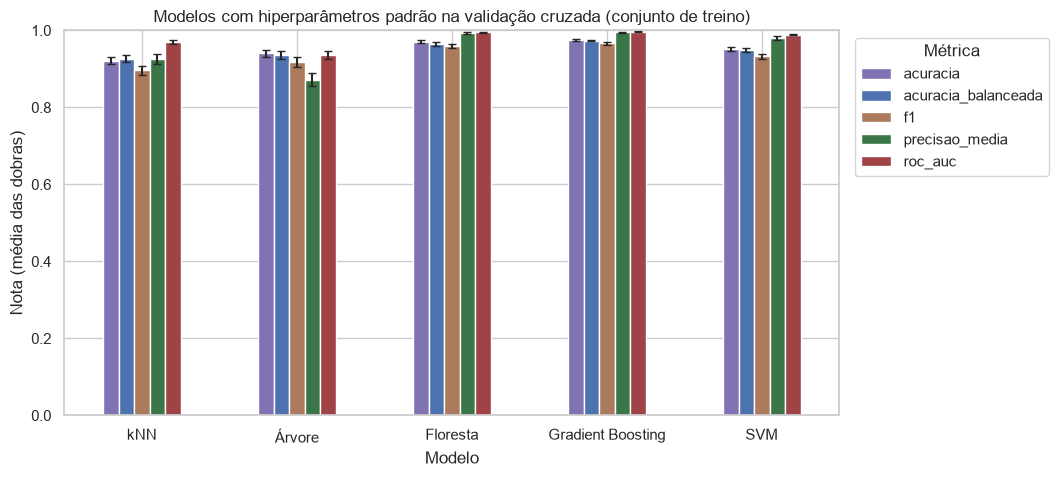

In [51]:
plota_metricas(
    medias_padrao, desvios_padrao, METRICAS_DO_GRAFICO, CORES_METRICAS,
    "Modelos com hiperparâmetros padrão na validação cruzada (conjunto de treino)",
)

Com os hiperparâmetros padrão, os resultados de acurácia balanceada / F1 / precisão média / ROC-AUC foram:

| Algoritmo | Acur. balanceada | F1 | Precisão média | ROC-AUC |
|---|---|---|---|---|
| Gradient Boosting | 0,973 | 0,966 | 0,995 | 0,996 |
| Floresta | 0,965 | 0,959 | 0,992 | 0,995 |
| SVM | 0,949 | 0,933 | 0,980 | 0,988 |
| Árvore | 0,936 | 0,918 | 0,871 | 0,936 |
| kNN | 0,926 | 0,897 | 0,925 | 0,970 |

Os dois modelos baseados em conjuntos de árvores (gradient boosting e floresta) lideram em todas as métricas. A árvore isolada tem a menor precisão média e a menor ROC-AUC: como ela atribui a mesma probabilidade a todos os exemplos de uma folha, seus escores têm poucos valores distintos, o que prejudica as métricas que dependem da ordenação. O kNN tem a menor acurácia balanceada, o que é compatível com a sua sensibilidade a atributos assimétricos e redundantes (seções 4.3 e 4.6).

In [52]:
medias_padrao["tempo_treino_s"].round(2)

kNN                  0.26
Árvore               0.81
Floresta             4.19
Gradient Boosting    5.31
SVM                  1.39
Name: tempo_treino_s, dtype: float64

O tempo médio de ajuste por dobra, neste computador e com as dobras processadas em paralelo, foi de 0,26 s para o kNN, 0,81 s para a árvore, 4,19 s para a floresta, 5,31 s para o gradient boosting e 1,39 s para o SVM. Esses tempos dão apenas uma ideia do custo relativo, porque dependem do computador e da carga de trabalho no momento da execução.

In [53]:
def calcula_separacao(notas_por_modelo, modelo_a, modelo_b, metricas):

    linhas = []

    for metrica in metricas:
        diferencas = notas_por_modelo[modelo_a][metrica] - notas_por_modelo[modelo_b][metrica]

        linhas.append({
            "metrica": metrica,
            "diferenca_media": diferencas.mean(),
            "desvio_da_diferenca": diferencas.std(),
            "separacao": diferencas.mean() / diferencas.std(),
            "dobras_a_favor_de_a": int((diferencas > 0).sum()),
        })

    return pd.DataFrame(linhas)

Para comparar dois modelos, não basta olhar a diferença das médias: é preciso saber se ela é grande em relação à variação entre as dobras. A função `calcula_separacao` usa o fato de que os dois modelos foram avaliados **nas mesmas dobras**. Para cada dobra $i$, calcula-se a diferença $d_i = s_{A,i} - s_{B,i}$ entre as notas dos modelos $A$ e $B$, e a separação é

$$
\text{separação} = \frac{\bar{d}}{s_d} ,
$$

a média das diferenças dividida pelo seu desvio-padrão. A função também conta em quantas dobras o modelo $A$ venceu.

Comparar as diferenças dobra a dobra elimina a variação que é comum aos dois modelos (por exemplo, uma dobra mais difícil para os dois). A separação lembra a estatística do teste $t$ pareado, $t = \bar{d}/(s_d/\sqrt{k}) = \text{separação} \times \sqrt{k}$; com $k = 5$, uma separação de 2 corresponde a $t \approx 4{,}5$. Ela é usada aqui apenas como um **indicador**, e não como um teste formal, porque as dobras compartilham exemplos de treino e não são independentes. Neste trabalho, uma separação acima de 2 com as 5 dobras a favor é interpretada como uma vantagem consistente.

In [54]:
METRICAS_COMPARADAS = ["acuracia_balanceada", "f1", "precisao_media", "roc_auc"]

calcula_separacao(notas_padrao, "Gradient Boosting", "Floresta", METRICAS_COMPARADAS).round(3)

,metrica,diferenca_media,desvio_da_diferenca,separacao,dobras_a_favor_de_a
0,acuracia_balanceada,0.008,0.005,1.750,5
1,f1,0.007,0.006,1.135,4
2,precisao_media,0.002,0.002,1.245,4
3,roc_auc,0.002,0.001,1.193,4


Entre os dois melhores modelos (gradient boosting e floresta), a separação foi de **1,75 na acurácia balanceada, com as 5 dobras a favor do gradient boosting**, contra 1,14 no F1, 1,25 na precisão média e 1,19 na ROC-AUC, essas três com 4 de 5 dobras a favor. A acurácia balanceada foi a métrica que mais claramente distinguiu os dois modelos, o que, junto com sua adequação a classes desbalanceadas, motivou sua escolha como métrica principal (seção 5.3).

In [55]:
calcula_separacao(notas_padrao, "Floresta", "SVM", METRICAS_COMPARADAS).round(3)

,metrica,diferenca_media,desvio_da_diferenca,separacao,dobras_a_favor_de_a
0,acuracia_balanceada,0.017,0.007,2.375,5
1,f1,0.027,0.010,2.542,5
2,precisao_media,0.012,0.004,2.741,5
3,roc_auc,0.006,0.002,3.484,5


Entre a floresta e o SVM, a separação foi clara em todas as métricas (2,38 na acurácia balanceada, 2,54 no F1, 2,74 na precisão média e 3,48 na ROC-AUC), com as 5 dobras a favor da floresta. Ou seja, com os hiperparâmetros padrão, os conjuntos de árvores formam um grupo claramente superior aos demais modelos, enquanto a diferença dentro desse grupo é menor.

#### 5.6.3 Teste B: combinações de pré-processamento

O segundo teste investiga o efeito das opções de pré-processamento. Para isolar esse efeito, o modelo é mantido **fixo** (um kNN com 15 vizinhos, votos ponderados pela distância e distância de Manhattan) e variam-se as três escolhas do pré-processamento: indicador de faltante (sim ou não), redução (nenhuma, PCA, VIF ou RFE) e normalização (padronização, robusta ou potência), num total de $2 \times 4 \times 3 = 24$ combinações. O kNN foi escolhido por ser o algoritmo mais sensível à escala e à redundância dos atributos. Além da nota, mede-se o tempo de cada combinação.

In [56]:
OPCOES_INDICADOR = [True, False]
PARAMETROS_REDUCAO = {
    "nenhuma": {},
    "pca": {"pca_variancia_explicada": 0.95},
    "vif": {"vif_limiar": 10.0},
    "rfe": {"rfe_fracao_mantida": 0.5},
}
PARAMETROS_KNN = {"knn_num_vizinhos": 15, "knn_pesos": "distance", "knn_p": 1}

`PARAMETROS_REDUCAO` fixa um valor intermediário para cada técnica de redução: 95% da variância explicada no PCA, limiar 10 no VIF (um valor usual na literatura [23]) e metade dos atributos no RFE. `PARAMETROS_KNN` fixa os hiperparâmetros do kNN.

In [57]:
def testa_combinacoes_preprocessamento(X, y, grupos, cv, metrica, semente_aleatoria):

    linhas = []

    for indicador, reducao, normalizacao in itertools.product(
        OPCOES_INDICADOR, OPCOES_REDUCAO, OPCOES_NORMALIZACAO
    ):
        parametros = {
            "adiciona_indicador_faltante": indicador,
            "reducao": reducao,
            "normalizacao": normalizacao,
            **PARAMETROS_KNN,
            **PARAMETROS_REDUCAO[reducao],
        }

        pipeline = cria_instancia_modelo(
            optuna.trial.FixedTrial(parametros), "knn", semente_aleatoria
        )

        inicio = time.time()

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            notas = cross_val_score(pipeline, X, y, groups=grupos, cv=cv, scoring=metrica)

        linhas.append({
            "indicador_faltante": indicador,
            "reducao": reducao,
            "normalizacao": normalizacao,
            "nota": notas.mean(),
            "tempo_s": time.time() - inicio,
        })

    return pd.DataFrame(linhas)

A função `testa_combinacoes_preprocessamento` percorre as 24 combinações com `itertools.product`. Para cada uma, monta o pipeline com a mesma função usada na otimização (`cria_instancia_modelo`), passando as escolhas por um `optuna.trial.FixedTrial`, um "trial" com valores fixos em vez de sorteados. Assim, o pipeline testado é exatamente o que o Optuna montaria com essas escolhas. A nota é a média da acurácia balanceada nas cinco dobras, e o tempo inclui as cinco dobras.

In [58]:
combinacoes = carrega_ou_calcula(
    PASTA_CACHE / "combinacoes_teste_B.csv",
    testa_combinacoes_preprocessamento,
    X_treino, y_treino, grupos_treino, cv, METRICA_PRINCIPAL, SEMENTE_ALEATORIA,
)

combinacoes.round(3)

,indicador_faltante,reducao,normalizacao,nota,tempo_s
0,True,nenhuma,padrao,0.932,5.939
1,True,nenhuma,robusto,0.940,4.214
2,True,nenhuma,potencia,0.957,46.670
3,True,pca,padrao,0.933,13.361
4,True,pca,robusto,0.652,14.445
5,True,pca,potencia,0.955,56.612
6,True,vif,padrao,0.933,36.682
7,True,vif,robusto,0.942,44.538
8,True,vif,potencia,0.955,90.799
9,True,rfe,padrao,0.936,8.808


A melhor combinação foi **RFE com transformação de potência e sem indicador de faltante**, com acurácia balanceada de **0,967**. Dois padrões chamam a atenção: em quase todas as linhas, a transformação de potência dá a maior nota; e as combinações de **PCA com escala robusta** desabam para cerca de **0,65**, muito abaixo de todas as outras.

In [59]:
def plota_combinacoes(combinacoes, mapa_de_cor):

    fig, eixos = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

    for eixo, indicador in zip(eixos, OPCOES_INDICADOR):
        dados = combinacoes[combinacoes["indicador_faltante"] == indicador]
        tabela = dados.pivot(index="reducao", columns="normalizacao", values="nota")
        tabela = tabela.reindex(index=OPCOES_REDUCAO, columns=OPCOES_NORMALIZACAO)

        sns.heatmap(
            tabela, annot=True, fmt=".3f", cmap=mapa_de_cor,
            vmin=0.9, vmax=0.97, ax=eixo, cbar=False,
        )
        eixo.set(
            xlabel="Normalização",
            ylabel="Redução",
            title=f"Indicador de faltante: {indicador}",
        )

    fig.suptitle("kNN: acurácia balanceada por combinação de pré-processamento", fontsize=13)
    fig.tight_layout()

A função `plota_combinacoes` organiza as 24 notas em dois mapas de calor, um para cada opção do indicador de faltante, com a redução nas linhas e a normalização nas colunas. A escala de cores vai de 0,90 a 0,97, para destacar as diferenças entre as boas combinações; valores abaixo de 0,90 ficam todos com a cor do extremo inferior.

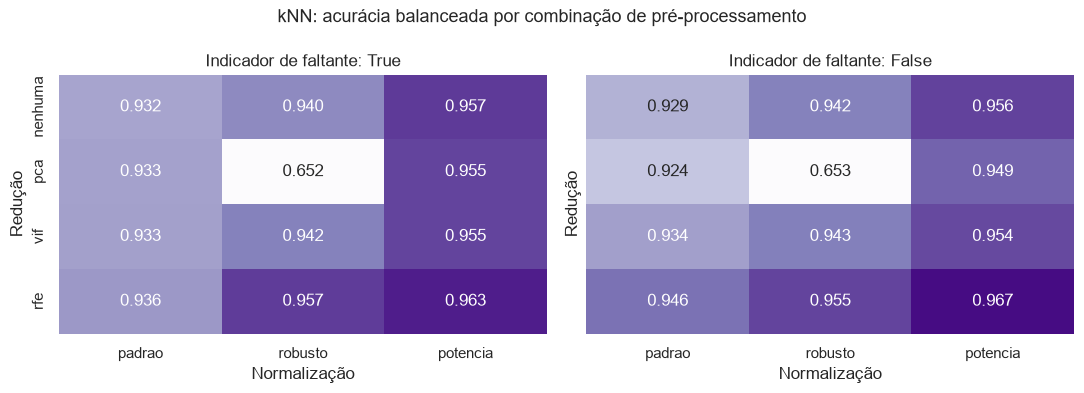

In [60]:
MAPA_DE_COR_COMBINACOES = "Purples"

plota_combinacoes(combinacoes, MAPA_DE_COR_COMBINACOES)

Os mapas mostram que a **normalização** é o fator mais importante: nos dois mapas, a coluna da transformação de potência tem as maiores notas. A **redução por RFE** é a melhor linha nos dois mapas. O indicador de faltante muda pouco as notas.

O colapso do PCA com escala robusta tem uma explicação. O `RobustScaler` centraliza pela mediana e divide pelo intervalo interquartil, mas **não limita os valores extremos**: em atributos muito assimétricos (seção 4.3), um valor extremo continua extremo depois da transformação. Como o PCA busca as direções de **maior variância**, essas direções passam a ser dominadas pelos poucos exemplos extremos, e os componentes mantidos deixam de representar a maior parte dos dados. A transformação de potência, por outro lado, reduz a assimetria antes do PCA e evita o problema.

In [61]:
def resume_efeito_por_fator(combinacoes, fatores):

    linhas = []

    for fator in fatores:
        resumo = combinacoes.groupby(fator).agg(
            nota_mediana=("nota", "median"),
            nota_maxima=("nota", "max"),
            tempo_medio_s=("tempo_s", "mean"),
        )

        for opcao, linha in resumo.iterrows():
            linhas.append({"fator": fator, "opcao": opcao, **linha.to_dict()})

    return pd.DataFrame(linhas)

A função `resume_efeito_por_fator` resume o efeito de cada opção: para cada fator, agrupa as combinações pela opção escolhida e calcula a **mediana** da nota (menos sensível aos colapsos do PCA com escala robusta do que a média), a nota máxima e o tempo médio.

In [62]:
FATORES = ["indicador_faltante", "reducao", "normalizacao"]

resume_efeito_por_fator(combinacoes, FATORES).round(3)

,fator,opcao,nota_mediana,nota_maxima,tempo_medio_s
0,indicador_faltante,False,0.944,0.967,14.887
1,indicador_faltante,True,0.941,0.963,34.564
2,reducao,nenhuma,0.941,0.957,14.649
3,reducao,pca,0.928,0.955,19.141
4,reducao,rfe,0.956,0.967,30.083
5,reducao,vif,0.942,0.955,35.029
6,normalizacao,padrao,0.933,0.946,10.346
7,normalizacao,potencia,0.955,0.967,43.964
8,normalizacao,robusto,0.942,0.957,19.866


Os resumos por fator confirmam a leitura dos mapas:

- **Normalização:** mediana de 0,955 com a transformação de potência, contra 0,942 com a escala robusta e 0,933 com a padronização. Em compensação, a transformação de potência foi a mais lenta: em média, cerca de 44 s por combinação, contra cerca de 10 s da padronização.
- **Redução:** o RFE teve a maior mediana (0,956), seguido do VIF (0,942), de nenhuma redução (0,941) e do PCA (0,928).
- **Indicador de faltante:** medianas de 0,944 sem o indicador e 0,941 com ele, uma diferença pequena. Com o indicador, o tempo médio foi maior, porque ele acrescenta colunas.

Os tempos foram medidos neste computador e servem apenas para comparar as opções entre si.

In [63]:
combinacoes.sort_values("nota", ascending=False).head(3).round(3)

,indicador_faltante,reducao,normalizacao,nota,tempo_s
23,False,rfe,potencia,0.967,27.718
11,True,rfe,potencia,0.963,49.388
2,True,nenhuma,potencia,0.957,46.670


As três melhores combinações usam a transformação de potência, e as duas primeiras usam o RFE. Isso indica que, para o kNN, reduzir a assimetria e remover atributos pouco informativos são as escolhas que mais ajudam. Como o efeito de cada opção pode ser diferente para outros algoritmos (as árvores, por exemplo, não dependem da escala), **todas as opções foram mantidas no espaço de busca do Optuna**, inclusive o PCA com escala robusta, e a escolha final ficou a cargo da otimização de cada algoritmo.

#### 5.6.4 Teste C: o seletor por VIF

A seleção por **VIF** (*variance inflation factor*) não existe no scikit-learn, e o material da disciplina usa o `statsmodels` para calculá-la [23]. Para que ela pudesse entrar em um pipeline, foi implementado o componente `SelecionadorVIF` (`src/pipelines.py`), que calcula o VIF a partir da inversa da matriz de correlação. Este teste verifica se essa implementação está correta e quantos atributos ela mantém para cada limiar.

In [64]:
def confere_vif(X, atributos):

    X_imputado = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X), columns=X.columns)
    dados = X_imputado.reindex(atributos, axis=1).to_numpy()

    vif_inversa = np.diag(np.linalg.inv(np.corrcoef(dados, rowvar=False)))

    vif_regressao = []
    for j in range(dados.shape[1]):
        outros = np.column_stack([np.ones(len(dados)), np.delete(dados, j, axis=1)])
        coeficientes, *_ = np.linalg.lstsq(outros, dados[:, j], rcond=None)

        residuos = dados[:, j] - outros @ coeficientes
        r2 = 1 - (residuos ** 2).sum() / ((dados[:, j] - dados[:, j].mean()) ** 2).sum()

        vif_regressao.append(1 / (1 - r2))

    return pd.DataFrame({
        "atributo": atributos,
        "vif_inversa": vif_inversa,
        "vif_regressao": vif_regressao,
    })

A função `confere_vif` calcula o VIF de seis atributos de duas formas:

1. **por regressão**, pela definição: cada atributo $j$ é previsto por uma regressão linear nos demais, e $\text{VIF}_j = \frac{1}{1 - R_j^2}$;
2. **pela inversa da matriz de correlação**, como no `SelecionadorVIF`: $\text{VIF}_j = (R^{-1})_{jj}$.

As duas formas são equivalentes. Escrevendo a matriz de correlação com o atributo $j$ separado dos demais,
$$
R = \begin{pmatrix} 1 & r_j^\top \\ r_j & R_{-j} \end{pmatrix},
$$
a fórmula da inversa em blocos (complemento de Schur) dá $(R^{-1})_{jj} = \frac{1}{1 - r_j^\top R_{-j}^{-1} r_j}$, e, para variáveis padronizadas, $r_j^\top R_{-j}^{-1} r_j$ é exatamente o $R_j^2$ da regressão do atributo $j$ nos demais. A forma pela inversa é muito mais rápida, porque uma única inversão dá o VIF de todos os atributos ao mesmo tempo.

In [65]:
ATRIBUTOS_VIF = ["koi_period", "koi_depth", "koi_prad", "koi_steff", "koi_srad", "koi_model_snr"]

confere_vif(X_treino, ATRIBUTOS_VIF).round(3)

,atributo,vif_inversa,vif_regressao
0,koi_period,1.014,1.014
1,koi_depth,1.490,1.490
2,koi_prad,1.010,1.010
3,koi_steff,1.044,1.044
4,koi_srad,1.020,1.020
5,koi_model_snr,1.505,1.505


As duas colunas coincidem até a terceira casa decimal (1,014; 1,490; 1,010; 1,044; 1,020; 1,505), o que confirma a implementação. Para esses seis atributos, os valores são baixos (todos menores que 2), porque eles foram escolhidos entre os pouco correlacionados entre si.

In [66]:
def conta_atributos_vif(X, limiares):
    X_imputado = SimpleImputer(strategy="median").fit_transform(X)

    linhas = []
    for limiar in limiares:
        selecionador = SelecionadorVIF(limiar=limiar).fit(X_imputado)

        linhas.append({
            "limiar_vif": limiar,
            "atributos_mantidos": len(selecionador.colunas_mantidas_),
            "atributos_totais": X_imputado.shape[1],
        })

    return pd.DataFrame(linhas)

A função `conta_atributos_vif` imputa os faltantes pela mediana, aplica o `SelecionadorVIF` com cada limiar e conta quantos atributos sobram. Não é necessário normalizar antes: a correlação de Pearson não muda com transformações lineares de cada atributo, $\text{corr}(aX + b,\, cY + d) = \text{corr}(X, Y)$ para $a, c > 0$, e portanto o VIF também não muda.

In [67]:
def lista_atributos_removidos_vif(X, limiar):

    X_imputado = SimpleImputer(strategy="median").fit_transform(X)
    selecionador = SelecionadorVIF(limiar=limiar).fit(X_imputado)

    mantidos = set(selecionador.colunas_mantidas_)

    return [nome for posicao, nome in enumerate(X.columns) if posicao not in mantidos]

A função `lista_atributos_removidos_vif` faz o mesmo processo para um único limiar e devolve os nomes dos atributos removidos.

In [68]:
LIMIARES_VIF = [2, 5, 10, 50, 100]

conta_atributos_vif(X_treino, LIMIARES_VIF)

,limiar_vif,atributos_mantidos,atributos_totais
0,2,41,89
1,5,51,89
2,10,63,89
3,50,74,89
4,100,76,89


Com os limiares 2, 5, 10, 50 e 100, o seletor mantém, respectivamente, **41, 51, 63, 74 e 76** dos 89 atributos. Mesmo com o limiar mais permissivo (100), 13 atributos são removidos, o que confirma a forte redundância encontrada na seção 4.6. A faixa de busca do limiar no Optuna (de 2 a 100, em escala logarítmica) cobre, portanto, desde uma seleção agressiva, que remove mais da metade dos atributos, até uma seleção leve.

In [69]:
removidos = lista_atributos_removidos_vif(X_treino, 10)

print(len(removidos), removidos)

26 ['koi_gmag', 'koi_rmag', 'koi_imag', 'koi_jmag', 'koi_hmag', 'koi_kepmag', 'koi_ldm_coeff1', 'koi_prad', 'koi_sma', 'koi_duration_err2', 'koi_depth_err2', 'koi_period_err2', 'koi_ror', 'koi_ror_err1', 'koi_ror_err2', 'koi_dor_err2', 'koi_srad', 'koi_smass', 'koi_fwm_sra_err', 'koi_fwm_sdec_err', 'koi_fwm_sdeco_err', 'koi_fwm_pdeco_err', 'koi_dicco_msky_err', 'koi_dikco_mra_err', 'koi_dikco_msky_err', 'koi_insol']


Com o limiar 10, são removidos 26 atributos. Entre eles estão seis das oito **magnitudes** (sobram `koi_zmag` e `koi_kmag`), `koi_insol` (redundante com `koi_teq`), `koi_sma` (redundante com `koi_period` pela terceira lei de Kepler), `koi_ror` e suas incertezas (redundante com `koi_depth`, pela relação $\delta \approx \text{ror}^2$), `koi_prad`, `koi_srad`, `koi_smass`, `koi_ldm_coeff1` e várias colunas de incerteza.

Vale notar que o seletor remove, a cada passo, o atributo de **maior VIF**, e não o de menor importância física. Por isso, de um par redundante, ele pode remover o atributo que um astrônomo consideraria mais interessante, como `koi_prad`.

#### 5.6.5 Síntese

O estudo preliminar levou às seguintes decisões:

1. **Métrica principal:** a acurácia balanceada, por ter sido a métrica que mais claramente separou os dois melhores modelos no Teste A e por ser adequada a classes desbalanceadas.
2. **Pré-processamento:** todas as opções de normalização, redução e indicador de faltante foram mantidas no espaço de busca, porque o melhor pré-processamento depende do algoritmo. Para o kNN, o Teste B indicou a transformação de potência e o RFE como as melhores opções, e a combinação de PCA com escala robusta como a pior.
3. **Seleção por VIF:** a implementação própria foi verificada e mantida como opção, com o limiar entre 2 e 100.
4. **Custo:** a transformação de potência e a floresta são as opções mais caras, o que motivou o limite de 300 árvores na floresta e a divisão da otimização entre dois computadores.

## <b>6. Baseline</b>

Um **baseline** é um modelo de referência simples: qualquer algoritmo que valha a pena precisa superá-lo [32]. São usados três, do mais ingênuo ao mais forte.

In [70]:
BASELINES = {
    "Dummy (mais frequente)": DummyClassifier(strategy="most_frequent"),
    "Dummy (estratificado)": DummyClassifier(strategy="stratified", random_state=SEMENTE_ALEATORIA),
    "Regressão logística": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000),
    ),
}

1. **Dummy (mais frequente):** sempre prevê a classe majoritária (falso positivo). Não usa os atributos.
2. **Dummy (estratificado):** sorteia a classe respeitando a proporção do treino (≈ 36% de confirmados). Também não usa os atributos e representa um "chute informado".
3. **Regressão logística:** modelo linear, $p(y=1 \mid x) = \sigma(w^\top x + b)$, com $\sigma(z) = 1/(1+e^{-z})$. É o baseline **forte**: se um algoritmo mais complexo não supera um modelo linear, a complexidade adicional não se justifica. Ela fica em um pipeline com imputação pela mediana e `StandardScaler`, porque a regularização L2 penaliza $\lVert w \rVert^2$, e isso só é equilibrado entre os atributos se eles estiverem na mesma escala.

Os três são avaliados com as **mesmas dobras** e as mesmas métricas dos demais modelos (seção 5.3), e o resultado fica salvo no cache.

In [71]:
notas_baselines = separa_por_modelo(
    carrega_ou_calcula(
        PASTA_CACHE / "notas_baselines.csv",
        avalia_varios_modelos,
        BASELINES, X_treino, y_treino, grupos_treino, cv, METRICAS,
    )
)

medias_baselines, desvios_baselines = resume_notas(notas_baselines)

medias_baselines.round(3)

,acuracia,acuracia_balanceada,f1,precisao_media,roc_auc,tempo_treino_s
Dummy (mais frequente),0.638,0.500,0.000,0.362,0.500,0.171
Dummy (estratificado),0.533,0.492,0.347,0.359,0.492,0.081
Regressão logística,0.951,0.949,0.933,0.977,0.988,0.317


**Por que a acurácia engana.** O Dummy mais frequente acerta 63,8% dos KOIs, que é exatamente a proporção de falsos positivos, mas não encontra nenhum planeta: F1 = 0 e acurácia balanceada = 0,5. Para quem sempre responde "falso positivo", $VP = 0$ e $FP = 0$, e portanto

$$
\text{AB} = \frac{1}{2}\left(\frac{0}{VP+FN} + \frac{VN}{VN+0}\right) = \frac{1}{2}(0 + 1) = 0{,}5 .
$$

O Dummy estratificado, que chuta ao acaso, tem acurácia balanceada e ROC-AUC próximas de 0,5 (0,492), como esperado para um classificador sem informação. Sua precisão média (0,359) é próxima da proporção de confirmados (0,362), que é o valor esperado ao acaso para essa métrica.

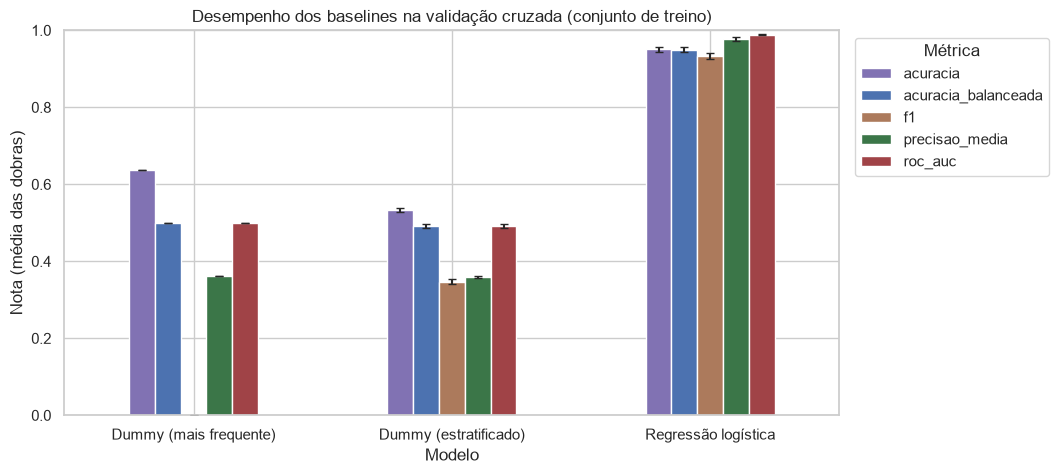

In [72]:
plota_metricas(
    medias_baselines, desvios_baselines, METRICAS_DO_GRAFICO, CORES_METRICAS,
    "Desempenho dos baselines na validação cruzada (conjunto de treino)",
)

A regressão logística já é muito boa: acurácia balanceada de **0,949**, F1 de 0,933, precisão média de 0,977 e ROC-AUC de 0,988. Boa parte da separação entre planetas e falsos positivos é, portanto, quase linear nos atributos padronizados. Isso eleva a referência: os algoritmos da seção 7 precisam superar **0,949**, e não 0,5. No Teste A, com hiperparâmetros padrão, a floresta (0,965) e o gradient boosting (0,973) superaram essa referência, o SVM praticamente empatou (0,9485), e o kNN (0,926) e a árvore (0,936) ficaram abaixo.

A célula abaixo verifica se a vantagem do gradient boosting padrão sobre a regressão logística é consistente entre as dobras.

In [73]:
notas_referencia = {**notas_padrao, **notas_baselines}

calcula_separacao(
    notas_referencia, "Gradient Boosting", "Regressão logística", METRICAS_COMPARADAS
).round(3)

,metrica,diferenca_media,desvio_da_diferenca,separacao,dobras_a_favor_de_a
0,acuracia_balanceada,0.024,0.007,3.655,5
1,f1,0.033,0.010,3.356,5
2,precisao_media,0.018,0.005,3.270,5
3,roc_auc,0.009,0.002,4.356,5


A separação foi de 3,66 na acurácia balanceada, 3,36 no F1, 3,27 na precisão média e 4,36 na ROC-AUC, com as 5 dobras a favor do gradient boosting em todas as métricas. Mesmo sem otimização, a vantagem do gradient boosting sobre o baseline forte é consistente.

In [74]:
MAPA_DE_COR_CONFUSAO = "Purples"

A **matriz de confusão** mostra, para cada classe verdadeira, quantos exemplos foram previstos em cada classe. Para um problema binário com a classe positiva "confirmado", ela tem quatro entradas:

|  | Previsto: falso positivo | Previsto: confirmado |
|---|---|---|
| **Verdadeiro: falso positivo** | VN (verdadeiro negativo) | FP (falso positivo do modelo) |
| **Verdadeiro: confirmado** | FN (falso negativo) | VP (verdadeiro positivo) |

Atenção para não confundir dois usos da expressão "falso positivo": aqui, FP é um **erro do modelo** (prever "confirmado" para um KOI que é falso positivo), enquanto "Falso positivo" também é o **nome de uma das classes** do problema.

Para não usar o conjunto de teste, as matrizes são construídas com **previsões fora da dobra** (`cross_val_predict`). Cada KOI de treino é previsto pelo modelo ajustado nas outras quatro dobras, ou seja, por um modelo que nunca o viu. As dobras são as mesmas da validação cruzada (seção 5.2). A matriz de confusão no conjunto de teste fica reservada para a avaliação final (seção 9).

In [75]:
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict


def plota_matrizes_confusao(modelos, X, y, grupos, cv, mapa_de_cor):

    rotulos = [NOMES_CLASSES[0], NOMES_CLASSES[1]]
    figura, eixos = plt.subplots(1, len(modelos), figsize=(5 * len(modelos), 4.5))

    matrizes = {}
    for eixo, (nome, modelo) in zip(eixos, modelos.items()):
        y_previsto = cross_val_predict(modelo, X, y, groups=grupos, cv=cv)
        matriz = confusion_matrix(y, y_previsto, labels=[0, 1])
        matrizes[nome] = matriz

        sns.heatmap(
            pd.DataFrame(matriz, index=rotulos, columns=rotulos),
            annot=True, fmt="d", cmap=mapa_de_cor, cbar=False,
            annot_kws={"size": 14}, ax=eixo,
        )
        eixo.set(xlabel="Classe prevista", ylabel="Classe verdadeira", title=nome)

    figura.suptitle("Matrizes de confusão dos baselines (previsões fora da dobra, treino)")
    figura.tight_layout()

    return matrizes

A função `plota_matrizes_confusao` usa o `cross_val_predict` com as mesmas dobras: cada KOI é previsto pelo modelo treinado nas outras quatro dobras. Em seguida, `confusion_matrix` conta os acertos e erros, e o `sns.heatmap` desenha uma matriz por baseline, com as classes verdadeiras nas linhas e as previstas nas colunas.

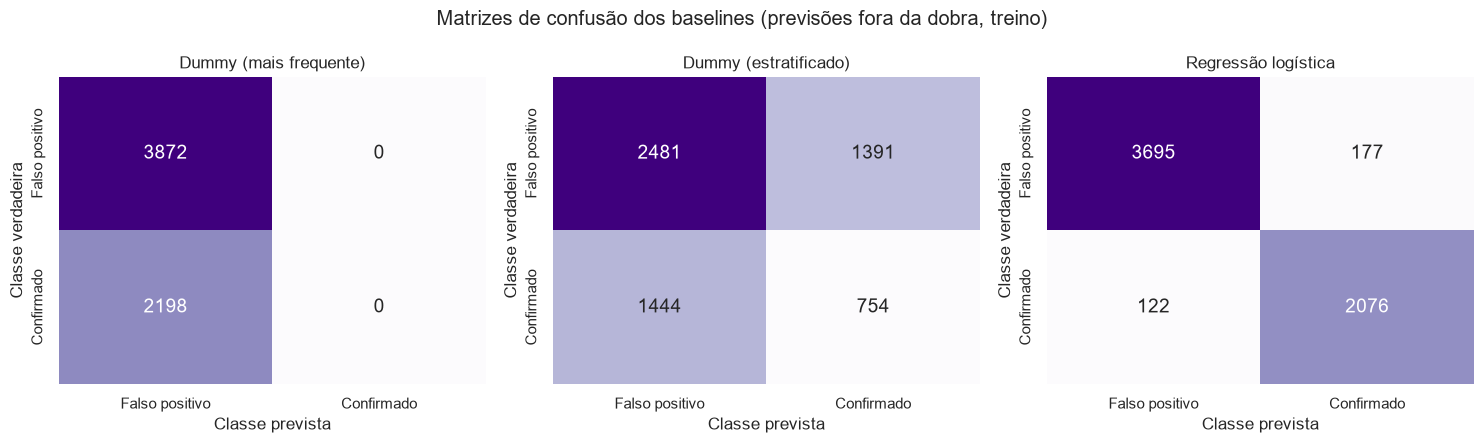

In [76]:
matrizes_baselines = plota_matrizes_confusao(
    BASELINES, X_treino, y_treino, grupos_treino, cv, MAPA_DE_COR_CONFUSAO
)

As matrizes deixam explícito o que as métricas resumem:

- **Dummy (mais frequente):** prevê "falso positivo" para todos os 6.070 KOIs. Acerta os 3.872 falsos positivos, mas **erra todos os 2.198 confirmados** (VP = 0). Daí a acurácia de 63,8% e a acurácia balanceada de $\frac{1}{2}\left(\frac{0}{2198} + \frac{3872}{3872}\right) = 0{,}5$.
- **Dummy (estratificado):** sorteia as classes na proporção do treino, sem olhar os atributos. Os acertos estão espalhados de forma compatível com o acaso: o recall dos confirmados é $754/2198 = 0{,}343$, próximo dos 36% esperados para um sorteio.
- **Regressão logística:** concentra quase todos os exemplos na diagonal. Erra 177 falsos positivos (previstos como confirmados) e 122 confirmados (previstos como falsos positivos). Os recalls são $2076/2198 = 0{,}944$ para os confirmados e $3695/3872 = 0{,}954$ para os falsos positivos, o que dá a acurácia balanceada de $0{,}949$.

No contexto do problema, os dois tipos de erro têm custos diferentes. Um **FN** (planeta classificado como falso positivo) significa perder um planeta real, e um **FP** (falso positivo classificado como planeta) significa gastar tempo de observação de acompanhamento à toa. A acurácia balanceada dá o mesmo peso aos dois.

## <b>7. Algoritmos</b>


Esta seção apresenta os cinco algoritmos comparados e o resultado da otimização de cada um. A ordem segue uma progressão didática: o **kNN** decide pelos vizinhos, a **árvore de decisão** decide por regras, a **floresta aleatória** combina muitas árvores em paralelo, o **gradient boosting** combina árvores em sequência, e o **SVM** procura a fronteira de margem máxima.

A otimização não foi feita no notebook, e sim pelo script `src/optimize.py`, rodado no terminal a partir da raiz do repositório:

```
python -m src.optimize --algoritmo knn --trials 100
```

O script lê apenas `data/processed/train.csv`, usa as mesmas dobras da seção 5.2, roda o Optuna até completar 100 trials e salva o estudo em `results/optuna/<algoritmo>.db` (SQLite), junto com uma tabela de todos os trials (`<algoritmo>_trials.csv`) e os melhores hiperparâmetros (`<algoritmo>_melhores.json`). Rodar fora do notebook tem duas vantagens: os estudos longos não dependem de o notebook ficar aberto, e, como o estudo é salvo em disco com `load_if_exists=True`, uma execução interrompida continua de onde parou. O notebook apenas **carrega** os estudos salvos.

Para cada algoritmo, são apresentados: a intuição e as fórmulas do modelo, os hiperparâmetros otimizados (com faixas justificadas na seção 5.4), o histórico da otimização, a importância dos hiperparâmetros, o efeito das escolhas de pré-processamento e o melhor pipeline encontrado.

Uma ressalva vale para todas as notas desta seção: a melhor nota de cada estudo é **otimista**. Cada trial tem uma nota estimada $\hat{s}_i$, com algum ruído, e escolher o máximo entre 100 trials favorece os trials que tiveram sorte nas dobras, pois

$$
\mathbb{E}\left[\max_i \hat{s}_i\right] \geq \max_i \mathbb{E}\left[\hat{s}_i\right] .
$$

Por isso, a nota da otimização não é a estimativa final de desempenho: o modelo escolhido é avaliado uma única vez no conjunto de teste, que não participou de nenhuma decisão (seção 9) [31].

In [77]:
from optuna.importance import FanovaImportanceEvaluator

PASTA_OPTUNA = Path("results/optuna")

NOMES_EXIBICAO = {
    "knn": "kNN",
    "arvore": "Árvore de decisão",
    "floresta": "Floresta aleatória",
    "gradient_boosting": "Gradient Boosting",
    "svm": "SVM",
}

ROTULO_METRICA = "Acurácia balanceada (média da CV)"

COR_TRIALS = "#9DA9C4"
COR_MELHOR_TRIAL = "#9A1C7B"
COR_IMPORTANCIA = "#671292"
PALETA_ESCOLHAS = "viridis"

`PASTA_OPTUNA` indica onde estão os estudos salvos, `NOMES_EXIBICAO` traduz os nomes internos dos algoritmos para os títulos dos gráficos, e as constantes de cor permitem trocar as cores de todos os gráficos desta seção em um único lugar.

In [78]:
def carrega_resultados_optuna(nome_algoritmo, pasta):

    estudo = optuna.load_study(
        study_name=nome_algoritmo,
        storage=f"sqlite:///{pasta / f'{nome_algoritmo}.db'}",
    )

    trials = estudo.trials_dataframe()
    trials = trials[trials["state"] == "COMPLETE"].reset_index(drop=True)
    trials["melhor_ate_agora"] = trials["value"].cummax()

    return estudo, trials

A função `carrega_resultados_optuna` abre o estudo salvo com `optuna.load_study` e o converte em uma tabela com `trials_dataframe()`, mantendo apenas os trials completos. A coluna `melhor_ate_agora`, calculada com `cummax()`, guarda a melhor nota encontrada até cada trial, e é usada para desenhar a curva do histórico.

In [79]:
def plota_historico(trials, nome_exibicao, cor_trials, cor_melhor):

    figura, eixo = plt.subplots(figsize=(9, 4.5))

    sns.scatterplot(data=trials, x="number", y="value", color=cor_trials,
                    label="Nota do trial", ax=eixo)
    eixo.step(trials["number"], trials["melhor_ate_agora"], where="post",
              color=cor_melhor, label="Melhor nota até o trial")

    eixo.set(
        xlabel="Número do trial",
        ylabel=ROTULO_METRICA,
        title=f"Histórico da otimização: {nome_exibicao}",
    )
    eixo.legend(loc="lower right")

A função `plota_historico` mostra cada trial como um ponto (nota na validação cruzada contra o número do trial) e a melhor nota até aquele trial como uma escada. Um histórico em que a escada sobe rápido e depois fica plana indica que a busca **convergiu**: os últimos trials já não encontram configurações melhores.

In [80]:
def plota_importancia_hiperparametros(estudo, nome_exibicao, cor, semente_aleatoria):

    importancias = pd.Series(
        optuna.importance.get_param_importances(
            estudo, evaluator=FanovaImportanceEvaluator(seed=semente_aleatoria)
        )
    )

    figura, eixo = plt.subplots(figsize=(8, 0.5 * len(importancias) + 1.5))
    sns.barplot(x=importancias.values, y=importancias.index, color=cor, ax=eixo)
    eixo.set(
        xlabel="Importância (fração da variância da nota, fANOVA)",
        ylabel="Hiperparâmetro",
        title=f"Importância dos hiperparâmetros: {nome_exibicao}",
    )

    return importancias

A importância dos hiperparâmetros é estimada pelo **fANOVA** (*functional ANOVA*) [33], disponível no Optuna. O método ajusta uma floresta aleatória que prevê a nota de um trial a partir dos seus hiperparâmetros e decompõe a variância dessa previsão em partes atribuídas a cada hiperparâmetro. A importância de um hiperparâmetro é a fração da variância da nota explicada por ele sozinho, e as importâncias são normalizadas para somar 1.

Duas limitações devem ser consideradas na leitura dos gráficos:

- só entram os hiperparâmetros presentes em **todos** os trials. Os hiperparâmetros condicionais, como `vif_limiar` e `rfe_fracao_mantida`, ficam de fora. Pelo mesmo motivo, a normalização só aparece no kNN e no SVM, os únicos algoritmos em que ela está sempre presente;
- a importância é calculada sobre os trials que o TPE escolheu testar, que se concentram nas regiões boas do espaço. Ela mede o quanto cada hiperparâmetro fez a nota variar **nesta busca**, e não o quanto ele importa em geral.

In [81]:
def plota_nota_por_escolha(trials, colunas, nome_exibicao, paleta):

    figura, eixos = plt.subplots(1, len(colunas), figsize=(5 * len(colunas), 4.5), sharey=True)
    eixos = np.atleast_1d(eixos)

    for eixo, coluna in zip(eixos, colunas):
        escolhas = trials[f"params_{coluna}"].fillna("não se aplica").astype(str)
        contagem = escolhas.value_counts()
        rotulos = escolhas.map(lambda e: f"{e}\n(n={contagem[e]})")

        sns.boxplot(x=rotulos, y=trials["value"], hue=rotulos, palette=paleta,
                    legend=False, showfliers=False, ax=eixo)
        sns.stripplot(x=rotulos, y=trials["value"], color="black", size=3, alpha=0.5, ax=eixo)
        eixo.set(xlabel=coluna, ylabel=ROTULO_METRICA)

    figura.suptitle(f"Nota por escolha de pré-processamento: {nome_exibicao}")
    figura.tight_layout()

A função `plota_nota_por_escolha` desenha, para cada escolha de pré-processamento (redução, normalização e indicador de faltante), um diagrama de caixa da nota dos trials que fizeram aquela escolha, com os trials individuais sobrepostos como pontos. O número de trials de cada opção ($n$) aparece no rótulo, e ele também é informativo: como o TPE testa mais vezes as opções que vêm dando bons resultados, um $n$ alto indica uma opção que a busca considerou promissora. Quando o normalizador não entra no pipeline (árvores sem redução), a opção aparece como "não se aplica".

In [82]:
def resume_melhor_trial(estudo):

    melhor = estudo.best_trial
    return pd.Series({"numero_trial": melhor.number, "nota_cv": melhor.value, **melhor.params})

A função `resume_melhor_trial` mostra o número do melhor trial, a sua nota e todos os seus hiperparâmetros.

### 7.1 kNN (k vizinhos mais próximos)

**Intuição.** O kNN [34] não constrói um modelo explícito: para classificar um KOI, ele procura os $k$ KOIs de treino mais próximos e decide pela classe majoritária entre eles. A proximidade é medida pela distância de Minkowski,

$$
d_p(x, x') = \left(\sum_{j=1}^{m} \lvert x_j - x'_j \rvert^p\right)^{1/p} ,
$$

que é a distância de Manhattan para $p = 1$ e a distância euclidiana para $p = 2$. Como a distância soma as diferenças de todos os atributos, um atributo com valores muito maiores domina a soma, e por isso o kNN sempre recebe normalização. Atributos redundantes também pesam mais de uma vez na distância, o que motiva a redução.

**Hiperparâmetros otimizados:**

- `knn_num_vizinhos` ($k$, de 1 a 50): $k$ pequeno segue detalhes locais e pode sobreajustar; $k$ grande suaviza a fronteira e pode subajustar;
- `knn_pesos` (`uniform` ou `distance`): com `distance`, cada vizinho vota com peso $1/d$, e os vizinhos mais próximos contam mais;
- `knn_p` (1 ou 2): Manhattan ou euclidiana. A distância de Manhattan é menos dominada por diferenças grandes em um único atributo e tende a se comportar melhor em dimensões altas [14];
- além das escolhas de pré-processamento (indicador de faltante, normalização e redução).

In [83]:
estudo_knn, trials_knn = carrega_resultados_optuna("knn", PASTA_OPTUNA)

print(f"Trials completos: {len(trials_knn)}")
print(f"Nota com os hiperparâmetros padrão (trial 0): {trials_knn.loc[0, 'value']:.4f}")
print(f"Melhor nota: {estudo_knn.best_value:.4f} (trial {estudo_knn.best_trial.number})")

Trials completos: 100
Nota com os hiperparâmetros padrão (trial 0): 0.9264
Melhor nota: 0.9644 (trial 98)


Os 100 trials foram completados. Com os hiperparâmetros padrão (trial 0: 5 vizinhos, votos uniformes, distância euclidiana, padronização e sem redução), a acurácia balanceada foi de **0,9264**, o mesmo valor do Teste A. A melhor nota foi de **0,9644**, no trial 98.

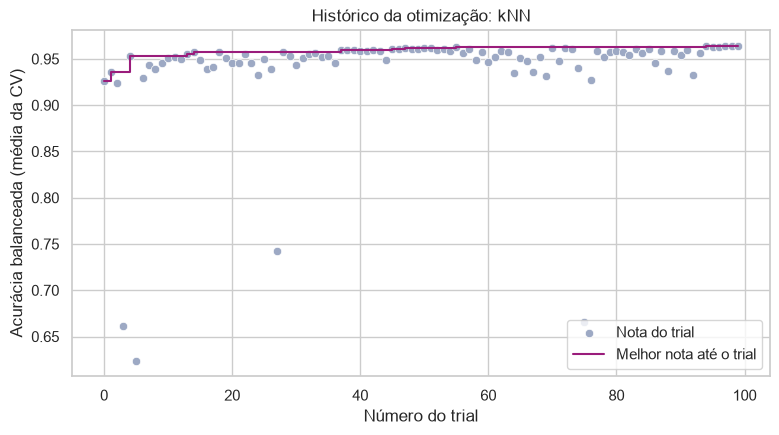

In [84]:
plota_historico(trials_knn, NOMES_EXIBICAO["knn"], COR_TRIALS, COR_MELHOR_TRIAL)

A melhor nota subiu rapidamente nos primeiros trials e, a partir de cerca do trial 15, passou a melhorar apenas em pequenos passos, até o trial 98. Os pontos muito abaixo dos demais (entre 0,62 e 0,74) são trials com PCA e escala robusta, a mesma combinação que desabou no Teste B (seção 5.6.3). Esses trials são poucos (4 dos 100), porque o TPE passou a evitar essa região depois de encontrá-la.

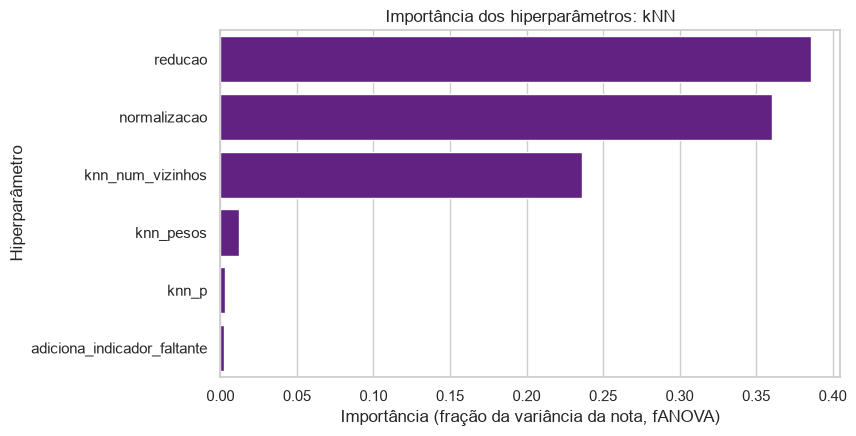

In [85]:
importancias_knn = plota_importancia_hiperparametros(
    estudo_knn, NOMES_EXIBICAO["knn"], COR_IMPORTANCIA, SEMENTE_ALEATORIA
)

Para o kNN, o pré-processamento importou mais que o próprio modelo: a **redução** (≈ 0,38) e a **normalização** (≈ 0,36) explicam juntas cerca de três quartos da variação das notas, e o número de vizinhos explica cerca de 0,24. O tipo de peso, a distância e o indicador de faltante tiveram importância praticamente nula nesta busca. Esse resultado concorda com o Teste B, em que a normalização e a redução foram os fatores que mais mudaram a nota do kNN.

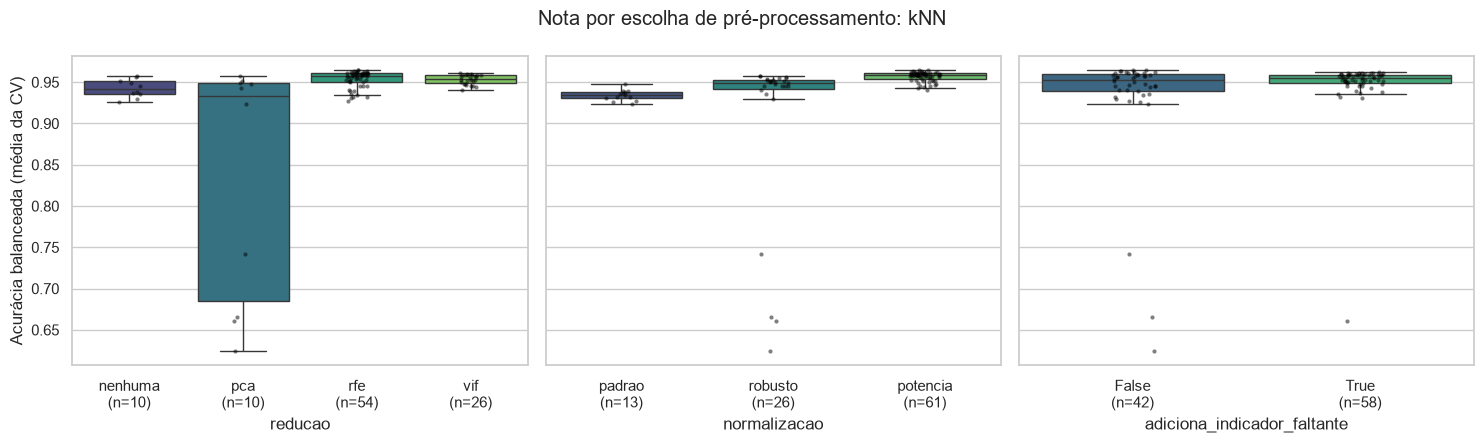

In [86]:
plota_nota_por_escolha(
    trials_knn, ["reducao", "normalizacao", "adiciona_indicador_faltante"],
    NOMES_EXIBICAO["knn"], PALETA_ESCOLHAS,
)

A busca concentrou-se no **RFE** (54 trials, contra 26 do VIF e 10 de cada uma das outras opções) e na **transformação de potência** (61 trials, contra 26 da escala robusta e 13 da padronização), as mesmas opções que se destacaram no Teste B. O indicador de faltante foi testado de forma equilibrada (58 trials com e 42 sem), coerente com o seu efeito pequeno.

In [87]:
resume_melhor_trial(estudo_knn)

numero_trial                         98
nota_cv                        0.964447
adiciona_indicador_faltante       False
reducao                             rfe
rfe_fracao_mantida              0.58334
normalizacao                   potencia
knn_num_vizinhos                      7
knn_pesos                       uniform
knn_p                                 1
dtype: object

O melhor pipeline do kNN usa **transformação de potência**, **RFE mantendo ≈ 58% dos atributos**, **sem indicador de faltante**, e um kNN com **7 vizinhos**, votos uniformes e **distância de Manhattan** ($p = 1$).

In [88]:
melhor_pipeline_knn = cria_instancia_modelo(estudo_knn.best_trial, "knn", SEMENTE_ALEATORIA)
melhor_pipeline_knn

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputador', ...), ('normalizador', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimator

**Mini-conclusão (kNN).** A otimização elevou a acurácia balanceada do kNN de 0,926 para 0,964, o maior ganho entre os cinco algoritmos (seção 8.3). O ganho veio principalmente do pré-processamento: a transformação de potência reduz a assimetria dos atributos (seção 4.3), e o RFE remove atributos pouco informativos e redundantes, que distorceriam as distâncias. O melhor pipeline é muito parecido com a melhor combinação do Teste B (RFE, potência e sem indicador), o que dá consistência às duas análises.

### 7.2 Árvore de decisão


**Intuição.** Uma árvore de decisão [35] classifica por uma sequência de perguntas do tipo "o atributo $j$ é menor que o limiar $t$?". A cada nó, o algoritmo escolhe o atributo e o limiar que deixam os dois grupos resultantes mais **puros**, isto é, mais dominados por uma única classe. Sendo $p_k$ a fração de exemplos da classe $k$ em um nó, a impureza é medida pelo índice de Gini ou pela entropia:

$$
G = 1 - \sum_k p_k^2 , \qquad H = -\sum_k p_k \log_2 p_k .
$$

Os dois valem zero em um nó puro e são máximos quando as classes estão misturadas igualmente. Uma árvore sem limites cresce até separar todos os exemplos de treino e sobreajusta. A **poda por custo-complexidade** combate isso escolhendo a subárvore $T$ que minimiza

$$
R_\alpha(T) = R(T) + \alpha\,\lvert T \rvert ,
$$

em que $R(T)$ é o erro da árvore no treino, $\lvert T \rvert$ é o número de folhas e $\alpha$ (`ccp_alpha`) é o custo de cada folha: quanto maior $\alpha$, menor a árvore.

**Hiperparâmetros otimizados:**

- `arvore_criterio` (`gini` ou `entropy`): a medida de impureza;
- `arvore_profundidade_maxima` (de 2 a 30) e `arvore_min_exemplos_folha` (de 1 a 50, em escala log): limitam o crescimento da árvore;
- `arvore_ccp_alpha` (de $10^{-5}$ a $10^{-1}$, em escala log): a intensidade da poda;
- além das escolhas de pré-processamento. A normalização só entra quando há redução, porque a árvore em si não depende da escala.

In [89]:
estudo_arvore, trials_arvore = carrega_resultados_optuna("arvore", PASTA_OPTUNA)

print(f"Trials completos: {len(trials_arvore)}")
print(f"Nota com os hiperparâmetros padrão (trial 0): {trials_arvore.loc[0, 'value']:.4f}")
print(f"Melhor nota: {estudo_arvore.best_value:.4f} (trial {estudo_arvore.best_trial.number})")

Trials completos: 100
Nota com os hiperparâmetros padrão (trial 0): 0.9362
Melhor nota: 0.9469 (trial 96)


Com os hiperparâmetros padrão (trial 0), a acurácia balanceada foi de **0,9362**, igual à do Teste A. A melhor nota foi de **0,9469**, no trial 96.

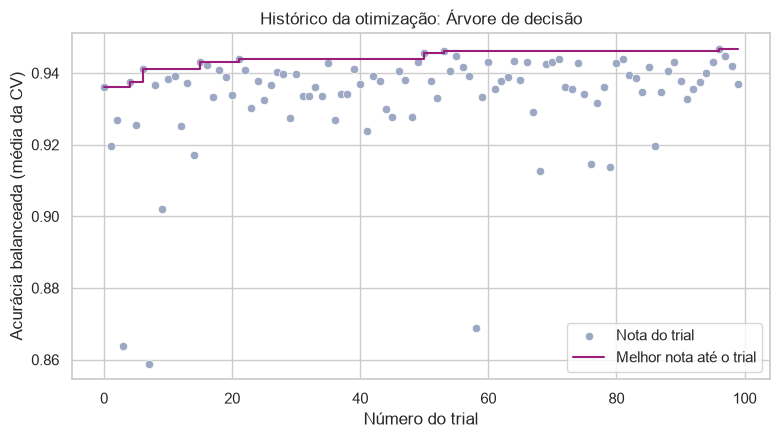

In [90]:
plota_historico(trials_arvore, NOMES_EXIBICAO["arvore"], COR_TRIALS, COR_MELHOR_TRIAL)

A árvore teve o histórico mais irregular entre os cinco algoritmos: mesmo depois de muitos trials, a maior parte das notas continuou espalhada entre cerca de 0,91 e 0,947, com alguns trials ainda mais baixos. A melhor nota subiu em vários pequenos degraus e só foi encontrada no trial 96. Isso é coerente com a alta variância das árvores de decisão: pequenas mudanças nos hiperparâmetros ou nos dados mudam a estrutura da árvore e, com ela, a nota.

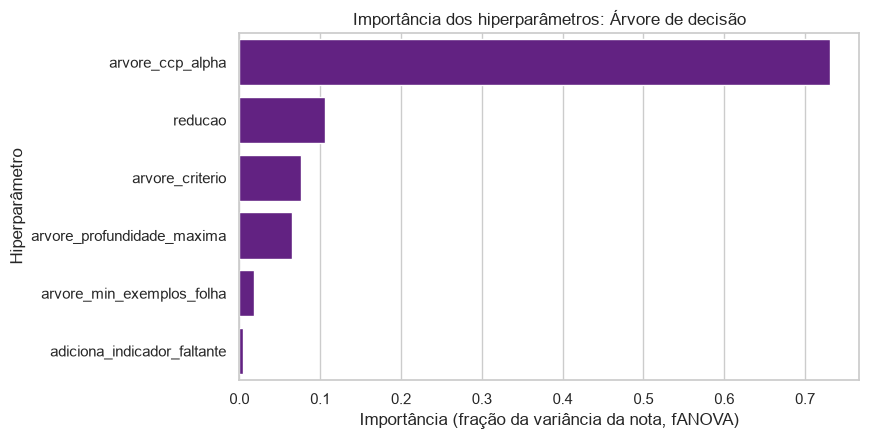

In [91]:
importancias_arvore = plota_importancia_hiperparametros(
    estudo_arvore, NOMES_EXIBICAO["arvore"], COR_IMPORTANCIA, SEMENTE_ALEATORIA
)

O hiperparâmetro mais importante foi, de longe, o **`ccp_alpha`** (≈ 0,73), seguido da redução (≈ 0,10), do critério (≈ 0,07) e da profundidade máxima (≈ 0,06). Ou seja, para a árvore, o que mais define a nota é **quanto ela é podada**. Com $\alpha$ muito pequeno, a árvore fica grande e sobreajusta; com $\alpha$ muito grande, ela perde ramos úteis.

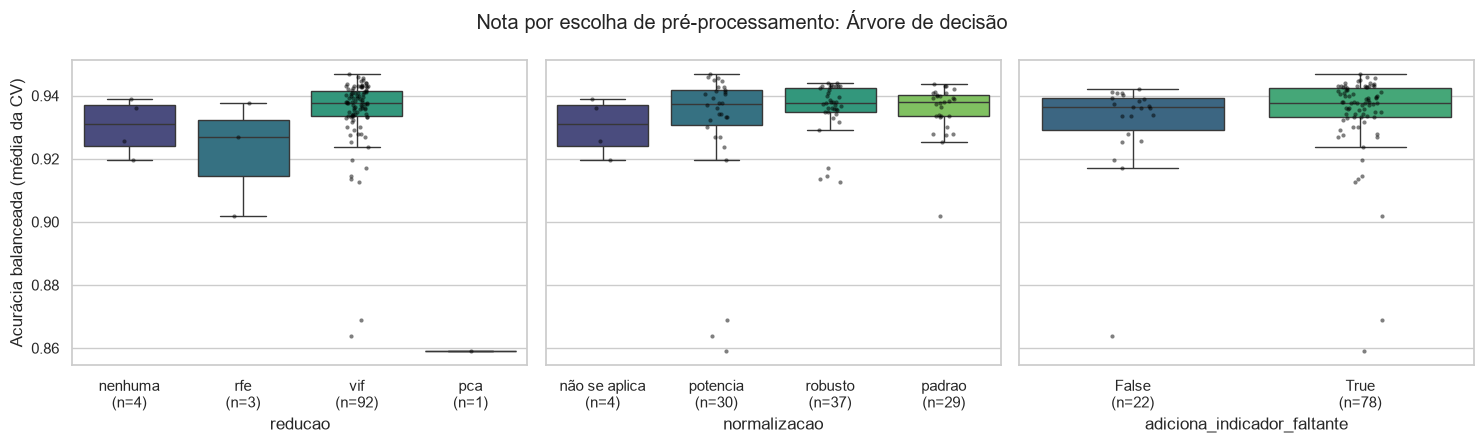

In [92]:
plota_nota_por_escolha(
    trials_arvore, ["reducao", "normalizacao", "adiciona_indicador_faltante"],
    NOMES_EXIBICAO["arvore"], PALETA_ESCOLHAS,
)

A busca escolheu o **VIF** em 92 dos 100 trials. Isso é, em parte, um efeito da própria busca: o TPE passou a testar quase só o VIF depois que ele deu bons resultados, e, por isso, as outras opções de redução foram pouco exploradas (4 trials sem redução, 3 com RFE e 1 com PCA, este com nota de cerca de 0,86). O indicador de faltante foi escolhido em 78 trials.

As três normalizações foram testadas em proporções parecidas (37 robusta, 30 potência e 29 padronização), e há uma explicação para isso. A correlação de Pearson não muda com transformações lineares de cada atributo, e, portanto, a padronização e a escala robusta levam o VIF a selecionar **exatamente os mesmos atributos**. Como a árvore também não depende da escala, os pipelines com essas duas normalizações são, na prática, equivalentes. Só a transformação de potência, que não é linear, muda a correlação, os atributos selecionados e a nota.

In [93]:
resume_melhor_trial(estudo_arvore)

numero_trial                          96
nota_cv                         0.946851
adiciona_indicador_faltante         True
reducao                              vif
vif_limiar                     69.094287
normalizacao                    potencia
arvore_criterio                  entropy
arvore_profundidade_maxima            26
arvore_min_exemplos_folha              2
arvore_ccp_alpha                 0.00238
dtype: object

O melhor pipeline da árvore usa **indicador de faltante**, **transformação de potência**, **seleção por VIF com limiar ≈ 69** (uma seleção leve, que remove apenas os atributos mais redundantes) e uma árvore com critério de **entropia**, profundidade máxima 26, pelo menos 2 exemplos por folha e $\alpha \approx 0{,}0024$.

In [94]:
melhor_pipeline_arvore = cria_instancia_modelo(estudo_arvore.best_trial, "arvore", SEMENTE_ALEATORIA)
melhor_pipeline_arvore

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputador', ...), ('normalizador', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever

**Mini-conclusão (árvore).** A otimização elevou a acurácia balanceada da árvore de 0,936 para 0,947 (0,9470 na reavaliação da seção 8), mas ela continuou sendo o pior dos cinco algoritmos e ficou **ligeiramente abaixo do baseline forte** (regressão logística, 0,949). A profundidade máxima alta (26) é compensada pela poda: com $\alpha \approx 0{,}0024$, os ramos que melhoram pouco o ajuste são cortados. O resultado reforça uma limitação conhecida das árvores isoladas: sua alta variância. Essa limitação motiva os dois próximos algoritmos, que combinam muitas árvores.

### 7.3 Floresta aleatória


**Intuição.** A floresta aleatória [36] combina $B$ árvores, cada uma treinada em uma amostra *bootstrap* do treino (sorteio com reposição) e, a cada nó, escolhendo o melhor corte entre apenas uma fração aleatória dos atributos. A previsão final é a média das probabilidades das árvores. Isso é chamado de *bagging* (*bootstrap aggregating*), com a aleatoriedade adicional na escolha dos atributos.

A razão para isso funcionar aparece na variância da média de $B$ variáveis com variância $\sigma^2$ e correlação $\rho$ entre si [37]:

$$
\text{Var}\left(\frac{1}{B}\sum_{b=1}^{B} T_b\right) = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2 .
$$

O segundo termo diminui com o número de árvores, e o primeiro só diminui se as árvores forem pouco correlacionadas. O sorteio dos atributos em cada nó serve justamente para reduzir $\rho$: sem ele, todas as árvores tenderiam a usar os mesmos atributos fortes nos primeiros cortes e seriam muito parecidas.

**Hiperparâmetros otimizados:**

- `floresta_num_arvores` (de 100 a 300): mais árvores reduzem a variância, com retorno decrescente; o limite de 300 é uma decisão de custo (seção 5.5);
- `floresta_fracao_atributos` (de 0,1 a 1,0): a fração de atributos sorteada em cada nó, que controla a correlação $\rho$ entre as árvores;
- `floresta_profundidade_maxima` (de 3 a 30) e `floresta_min_exemplos_folha` (de 1 a 20): controlam a complexidade de cada árvore;
- além das escolhas de pré-processamento.

In [95]:
estudo_floresta, trials_floresta = carrega_resultados_optuna("floresta", PASTA_OPTUNA)

print(f"Trials completos: {len(trials_floresta)}")
print(f"Nota com os hiperparâmetros padrão (trial 0): {trials_floresta.loc[0, 'value']:.4f}")
print(f"Melhor nota: {estudo_floresta.best_value:.4f} (trial {estudo_floresta.best_trial.number})")

Trials completos: 100
Nota com os hiperparâmetros padrão (trial 0): 0.9657
Melhor nota: 0.9699 (trial 84)


Com os hiperparâmetros padrão (trial 0), a acurácia balanceada foi de **0,9657**, e a melhor nota foi de **0,9699**, no trial 84. O trial 0 da otimização não é idêntico à floresta do Teste A (0,9653): ele tem 100 árvores, profundidade máxima 30 (o limite superior da faixa, já que o padrão do scikit-learn é não limitar a profundidade) e fração de atributos 0,11 ($\approx \sqrt{89}/89$, o padrão do scikit-learn), enquanto a floresta do Teste A tinha 200 árvores e profundidade ilimitada. Isso explica a pequena diferença entre as duas notas.

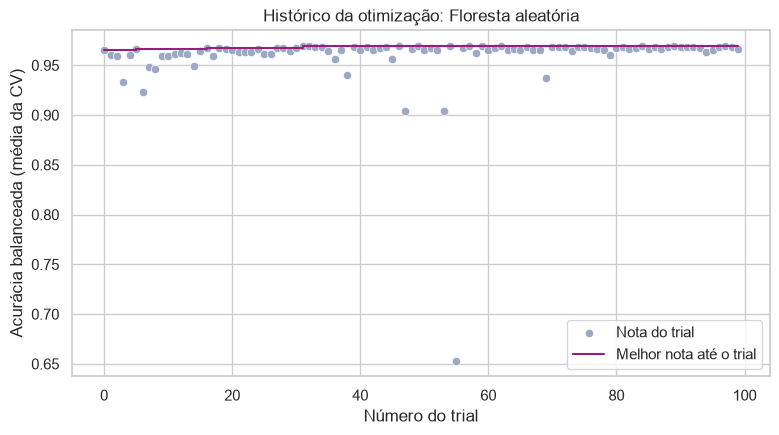

In [96]:
plota_historico(trials_floresta, NOMES_EXIBICAO["floresta"], COR_TRIALS, COR_MELHOR_TRIAL)

A floresta já começou com uma nota alta, e a otimização trouxe uma melhora pequena: quase todos os trials ficaram entre 0,96 e 0,97. O pior trial (≈ 0,65) usa PCA com escala robusta, a combinação problemática já identificada no Teste B. Os dois trials seguintes, com cerca de 0,90, não usam redução, e a diferença deles está nos hiperparâmetros da própria floresta.

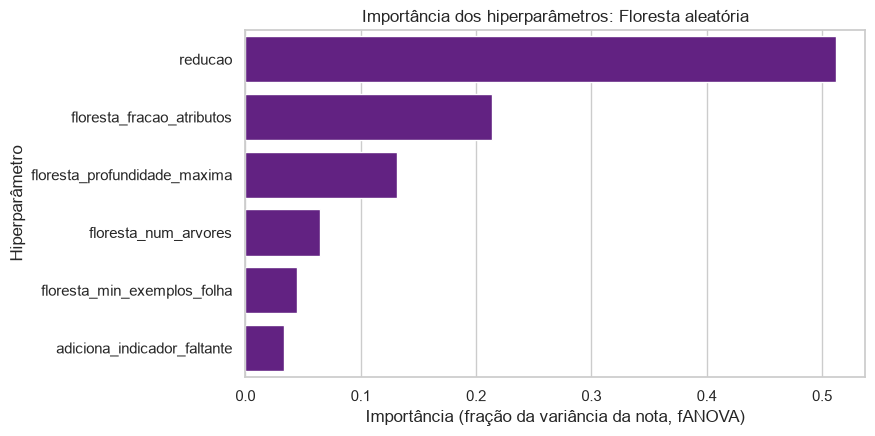

In [97]:
importancias_floresta = plota_importancia_hiperparametros(
    estudo_floresta, NOMES_EXIBICAO["floresta"], COR_IMPORTANCIA, SEMENTE_ALEATORIA
)

A escolha de **redução** foi o fator mais importante (≈ 0,51), seguida da fração de atributos por nó (≈ 0,21) e da profundidade máxima (≈ 0,13). O número de árvores (≈ 0,06), o mínimo de exemplos por folha (≈ 0,05) e o indicador de faltante (≈ 0,03) importaram pouco. A importância alta da redução vem principalmente dos trials com PCA, que tiveram as notas mais baixas (entre cerca de 0,92 e 0,95, além do trial de ≈ 0,65), enquanto os trials com VIF e RFE ficaram próximos dos trials sem redução.

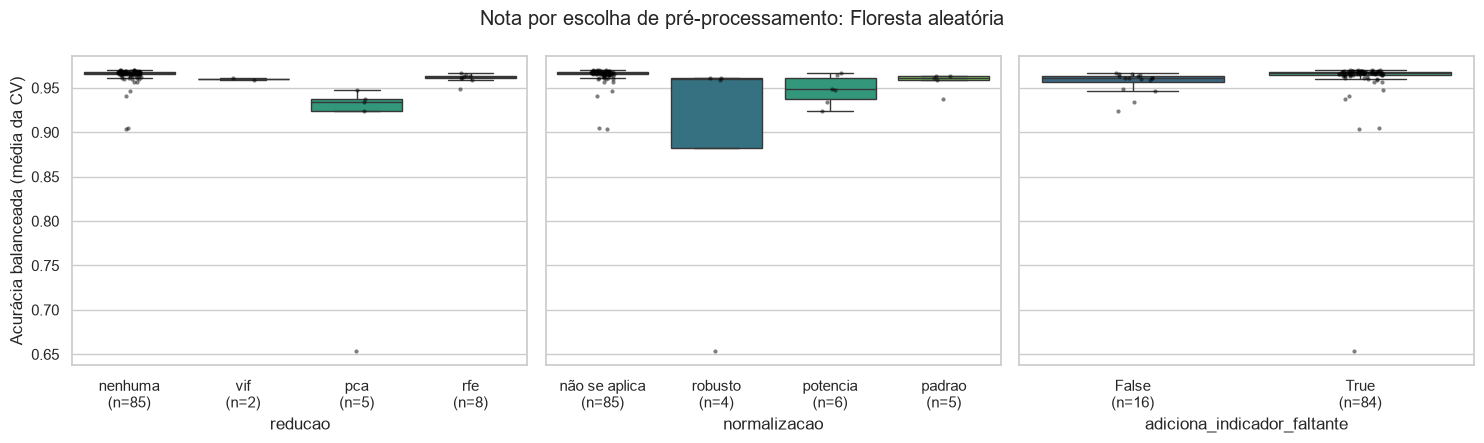

In [98]:
plota_nota_por_escolha(
    trials_floresta, ["reducao", "normalizacao", "adiciona_indicador_faltante"],
    NOMES_EXIBICAO["floresta"], PALETA_ESCOLHAS,
)

A busca escolheu **nenhuma redução** em 85 dos 100 trials (contra 8 com RFE, 5 com PCA e 2 com VIF), e o **indicador de faltante** em 84. Para a floresta, que já sorteia atributos em cada nó e lida bem com atributos redundantes, remover atributos não trouxe vantagem. Como não há redução, a normalização também não entra na maioria dos pipelines ("não se aplica").

In [99]:
resume_melhor_trial(estudo_floresta)

numero_trial                          84
nota_cv                         0.969863
adiciona_indicador_faltante         True
reducao                          nenhuma
floresta_num_arvores                 158
floresta_profundidade_maxima          12
floresta_min_exemplos_folha            2
floresta_fracao_atributos       0.180549
dtype: object

O melhor pipeline da floresta usa **indicador de faltante**, **nenhuma redução** (e, portanto, nenhuma normalização) e uma floresta com **158 árvores**, profundidade máxima 12, pelo menos 2 exemplos por folha e **≈ 18% dos atributos** sorteados em cada nó.

In [100]:
melhor_pipeline_floresta = cria_instancia_modelo(estudo_floresta.best_trial, "floresta", SEMENTE_ALEATORIA)
melhor_pipeline_floresta

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputador', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. 

**Mini-conclusão (floresta).** A floresta teve o comportamento mais estável da otimização: quase todas as configurações ficaram perto da melhor, e o ganho em relação ao padrão foi pequeno (de 0,965 para 0,970 na reavaliação). A melhor configuração limita a profundidade (12) em vez de deixar as árvores crescerem até o fim, e usa uma fração pequena de atributos por nó, o que reduz a correlação entre as árvores. A escolha do indicador de faltante em 84% dos trials é coerente com o caráter informativo da ausência de valores (seção 4.2).

### 7.4 Gradient boosting


**Intuição.** Enquanto a floresta treina árvores independentes e tira a média, o *gradient boosting* [38] treina árvores **em sequência**, e cada nova árvore corrige os erros das anteriores. Para classificação binária, o modelo trabalha na escala do log-odds. Ele começa com uma constante, o log-odds da proporção de positivos no treino,

$$
F_0 = \log\frac{\bar{y}}{1-\bar{y}} ,
$$

e a probabilidade prevista é $p = \sigma(F) = \frac{1}{1+e^{-F}}$. A função de perda é a entropia cruzada, $L = -[y\log p + (1-y)\log(1-p)]$, cuja derivada em relação a $F$ é

$$
\frac{\partial L}{\partial F} = p - y .
$$

Assim, o gradiente negativo é o **resíduo** $r = y - p$: positivo quando o modelo subestima a chance de ser planeta e negativo quando a superestima. A cada iteração $m$, uma pequena árvore $h_m$ é ajustada para prever esses resíduos, e o modelo é atualizado por

$$
F_m(x) = F_{m-1}(x) + \nu\,h_m(x) ,
$$

em que $\nu$ é a taxa de aprendizado. Ou seja, cada árvore dá um pequeno passo na direção que mais reduz a perda, como uma descida de gradiente. O `HistGradientBoostingClassifier` do scikit-learn agrupa os valores de cada atributo em faixas (histogramas) antes de procurar os cortes, o que torna o treino muito mais rápido.

**Hiperparâmetros otimizados:**

- `gb_taxa_aprendizado` ($\nu$, de 0,01 a 0,3, em escala log) e `gb_num_iteracoes` (de 100 a 500): passos menores exigem mais iterações; os dois são otimizados juntos;
- `gb_max_folhas` (de 8 a 64) e `gb_min_exemplos_folha` (de 10 a 100): controlam a complexidade de cada árvore;
- `gb_l2` (de $10^{-6}$ a 10, em escala log): regularização L2 dos valores das folhas;
- além das escolhas de pré-processamento.

In [101]:
estudo_gb, trials_gb = carrega_resultados_optuna("gradient_boosting", PASTA_OPTUNA)

print(f"Trials completos: {len(trials_gb)}")
print(f"Nota com os hiperparâmetros padrão (trial 0): {trials_gb.loc[0, 'value']:.4f}")
print(f"Melhor nota: {estudo_gb.best_value:.4f} (trial {estudo_gb.best_trial.number})")

Trials completos: 100
Nota com os hiperparâmetros padrão (trial 0): 0.9736
Melhor nota: 0.9784 (trial 61)


Com os hiperparâmetros padrão (trial 0), a acurácia balanceada foi de **0,9736**, e a melhor nota foi de **0,9784**, no trial 61.

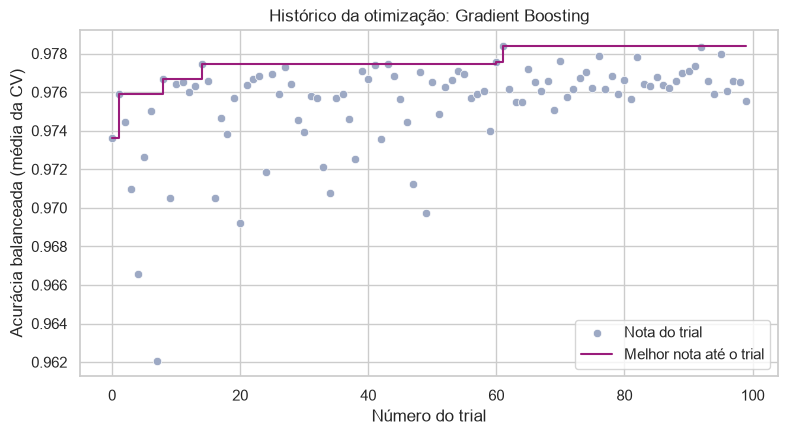

In [102]:
plota_historico(trials_gb, NOMES_EXIBICAO["gradient_boosting"], COR_TRIALS, COR_MELHOR_TRIAL)

Assim como a floresta, o gradient boosting já começou com uma nota alta, e todas as notas ficaram entre cerca de 0,962 e 0,978. Note que a escala do eixo vertical deste gráfico é muito mais estreita que a dos outros. A melhor nota subiu em alguns degraus até o trial 14 e teve um último salto no trial 61; nos últimos 40 trials, nenhuma configuração a superou.

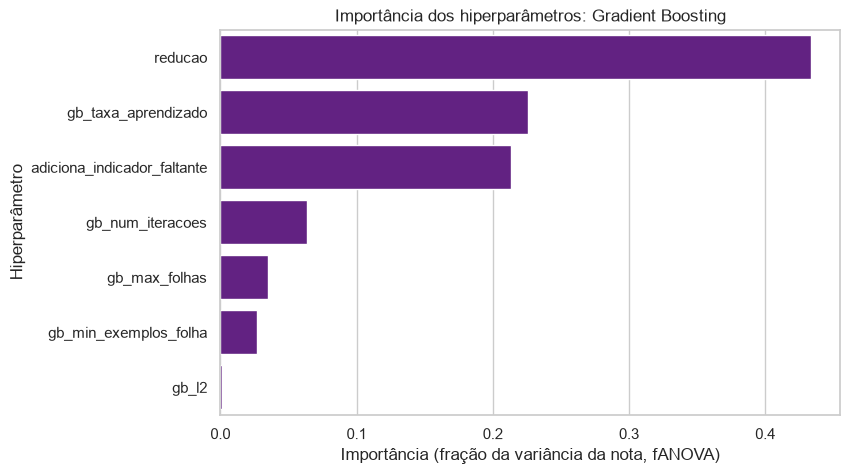

In [103]:
importancias_gb = plota_importancia_hiperparametros(
    estudo_gb, NOMES_EXIBICAO["gradient_boosting"], COR_IMPORTANCIA, SEMENTE_ALEATORIA
)

A escolha de **redução** foi o fator mais importante (≈ 0,43), seguida da taxa de aprendizado (≈ 0,22) e do indicador de faltante (≈ 0,21). O número de iterações (≈ 0,06), o número máximo de folhas (≈ 0,04), o mínimo de exemplos por folha (≈ 0,03) e a regularização L2 (≈ 0) importaram pouco. Como todas as notas estão em uma faixa estreita, essas importâncias explicam diferenças pequenas em valor absoluto.

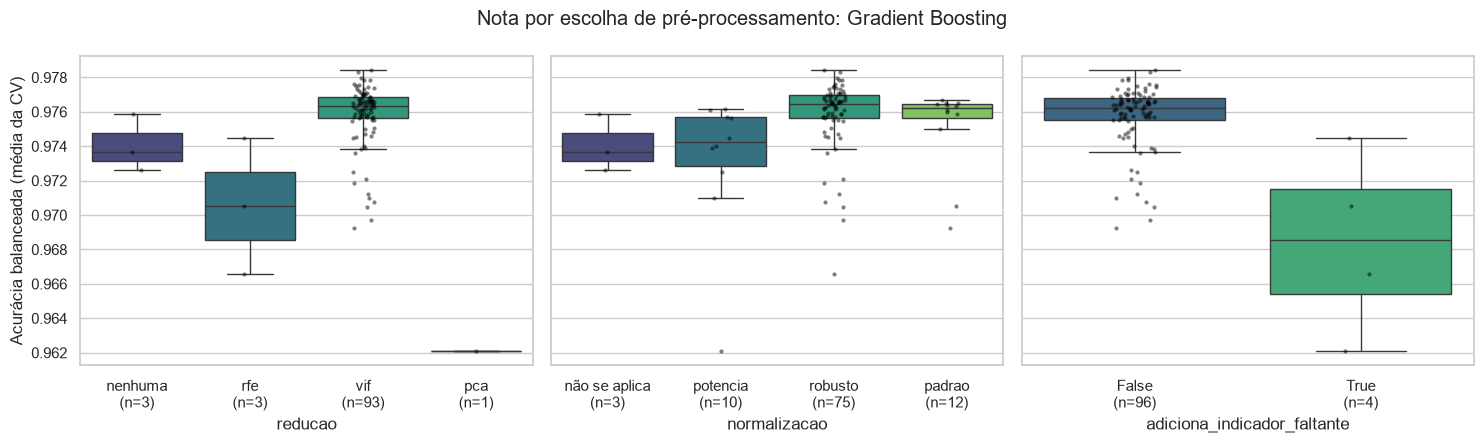

In [104]:
plota_nota_por_escolha(
    trials_gb, ["reducao", "normalizacao", "adiciona_indicador_faltante"],
    NOMES_EXIBICAO["gradient_boosting"], PALETA_ESCOLHAS,
)

A busca escolheu o **VIF** em 93 dos 100 trials e **não usou o indicador de faltante** em 96. Os poucos trials com indicador tiveram notas menores (entre cerca de 0,962 e 0,974). A escala robusta foi a normalização mais testada (75 trials), mas, pelo mesmo argumento da árvore (seção 7.2), com VIF ela é equivalente à padronização: a correlação não muda com transformações lineares, e as árvores do boosting não dependem da escala.

Cabe uma observação sobre os valores faltantes. O `HistGradientBoostingClassifier` aceita valores faltantes diretamente, mas, nos pipelines deste trabalho, o imputador vem sempre antes do modelo. Assim, o modelo nunca recebe valores faltantes, e a única forma de ele saber que um valor estava ausente é o indicador. Mesmo assim, a busca preferiu não usá-lo.

In [105]:
resume_melhor_trial(estudo_gb)

numero_trial                          61
nota_cv                         0.978416
adiciona_indicador_faltante        False
reducao                              vif
vif_limiar                     22.570063
normalizacao                     robusto
gb_taxa_aprendizado             0.248795
gb_num_iteracoes                     347
gb_max_folhas                         11
gb_min_exemplos_folha                 24
gb_l2                           0.003202
dtype: object

O melhor pipeline do gradient boosting usa **escala robusta**, **seleção por VIF com limiar ≈ 22,6**, **sem indicador de faltante**, e um modelo com taxa de aprendizado **≈ 0,25**, **347 iterações**, até 11 folhas por árvore, pelo menos 24 exemplos por folha e regularização L2 ≈ 0,003.

In [106]:
melhor_pipeline_gb = cria_instancia_modelo(
    estudo_gb.best_trial, "gradient_boosting", SEMENTE_ALEATORIA
)
melhor_pipeline_gb

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputador', ...), ('normalizador', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimator

**Mini-conclusão (gradient boosting).** O gradient boosting teve a maior nota de todos os algoritmos, tanto com os hiperparâmetros padrão quanto depois da otimização, que trouxe um ganho pequeno (de 0,9735 para 0,9764 na reavaliação). A melhor configuração combina árvores pequenas (11 folhas) com muitas iterações e uma taxa de aprendizado relativamente alta, além de uma seleção por VIF que remove parte dos atributos redundantes. Essa remoção não parece ter prejudicado o modelo, provavelmente porque a informação dos atributos removidos continua presente nos atributos correlacionados que permaneceram.

### 7.5 SVM


**Intuição.** O SVM [39] procura o hiperplano $w^\top x + b = 0$ que separa as duas classes com a **maior margem** possível. Escalando $w$ e $b$ de modo que os pontos mais próximos satisfaçam $\lvert w^\top x + b \rvert = 1$, a distância entre os dois hiperplanos $w^\top x + b = \pm 1$ é $2/\lVert w \rVert$, e maximizar a margem equivale a minimizar $\lVert w \rVert$. Como as classes não são perfeitamente separáveis, o SVM permite violações $\xi_i \geq 0$ e resolve

$$
\min_{w,\,b,\,\xi}\; \frac{1}{2}\lVert w \rVert^2 + C\sum_{i} \xi_i
\quad \text{sujeito a} \quad y_i\,(w^\top x_i + b) \geq 1 - \xi_i ,
$$

com $y_i \in \{-1, +1\}$. O hiperparâmetro $C$ controla o compromisso: $C$ grande penaliza muito os erros de treino (margem estreita, risco de sobreajuste), e $C$ pequeno aceita mais erros em troca de uma margem larga.

Para fronteiras não lineares, o produto escalar entre exemplos é substituído por um **kernel**. O kernel RBF,

$$
K(x, x') = \exp\left(-\gamma\,\lVert x - x' \rVert^2\right) ,
$$

mede a semelhança entre dois exemplos pela distância entre eles. O $\gamma$ define o alcance dessa semelhança: com $\gamma$ grande, cada exemplo só influencia uma vizinhança muito pequena e a fronteira fica muito irregular; com $\gamma$ pequeno, a fronteira fica suave, próxima de linear. Como o kernel depende de distâncias, o SVM sempre recebe normalização.

**Hiperparâmetros otimizados:**

- `svm_c` (de $10^{-2}$ a $10^{3}$, em escala log);
- `svm_gamma` (de $10^{-4}$ a $10^{1}$, em escala log). O padrão do scikit-learn (`gamma="scale"`) é $1/(m\,\text{Var}(X))$, que, com $m = 89$ atributos padronizados, vale $1/89 \approx 0{,}011$, dentro da faixa;
- além das escolhas de pré-processamento.

In [107]:
estudo_svm, trials_svm = carrega_resultados_optuna("svm", PASTA_OPTUNA)

print(f"Trials completos: {len(trials_svm)}")
print(f"Nota com os hiperparâmetros padrão (trial 0): {trials_svm.loc[0, 'value']:.4f}")
print(f"Melhor nota: {estudo_svm.best_value:.4f} (trial {estudo_svm.best_trial.number})")

Trials completos: 100
Nota com os hiperparâmetros padrão (trial 0): 0.9485
Melhor nota: 0.9717 (trial 92)


Com os hiperparâmetros padrão (trial 0), a acurácia balanceada foi de **0,9485**, igual à do Teste A. A melhor nota foi de **0,9717**, no trial 92.

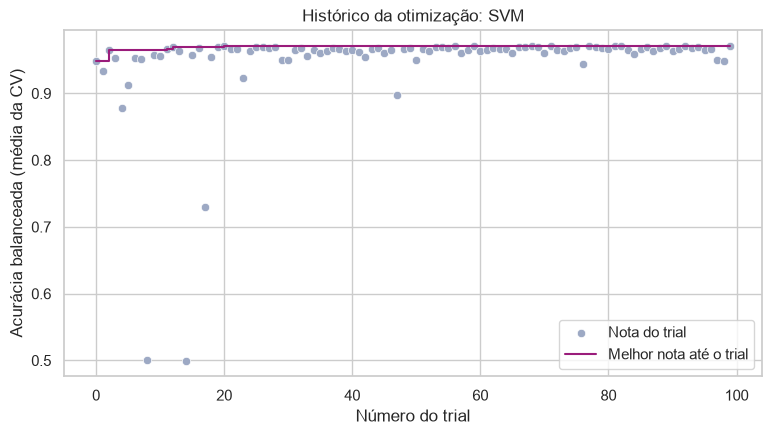

In [108]:
plota_historico(trials_svm, NOMES_EXIBICAO["svm"], COR_TRIALS, COR_MELHOR_TRIAL)

A melhor nota subiu rapidamente nos primeiros 20 trials e, depois, quase não mudou. Dois trials tiveram acurácia balanceada de exatamente **0,50**, o valor de um classificador que prevê sempre a mesma classe (seção 6): nesses trials, o SVM deixou de separar as classes. Os dois usam escala robusta, assim como o trial de ≈ 0,73. Outros poucos trials também ficaram abaixo dos demais. Depois do trial 20, quase todas as notas ficaram acima de 0,95.

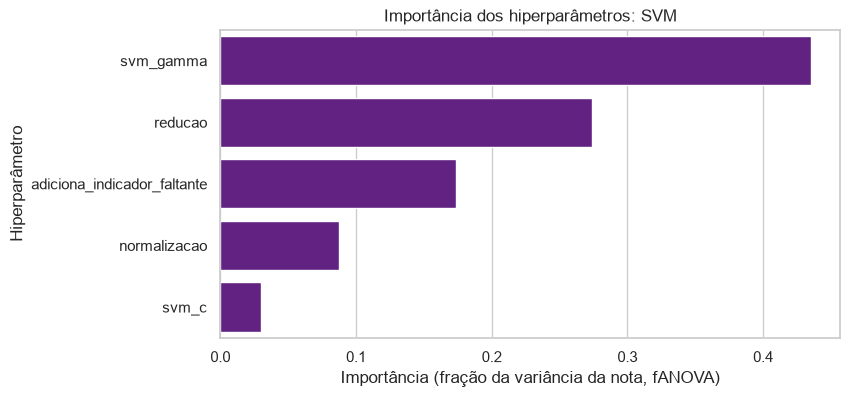

In [109]:
importancias_svm = plota_importancia_hiperparametros(
    estudo_svm, NOMES_EXIBICAO["svm"], COR_IMPORTANCIA, SEMENTE_ALEATORIA
)

O hiperparâmetro mais importante foi o **$\gamma$** (≈ 0,44), seguido da redução (≈ 0,27), do indicador de faltante (≈ 0,17) e da normalização (≈ 0,09). O $C$ teve importância pequena (≈ 0,03). A importância alta do $\gamma$ é esperada, porque ele define o alcance do kernel e, com isso, a forma da fronteira.

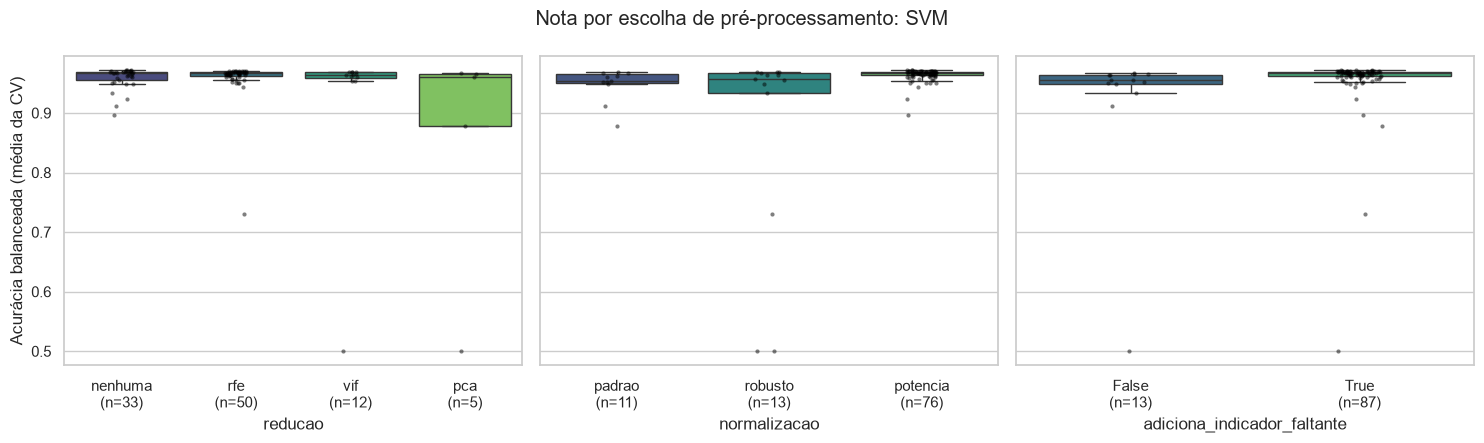

In [110]:
plota_nota_por_escolha(
    trials_svm, ["reducao", "normalizacao", "adiciona_indicador_faltante"],
    NOMES_EXIBICAO["svm"], PALETA_ESCOLHAS,
)

A busca testou mais o **RFE** (50 trials) e a ausência de redução (33), mais a **transformação de potência** (76 trials) e usou o **indicador de faltante** em 87 trials. A preferência pela transformação de potência repete o que aconteceu no kNN: os dois modelos dependem de distâncias, e reduzir a assimetria dos atributos ajuda ambos.

In [111]:
resume_melhor_trial(estudo_svm)

numero_trial                         92
nota_cv                        0.971669
adiciona_indicador_faltante        True
reducao                         nenhuma
normalizacao                   potencia
svm_c                           9.62334
svm_gamma                      0.007433
dtype: object

O melhor pipeline do SVM usa **indicador de faltante**, **transformação de potência**, **nenhuma redução** e um SVM com **$C \approx 9{,}6$** e **$\gamma \approx 0{,}0074$**.

In [112]:
melhor_pipeline_svm = cria_instancia_modelo(estudo_svm.best_trial, "svm", SEMENTE_ALEATORIA)
melhor_pipeline_svm

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputador', ...), ('normalizador', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever

**Mini-conclusão (SVM).** A otimização elevou a acurácia balanceada do SVM de 0,9485 para 0,9717, o segundo maior ganho entre os algoritmos. O $\gamma$ ótimo ($\approx 0{,}0074$) é um pouco menor que o padrão ($\approx 0{,}011$), o que indica uma fronteira um pouco mais suave, e o $C \approx 9{,}6$, maior que o padrão ($C = 1$), penaliza mais os erros de treino. Assim como no kNN, a transformação de potência foi decisiva. Embora o RFE tenha sido a redução mais testada, o melhor trial não usou redução.

## <b>8. Comparação entre modelos</b>


Esta seção compara os melhores pipelines dos cinco algoritmos entre si e com os baselines. A comparação usa **apenas o conjunto de treino**, com as mesmas cinco dobras usadas na otimização e nos baselines (seção 5.2). O critério de escolha, definido antes de olhar os resultados, é a **maior média da acurácia balanceada** na validação cruzada, e a consistência da vantagem é verificada com a separação entre os modelos (seção 5.6.2). O conjunto de teste continua sem ser usado.

### 8.1 Reconstrução dos melhores pipelines

O melhor pipeline de cada algoritmo é reconstruído a partir do melhor trial do estudo correspondente, com a mesma função `cria_instancia_modelo` usada na otimização. Assim, não é preciso copiar os hiperparâmetros à mão, o que evita erros de digitação.

In [113]:
NOMES_COMPARACAO = {
    "knn": "kNN",
    "arvore": "Árvore",
    "floresta": "Floresta",
    "gradient_boosting": "Gradient Boosting",
    "svm": "SVM",
}

ESTUDOS = {
    "knn": estudo_knn,
    "arvore": estudo_arvore,
    "floresta": estudo_floresta,
    "gradient_boosting": estudo_gb,
    "svm": estudo_svm,
}

MELHORES_PIPELINES = {
    NOMES_COMPARACAO[nome]: cria_instancia_modelo(estudo.best_trial, nome, SEMENTE_ALEATORIA)
    for nome, estudo in ESTUDOS.items()
}

list(MELHORES_PIPELINES)

['kNN', 'Árvore', 'Floresta', 'Gradient Boosting', 'SVM']

Os cinco pipelines foram reconstruídos, e cada um está guardado no dicionário `MELHORES_PIPELINES` com o nome usado nas tabelas e nos gráficos.

### 8.2 Desempenho na validação cruzada

Os cinco melhores pipelines são reavaliados com `avalia_varios_modelos`, agora com **todas as métricas** (a otimização registrou apenas a acurácia balanceada) e o tempo de treino de cada dobra. O resultado fica salvo em `results/cache/notas_otimizados.csv`.

In [114]:
notas_otimizados = separa_por_modelo(
    carrega_ou_calcula(
        PASTA_CACHE / "notas_otimizados.csv",
        avalia_varios_modelos,
        MELHORES_PIPELINES, X_treino, y_treino, grupos_treino, cv, METRICAS,
    )
)

medias_otimizados, desvios_otimizados = resume_notas(notas_otimizados)

Como as dobras e as sementes são as mesmas, a acurácia balanceada da reavaliação deveria ser igual à melhor nota de cada estudo do Optuna. A célula abaixo confere isso.

In [115]:
conferencia = pd.DataFrame({
    "nota_optuna": {NOMES_COMPARACAO[n]: e.best_value for n, e in ESTUDOS.items()},
    "nota_reavaliada": medias_otimizados["acuracia_balanceada"],
})
conferencia["diferenca"] = conferencia["nota_reavaliada"] - conferencia["nota_optuna"]

conferencia

,nota_optuna,nota_reavaliada,diferenca
kNN,0.964447,0.964447,0.000000e+00
Árvore,0.946851,0.946950,9.875817e-05
Floresta,0.969863,0.969863,-1.110223e-16
Gradient Boosting,0.978416,0.976369,-2.046490e-03
SVM,0.971669,0.971669,0.000000e+00


Para o kNN, a floresta e o SVM, a diferença é **zero**, e, para a árvore, é desprezível (+0,0001). Para o gradient boosting, porém, a nota reavaliada (0,9764) é **0,002 menor** que a do Optuna (0,9784).

A diferença aparece apenas nos dois pipelines que usam a **seleção por VIF** (árvore e gradient boosting), o que indica a sua origem. Com os indicadores de faltante e os atributos fortemente correlacionados (seção 4.6), a matriz de correlação fica **quase singular**: em uma das dobras, o seu número de condição chegou a cerca de $4 \times 10^{9}$, e dezenas de atributos tinham VIF acima de $10^{6}$. Nessas condições, a inversa da matriz, e portanto os VIFs, mudam com diferenças mínimas de arredondamento numérico, que dependem do computador, da biblioteca de álgebra linear e até de como as contas são divididas entre os processadores. A otimização (`src/optimize.py`) avalia as dobras uma de cada vez, enquanto a reavaliação as processa em paralelo (`n_jobs=-1`); além disso, o gradient boosting foi otimizado no computador secundário e reavaliado no principal (seção 5.5). Assim, o VIF pode ter removido atributos um pouco diferentes em alguma dobra, o que explica a diferença pequena da árvore e a maior do gradient boosting.

Essa diferença não muda as conclusões: o gradient boosting continua em primeiro lugar com qualquer uma das duas notas. Ainda assim, ela é uma limitação da seleção por VIF implementada neste trabalho (seção 11). A partir daqui, são usadas sempre as notas **reavaliadas**, que foram calculadas neste computador e com as mesmas dobras para todos os modelos.

In [116]:
notas_comparacao = {**notas_baselines, **notas_otimizados}
medias_comparacao, desvios_comparacao = resume_notas(notas_comparacao)

tabela_comparacao = formata_media_desvio(
    medias_comparacao[METRICAS_DO_GRAFICO], desvios_comparacao[METRICAS_DO_GRAFICO], 3
)
tabela_comparacao["tempo_treino_s"] = medias_comparacao["tempo_treino_s"].round(2)

tabela_comparacao.loc[medias_comparacao["acuracia_balanceada"].sort_values(ascending=False).index]

,acuracia,acuracia_balanceada,f1,precisao_media,roc_auc,tempo_treino_s
Gradient Boosting,0.978 ± 0.003,0.976 ± 0.003,0.97 ± 0.004,0.995 ± 0.001,0.997 ± 0.001,4.61
SVM,0.974 ± 0.003,0.972 ± 0.004,0.964 ± 0.004,0.992 ± 0.001,0.995 ± 0.001,12.85
Floresta,0.974 ± 0.002,0.97 ± 0.003,0.964 ± 0.003,0.993 ± 0.002,0.995 ± 0.001,5.05
kNN,0.963 ± 0.003,0.964 ± 0.003,0.95 ± 0.004,0.972 ± 0.009,0.988 ± 0.002,6.84
Regressão logística,0.951 ± 0.006,0.949 ± 0.006,0.933 ± 0.008,0.977 ± 0.005,0.988 ± 0.001,0.32
Árvore,0.952 ± 0.009,0.947 ± 0.009,0.934 ± 0.012,0.951 ± 0.014,0.969 ± 0.007,11.27
Dummy (mais frequente),0.638 ± 0.0,0.5 ± 0.0,0.0 ± 0.0,0.362 ± 0.0,0.5 ± 0.0,0.17
Dummy (estratificado),0.533 ± 0.004,0.492 ± 0.005,0.347 ± 0.006,0.359 ± 0.002,0.492 ± 0.005,0.08


A tabela reúne os baselines e os melhores pipelines, ordenados pela acurácia balanceada (média ± desvio-padrão entre as dobras):

- o **gradient boosting** lidera em todas as métricas: acurácia balanceada de 0,976 ± 0,003, F1 de 0,970, precisão média de 0,995 e ROC-AUC de 0,997;
- o **SVM** (0,972) e a **floresta** (0,970) vêm em seguida, muito próximos entre si;
- o **kNN** (0,964) supera a regressão logística (0,949) depois da otimização;
- a **árvore** (0,947) fica ligeiramente abaixo do baseline forte.

Os tempos de treino por dobra são os da reavaliação, com as cinco dobras em paralelo, e não são comparáveis com os tempos da otimização. Os melhores pipelines do SVM e da árvore usam a transformação de potência, que foi a opção de normalização mais lenta no Teste B, o que provavelmente explica boa parte do seu tempo de treino.

In [117]:
COR_PONTOS_DOBRAS = "#9DA9C4"
COR_MEDIA_MODELO = "#671292"
COR_LINHA_BASELINE = "#C44E52"
NOME_BASELINE_FORTE = "Regressão logística"


def plota_notas_por_dobra(notas_por_modelo, metrica, nome_metrica, nome_baseline,
                          cor_pontos, cor_media, cor_baseline):

    tabela = pd.concat(
        [notas[[metrica]].assign(modelo=nome) for nome, notas in notas_por_modelo.items()],
        ignore_index=True,
    )
    ordem = tabela.groupby("modelo")[metrica].mean().sort_values(ascending=False).index

    figura, eixo = plt.subplots(figsize=(9, 0.6 * len(ordem) + 1.5))

    sns.stripplot(data=tabela, x=metrica, y="modelo", order=ordem, color=cor_pontos,
                  size=7, alpha=0.8, ax=eixo, label="Nota de cada dobra")
    sns.pointplot(data=tabela, x=metrica, y="modelo", order=ordem, color=cor_media,
                  errorbar=None, linestyle="none", markers="D", ax=eixo, label="Média das dobras")

    referencia = notas_por_modelo[nome_baseline][metrica].mean()
    eixo.axvline(referencia, color=cor_baseline, linestyle="--",
                 label=f"{nome_baseline} ({referencia:.3f})")

    eixo.set(xlabel=nome_metrica, ylabel="Modelo",
             title=f"{nome_metrica} por dobra da validação cruzada (conjunto de treino)")

    handles, labels = eixo.get_legend_handles_labels()
    unicos = dict(zip(labels, handles))
    eixo.legend(unicos.values(), unicos.keys(), loc="lower right")

A função `plota_notas_por_dobra` mostra a nota de cada dobra (pontos) e a média (losango) de cada modelo, ordenados do melhor para o pior, com uma linha vertical na média da regressão logística. Os Dummy ficam de fora, porque estão muito abaixo (≈ 0,5) e comprimiriam a escala do gráfico.

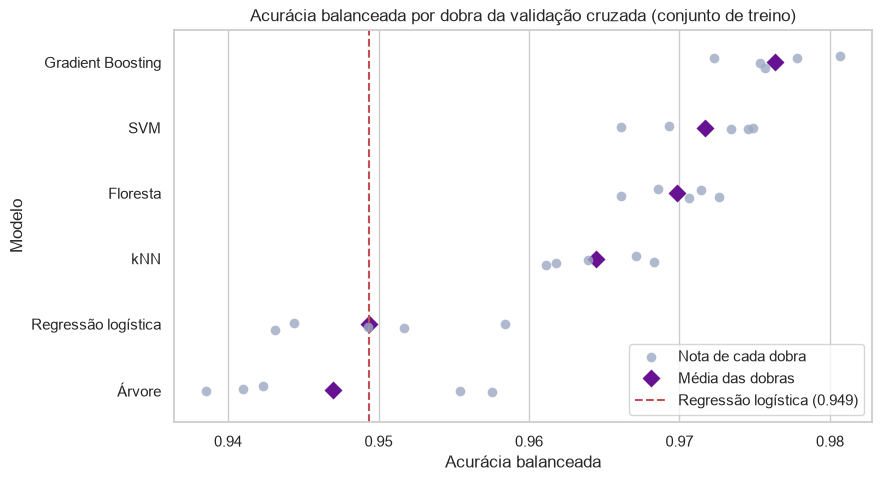

In [118]:
notas_sem_dummy = {nome: notas for nome, notas in notas_comparacao.items() if "Dummy" not in nome}

plota_notas_por_dobra(
    notas_sem_dummy, "acuracia_balanceada", "Acurácia balanceada", NOME_BASELINE_FORTE,
    COR_PONTOS_DOBRAS, COR_MEDIA_MODELO, COR_LINHA_BASELINE,
)

Quatro dos cinco algoritmos ficaram à direita da linha do baseline forte, com todas as dobras acima dela. A árvore é a exceção: sua média ficou um pouco abaixo da regressão logística, e suas dobras são as mais espalhadas (de cerca de 0,938 a 0,958), o que reflete novamente a alta variância das árvores isoladas.

As notas do gradient boosting variam entre cerca de 0,972 e 0,981 e se sobrepõem parcialmente às do SVM e da floresta. Por isso, a comparação entre os melhores modelos é feita **dobra a dobra** (seção 8.4), e não apenas pelas médias.

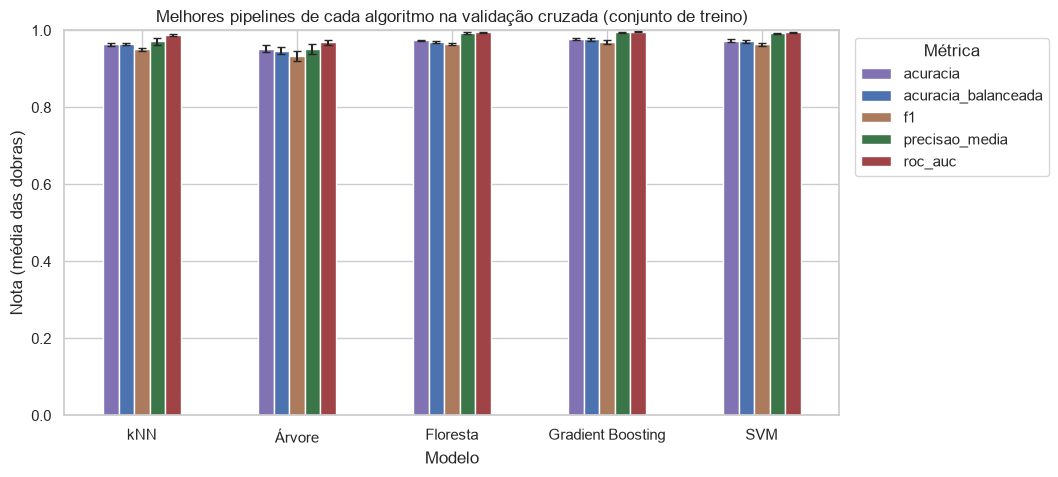

In [119]:
plota_metricas(
    medias_otimizados, desvios_otimizados, METRICAS_DO_GRAFICO, CORES_METRICAS,
    "Melhores pipelines de cada algoritmo na validação cruzada (conjunto de treino)",
)

Todas as métricas contam a mesma história: o gradient boosting tem as maiores médias, e as diferenças entre os quatro melhores modelos são pequenas em valor absoluto. A precisão média e a ROC-AUC ficam próximas de 1 para quase todos os modelos e diferenciam pouco entre eles, como já observado no Teste A. A árvore tem a menor precisão média (0,951) e a menor ROC-AUC (0,969), pelo mesmo motivo do Teste A: seus escores assumem poucos valores distintos.

### 8.3 Ganho da otimização

Para medir o efeito da otimização, a acurácia balanceada dos melhores pipelines é comparada com a dos modelos com hiperparâmetros padrão do Teste A (seção 5.6.2), avaliados nas mesmas dobras.

In [120]:
ganho_otimizacao = pd.DataFrame({
    "padrao": medias_padrao["acuracia_balanceada"],
    "otimizado": medias_otimizados["acuracia_balanceada"],
})
ganho_otimizacao["ganho"] = ganho_otimizacao["otimizado"] - ganho_otimizacao["padrao"]

ganho_otimizacao.sort_values("otimizado", ascending=False).round(4)

,padrao,otimizado,ganho
Gradient Boosting,0.9735,0.9764,0.0029
SVM,0.9485,0.9717,0.0231
Floresta,0.9653,0.9699,0.0046
kNN,0.9264,0.9644,0.0380
Árvore,0.9362,0.9470,0.0107


Todos os algoritmos melhoraram com a otimização, mas em proporções muito diferentes:

| Algoritmo | Padrão | Otimizado | Ganho |
|---|---|---|---|
| kNN | 0,9264 | 0,9644 | +0,0380 |
| SVM | 0,9485 | 0,9717 | +0,0231 |
| Árvore | 0,9362 | 0,9470 | +0,0107 |
| Floresta | 0,9653 | 0,9699 | +0,0046 |
| Gradient Boosting | 0,9735 | 0,9764 | +0,0029 |

Os maiores ganhos foram dos dois algoritmos baseados em distâncias, o **kNN** e o **SVM**, justamente os que mais dependem do pré-processamento. Em ambos, a otimização escolheu a transformação de potência no lugar da padronização usada no Teste A, e as seções 7.1 e 7.5 mostram que a normalização e a redução estiveram entre os fatores mais importantes. Os conjuntos de árvores (floresta e gradient boosting) já tinham notas altas com os hiperparâmetros padrão e ganharam pouco.

O ganho da floresta deve ser lido com cuidado: a floresta do Teste A tinha 200 árvores, e não as 100 do padrão do scikit-learn. Além disso, como as notas otimizadas são o máximo de 100 trials avaliados nas mesmas dobras, parte dos ganhos pequenos pode ser otimismo da seleção (seção 7).

### 8.4 Escolha do modelo final

O modelo final é o de **maior média da acurácia balanceada** na validação cruzada, o critério definido no início desta seção.

In [121]:
ranking = medias_otimizados["acuracia_balanceada"].sort_values(ascending=False)

MODELO_ESCOLHIDO = ranking.index[0]
SEGUNDO_COLOCADO = ranking.index[1]

print(f"Modelo escolhido: {MODELO_ESCOLHIDO} ({ranking.iloc[0]:.4f})")
print(f"Segundo colocado: {SEGUNDO_COLOCADO} ({ranking.iloc[1]:.4f})")

Modelo escolhido: Gradient Boosting (0.9764)
Segundo colocado: SVM (0.9717)


O modelo escolhido é o **gradient boosting** (0,9764), e o segundo colocado é o **SVM** (0,9717). Para verificar se a vantagem é consistente, e não fruto de uma única dobra, os dois são comparados dobra a dobra com `calcula_separacao`.

In [122]:
calcula_separacao(notas_comparacao, MODELO_ESCOLHIDO, SEGUNDO_COLOCADO, METRICAS_COMPARADAS).round(3)

,metrica,diferenca_media,desvio_da_diferenca,separacao,dobras_a_favor_de_a
0,acuracia_balanceada,0.005,0.004,1.114,5
1,f1,0.006,0.006,1.152,5
2,precisao_media,0.002,0.001,2.232,5
3,roc_auc,0.002,0.001,1.771,5


O gradient boosting venceu o SVM **nas 5 dobras e em todas as métricas**. Na acurácia balanceada, a diferença média foi de 0,005 e a separação foi de 1,11; nas demais métricas, a separação foi de 1,15 no F1, 2,23 na precisão média e 1,77 na ROC-AUC.

A diferença é pequena em valor absoluto, e a separação na métrica principal fica abaixo do critério de 2 usado neste trabalho. Por outro lado, a vitória nas 5 dobras tem pouca chance de acontecer por acaso: se os dois modelos fossem equivalentes e cada dobra fosse uma "moeda honesta", a probabilidade de um deles vencer as 5 seria $(1/2)^5 = 1/32 \approx 0{,}03$ (teste dos sinais unilateral). Esse cálculo supõe dobras independentes, o que não é exatamente verdade, e por isso é apenas indicativo. A conclusão honesta é que o gradient boosting é **consistentemente melhor, por uma margem pequena**.

In [123]:
calcula_separacao(notas_comparacao, MODELO_ESCOLHIDO, NOME_BASELINE_FORTE, METRICAS_COMPARADAS).round(3)

,metrica,diferenca_media,desvio_da_diferenca,separacao,dobras_a_favor_de_a
0,acuracia_balanceada,0.027,0.007,3.643,5
1,f1,0.037,0.011,3.507,5
2,precisao_media,0.018,0.005,3.366,5
3,roc_auc,0.009,0.002,3.677,5


Em relação ao baseline forte, a vantagem do gradient boosting otimizado é clara: separação de 3,64 na acurácia balanceada, 3,51 no F1, 3,37 na precisão média e 3,68 na ROC-AUC, com as 5 dobras a favor em todas as métricas.

Assim, o **gradient boosting** com os hiperparâmetros da seção 7.4 é o modelo escolhido. A escolha foi feita usando apenas o conjunto de treino. Na seção 9, ele é reajustado com todo o treino e avaliado **uma única vez** no conjunto de teste.

## <b>9. Avaliação final no teste</b>


Esta seção avalia o modelo escolhido na seção 8 no **conjunto de teste**, que ficou separado desde a seção 3 e não participou de nenhuma decisão: nem da análise exploratória, nem do estudo preliminar, nem da otimização, nem da escolha do modelo. O teste é usado **uma única vez**, com o modelo já escolhido, e nada no modelo foi alterado depois de ver estes resultados.

A nota da validação cruzada é otimista, porque o melhor pipeline foi escolhido justamente por ter a maior nota nessas dobras (seção 7). O teste fornece uma estimativa sem esse viés de seleção [31].

O procedimento é:

1. reajustar o melhor pipeline de gradient boosting com **todo o conjunto de treino** (6.070 KOIs), e não apenas com quatro das cinco dobras;
2. reajustar também o baseline forte (regressão logística), para que a comparação com ele seja feita nos mesmos dados;
3. calcular as cinco métricas no teste e comparar com a validação cruzada;
4. estimar a incerteza da nota com um bootstrap por estrela;
5. analisar a matriz de confusão, as curvas ROC e precisão-recall e os erros do modelo.

### 9.1 Ajuste final e métricas no teste

O conjunto de teste é lido do arquivo salvo na seção 3 e preparado com a mesma função e os mesmos atributos do treino (`ATRIBUTOS`, definidos só com o treino).

In [124]:
df_teste = pd.read_csv(CAMINHO_TESTE)
X_teste, y_teste, grupos_teste = preparar_X_y(df_teste, ATRIBUTOS)

print(f"Exemplos de teste: {len(X_teste)} | proporção de confirmados: {y_teste.mean():.3f}")

Exemplos de teste: 1517 | proporção de confirmados: 0.363


O teste tem **1.517 KOIs**, com **36,3% de confirmados**, proporção praticamente igual à do treino (36,2%), como esperado da divisão estratificada.

Na célula abaixo, `clone` cria uma cópia **sem treino** de cada pipeline, com os mesmos hiperparâmetros, e `fit` ajusta todas as etapas (imputação, normalização, seleção por VIF e modelo) com o treino inteiro. Nenhuma etapa vê o conjunto de teste.

In [125]:
from sklearn.base import clone

modelo_final = clone(MELHORES_PIPELINES[MODELO_ESCOLHIDO])
modelo_final.fit(X_treino, y_treino)

baseline_final = clone(BASELINES[NOME_BASELINE_FORTE])
baseline_final.fit(X_treino, y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](89,)","['koi_gmag','koi_rmag','koi_imag',...,'koi_srho','koi_srho_err1', 'koi_srho_err2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,89
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_va

A célula acima mostra o pipeline do baseline forte, que é o último objeto da célula. As funções abaixo calculam as métricas em um conjunto já separado:

- `calcula_escores` devolve um escore contínuo da classe "confirmado": a probabilidade prevista, quando o modelo a fornece, ou a função de decisão, que tem a mesma ordenação. Esse escore é usado na precisão média e na ROC-AUC, que avaliam a **ordenação** dos KOIs;
- `avalia_no_teste` calcula as cinco métricas do trabalho. Acurácia, acurácia balanceada e F1 usam a **classe prevista**, com o limiar padrão de probabilidade 0,5. O limiar não foi ajustado, porque ajustá-lo olhando o teste seria usar o teste para uma decisão de modelagem.

In [126]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    roc_auc_score,
)


def calcula_escores(modelo, X):

    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)


def avalia_no_teste(modelo, X, y):

    y_previsto = modelo.predict(X)
    escores = calcula_escores(modelo, X)

    return pd.Series({
        "acuracia": accuracy_score(y, y_previsto),
        "acuracia_balanceada": balanced_accuracy_score(y, y_previsto),
        "f1": f1_score(y, y_previsto, zero_division=0),
        "precisao_media": average_precision_score(y, escores),
        "roc_auc": roc_auc_score(y, escores),
    })

A tabela compara, para o gradient boosting, a média da validação cruzada no treino (seção 8) com o desempenho no teste, e mostra o baseline forte no teste.

In [127]:
metricas_teste = pd.DataFrame({
    f"{MODELO_ESCOLHIDO} (CV no treino)": medias_comparacao.loc[MODELO_ESCOLHIDO, METRICAS_DO_GRAFICO],
    f"{MODELO_ESCOLHIDO} (teste)": avalia_no_teste(modelo_final, X_teste, y_teste),
    f"{NOME_BASELINE_FORTE} (teste)": avalia_no_teste(baseline_final, X_teste, y_teste),
})

metricas_teste.round(4)

,Gradient Boosting (CV no treino),Gradient Boosting (teste),Regressão logística (teste)
acuracia,0.9783,0.9809,0.9545
acuracia_balanceada,0.9764,0.9791,0.9537
f1,0.9700,0.9736,0.9381
precisao_media,0.9946,0.9947,0.9854
roc_auc,0.9965,0.9977,0.9918


| Métrica | GB (CV no treino) | GB (teste) | Regressão logística (teste) |
|---|---|---|---|
| Acurácia | 0,9783 | 0,9809 | 0,9545 |
| Acurácia balanceada | 0,9764 | **0,9791** | 0,9537 |
| F1 | 0,9700 | 0,9736 | 0,9381 |
| Precisão média | 0,9946 | 0,9947 | 0,9854 |
| ROC-AUC | 0,9965 | 0,9977 | 0,9918 |

Três pontos se destacam:

1. **O desempenho no teste confirma a validação cruzada.** A acurácia balanceada no teste (0,9791) ficou próxima da média da validação cruzada (0,9764), e o mesmo vale para as demais métricas. Não há sinal de sobreajuste nem de que a otimização tenha produzido uma nota artificialmente alta. A nota do teste ficou até um pouco **acima** da validação cruzada, o que não contradiz o otimismo esperado da seleção (seção 7): a diferença é pequena e está dentro da incerteza da estimativa (seção 9.2).
2. **A vantagem sobre o baseline se mantém.** No teste, o gradient boosting supera a regressão logística em todas as métricas, com diferença de 0,025 na acurácia balanceada. Na validação cruzada, essa diferença era de 0,027 (seção 8.4).
3. **O baseline também se manteve estável.** A regressão logística teve acurácia balanceada de 0,9537 no teste, contra 0,949 na validação cruzada. Ou seja, a divisão treino/teste não favoreceu especialmente nenhum dos dois modelos.

### 9.2 Incerteza da estimativa (bootstrap por estrela)

Uma única nota no teste é uma estimativa: com outros 1.517 KOIs, ela seria um pouco diferente. Para medir essa incerteza, usa-se o **bootstrap** [40]: sorteiam-se, com reposição, novos conjuntos do mesmo tamanho a partir do teste, recalcula-se a métrica em cada um, e a variação entre as reamostragens indica a incerteza.

Dois detalhes da implementação:

- o sorteio é feito por **estrela**, e não por KOI. KOIs da mesma estrela não são independentes (seção 4.7), e sorteá-los separadamente subestimaria a incerteza. Em cada reamostragem, sorteiam-se estrelas com reposição e usam-se todos os KOIs das estrelas sorteadas, o mesmo agrupamento usado na divisão e na validação cruzada;
- o intervalo de 95% é formado pelos quantis de 2,5% e 97,5% das 1.000 notas (método dos percentis).

O modelo fica **fixo** em todas as reamostragens: o intervalo mede a incerteza devida à amostra de teste, e não a variação que viria de treinar o modelo com outros dados.

In [128]:
NUM_REAMOSTRAGENS = 1000
NIVEL_CONFIANCA_IC = 0.95


def intervalo_bootstrap_por_estrela(y, y_previsto, grupos, metrica, num_reamostragens,
                                    nivel_confianca, semente_aleatoria):

    gerador = np.random.default_rng(semente_aleatoria)
    tabela = pd.DataFrame({"y": np.asarray(y), "prev": np.asarray(y_previsto),
                           "grupo": np.asarray(grupos)})
    indices_por_estrela = tabela.groupby("grupo").indices
    estrelas = np.array(list(indices_por_estrela))

    valores = []
    for _ in range(num_reamostragens):
        sorteadas = gerador.choice(estrelas, size=len(estrelas), replace=True)
        linhas = np.concatenate([indices_por_estrela[e] for e in sorteadas])
        valores.append(metrica(tabela["y"].values[linhas], tabela["prev"].values[linhas]))

    alfa = 1 - nivel_confianca
    return tuple(np.quantile(valores, [alfa / 2, 1 - alfa / 2]))


y_previsto_teste = modelo_final.predict(X_teste)

ic_inferior, ic_superior = intervalo_bootstrap_por_estrela(
    y_teste, y_previsto_teste, grupos_teste, balanced_accuracy_score,
    NUM_REAMOSTRAGENS, NIVEL_CONFIANCA_IC, SEMENTE_ALEATORIA,
)

print(f"Acurácia balanceada no teste: {balanced_accuracy_score(y_teste, y_previsto_teste):.4f}")
print(f"IC de {NIVEL_CONFIANCA_IC:.0%}: [{ic_inferior:.4f}; {ic_superior:.4f}]")

Acurácia balanceada no teste: 0.9791
IC de 95%: [0.9706; 0.9864]


A acurácia balanceada no teste foi de **0,9791**, com intervalo de confiança de 95% de **[0,9706; 0,9864]**. O intervalo contém tanto a média da validação cruzada (0,9764) quanto a melhor nota encontrada pelo Optuna (0,9784), o que reforça que as estimativas do treino e do teste são compatíveis. O intervalo também fica inteiramente acima da acurácia balanceada da regressão logística no teste (0,9537).

### 9.3 Matriz de confusão

A matriz de confusão mostra os acertos e erros do modelo final no teste, com as classes verdadeiras nas linhas e as previstas nas colunas, na mesma organização da seção 6.

VN = 953 | FP = 14 | FN = 15 | VP = 535


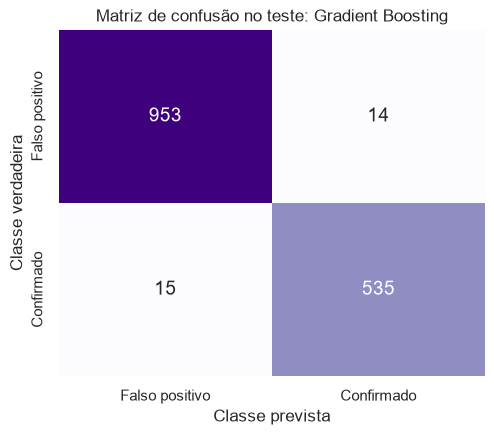

In [129]:
from sklearn.metrics import confusion_matrix

MAPA_DE_COR_CONFUSAO = "Purples"

rotulos = [NOMES_CLASSES[0], NOMES_CLASSES[1]]
matriz_teste = confusion_matrix(y_teste, y_previsto_teste, labels=[0, 1])

figura, eixo = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    pd.DataFrame(matriz_teste, index=rotulos, columns=rotulos),
    annot=True, fmt="d", cmap=MAPA_DE_COR_CONFUSAO, cbar=False, annot_kws={"size": 14}, ax=eixo,
)
eixo.set(xlabel="Classe prevista", ylabel="Classe verdadeira",
         title=f"Matriz de confusão no teste: {MODELO_ESCOLHIDO}")

vn, fp, fn, vp = matriz_teste.ravel()
print(f"VN = {vn} | FP = {fp} | FN = {fn} | VP = {vp}")

O modelo errou **29 dos 1.517 KOIs** (1,9%), com os erros divididos quase igualmente entre os dois tipos:

- **15 FN** (planetas confirmados previstos como falsos positivos): o recall dos confirmados é $535/550 = 0{,}973$;
- **14 FP** (falsos positivos previstos como planetas): o recall dos falsos positivos é $953/967 = 0{,}986$.

A média desses dois recalls é a acurácia balanceada, $\frac{1}{2}(0{,}973 + 0{,}986) = 0{,}979$. A precisão da classe planeta é $535/(535+14) = 0{,}974$: de cada 100 KOIs que o modelo classifica como planeta, cerca de 97 são de fato confirmados.

No contexto do problema (seção 6), um FN significa perder um planeta real, e um FP significa gastar tempo de observação de acompanhamento com um objeto que não é um planeta. O modelo comete os dois tipos de erro em quantidades parecidas, sem privilegiar nenhum deles. Como o limiar de decisão é o padrão (0,5), ele poderia ser ajustado no futuro para favorecer um tipo de erro, mas essa escolha teria de ser feita com a validação cruzada no treino, e não com o teste.

### 9.4 Curvas ROC e precisão-recall

As curvas mostram o desempenho do modelo em **todos os limiares de decisão**, e não apenas no limiar 0,5:

- a **curva ROC** [41] mostra, para cada limiar, a taxa de verdadeiros positivos (recall dos planetas) contra a taxa de falsos positivos (fração dos falsos positivos classificados como planeta). Um classificador perfeito passa pelo canto superior esquerdo, e um classificador ao acaso fica na diagonal;
- a **curva precisão-recall** mostra a precisão contra o recall dos planetas. Ela é mais informativa que a ROC quando as classes são desbalanceadas, porque a precisão depende diretamente do número de falsos positivos do modelo [42]. A referência do acaso é a linha horizontal na proporção de confirmados (0,363).

O gradient boosting e a regressão logística aparecem no mesmo gráfico para comparação.

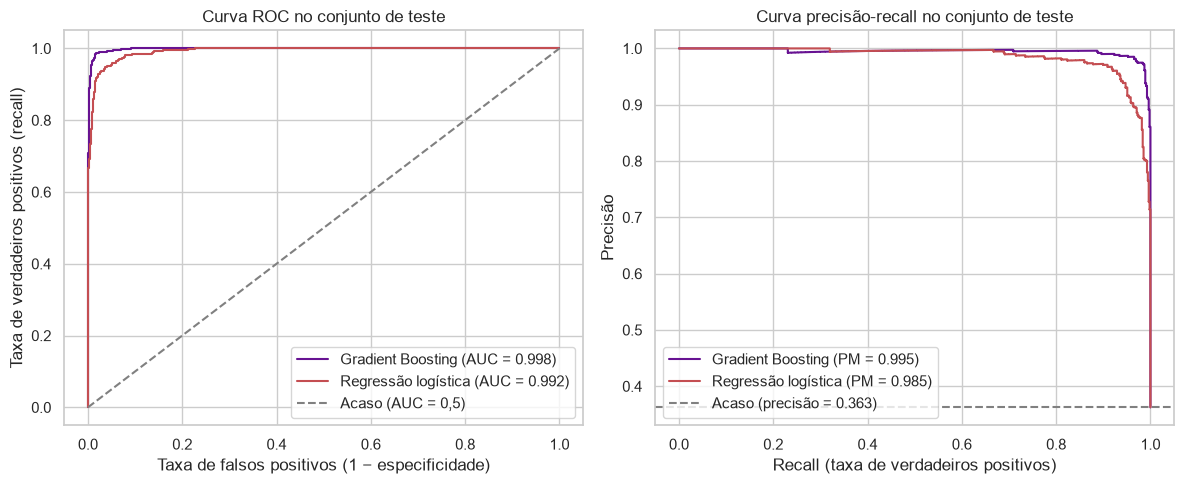

In [130]:
from sklearn.metrics import precision_recall_curve, roc_curve

COR_MODELO_FINAL = "#671292"
COR_BASELINE_FINAL = "#C44E52"
COR_ACASO = "gray"

figura, (eixo_roc, eixo_pr) = plt.subplots(1, 2, figsize=(12, 5))

for modelo, nome, cor in [
    (modelo_final, MODELO_ESCOLHIDO, COR_MODELO_FINAL),
    (baseline_final, NOME_BASELINE_FORTE, COR_BASELINE_FINAL),
]:
    escores = calcula_escores(modelo, X_teste)

    taxa_fp, taxa_vp, _ = roc_curve(y_teste, escores)
    eixo_roc.plot(taxa_fp, taxa_vp, color=cor,
                  label=f"{nome} (AUC = {roc_auc_score(y_teste, escores):.3f})")

    precisao, recall, _ = precision_recall_curve(y_teste, escores)
    eixo_pr.step(recall, precisao, where="post", color=cor,
                 label=f"{nome} (PM = {average_precision_score(y_teste, escores):.3f})")

eixo_roc.plot([0, 1], [0, 1], linestyle="--", color=COR_ACASO, label="Acaso (AUC = 0,5)")
eixo_roc.set(xlabel="Taxa de falsos positivos (1 − especificidade)",
             ylabel="Taxa de verdadeiros positivos (recall)",
             title="Curva ROC no conjunto de teste")
eixo_roc.legend(loc="lower right")

eixo_pr.axhline(y_teste.mean(), linestyle="--", color=COR_ACASO,
                label=f"Acaso (precisão = {y_teste.mean():.3f})")
eixo_pr.set(xlabel="Recall (taxa de verdadeiros positivos)", ylabel="Precisão",
            title="Curva precisão-recall no conjunto de teste")
eixo_pr.legend(loc="lower left")

figura.tight_layout()

Na **curva ROC**, a curva do gradient boosting fica acima da regressão logística em praticamente todos os limiares e muito próxima do canto superior esquerdo (AUC = 0,998, contra 0,992). As duas curvas se afastam principalmente na região de taxa de falsos positivos baixa, onde o gradient boosting atinge um recall próximo de 1 mais cedo.

Na **curva precisão-recall**, a diferença fica mais visível (precisão média de 0,995 contra 0,985). O gradient boosting mantém a precisão perto de 1 até um recall de cerca de 0,9, enquanto a precisão da regressão logística começa a cair antes, a partir de um recall de cerca de 0,6. Na prática, para recuperar quase todos os planetas, a regressão logística precisa aceitar mais falsos positivos que o gradient boosting.

### 9.5 Análise de erros

Para entender **onde** o modelo erra, os KOIs do teste são separados nos quatro resultados da matriz de confusão (VN, VP, FN e FP), e compara-se a mediana de alguns atributos físicos em cada grupo: raio do planeta (`koi_prad`), período orbital (`koi_period`), parâmetro de impacto (`koi_impact`), razão sinal-ruído (`koi_model_snr`), profundidade do trânsito (`koi_depth`) e número de KOIs na mesma estrela (`koi_count`). O nome do KOI (`kepoi_name`) é usado só para identificar os exemplos, e não entra no modelo.

In [131]:
ATRIBUTOS_ANALISE_ERROS = ["koi_prad", "koi_period", "koi_impact", "koi_model_snr", "koi_depth", "koi_count"]

TIPOS_DE_RESULTADO = {
    (0, 0): "VN (falso positivo acertado)",
    (1, 1): "VP (planeta acertado)",
    (0, 1): "FP (falso positivo previsto como planeta)",
    (1, 0): "FN (planeta previsto como falso positivo)",
}

analise_erros = df_teste.reindex(["kepoi_name"] + ATRIBUTOS_ANALISE_ERROS, axis=1).assign(
    real=y_teste.values,
    previsto=y_previsto_teste,
    escore=calcula_escores(modelo_final, X_teste),
)
analise_erros["resultado"] = [
    TIPOS_DE_RESULTADO[(r, p)] for r, p in zip(analise_erros["real"], analise_erros["previsto"])
]

analise_erros.groupby("resultado")[ATRIBUTOS_ANALISE_ERROS].median().round(2).assign(
    quantidade=analise_erros["resultado"].value_counts()
)

,koi_prad,koi_period,koi_impact,koi_model_snr,koi_depth,koi_count,quantidade
resultado,,,,,,,
FN (planeta previsto como falso positivo),2.67,3.12,0.48,27.1,400.40,1.0,15
FP (falso positivo previsto como planeta),1.86,4.84,0.44,19.7,283.25,1.0,14
VN (falso positivo acertado),8.30,5.23,0.69,36.1,550.00,1.0,953
VP (planeta acertado),2.10,11.95,0.45,27.1,438.00,2.0,535


Os KOIs que o modelo erra se parecem com a classe **errada**:

- os **FP** (falsos positivos previstos como planetas) têm mediana de raio de 1,86 $R_\oplus$ e de parâmetro de impacto de 0,44, valores próximos aos dos planetas acertados (2,10 e 0,45) e muito diferentes dos falsos positivos acertados (8,30 e 0,69). Ou seja, são falsos positivos com aparência de planeta pequeno, em trânsito central;
- os **FN** (planetas previstos como falsos positivos) têm mediana de período de 3,1 dias, mais curta que a dos planetas acertados (12,0 dias) e próxima da dos falsos positivos acertados (5,2 dias). Na análise exploratória (seção 4.4), o período curto estava associado aos falsos positivos;
- a mediana de `koi_count` é 2 entre os planetas acertados e 1 nos demais grupos. Isso é coerente com o fato de que KOIs em sistemas com vários candidatos são, em sua grande maioria, planetas [20], e com o resultado de que os erros ocorrem principalmente em KOIs isolados.

As medianas dos grupos de erro são calculadas com apenas 14 e 15 KOIs, e por isso devem ser lidas como tendências, e não como valores precisos.

In [132]:
NUM_ERROS_MOSTRADOS = 5

erros_fn = analise_erros[analise_erros["resultado"].str.startswith("FN")].nsmallest(NUM_ERROS_MOSTRADOS, "escore")
erros_fp = analise_erros[analise_erros["resultado"].str.startswith("FP")].nlargest(NUM_ERROS_MOSTRADOS, "escore")

pd.concat([erros_fn, erros_fp]).drop(columns=["real", "previsto"]).round(3)

,kepoi_name,koi_prad,koi_period,koi_impact,koi_model_snr,koi_depth,koi_count,escore,resultado
180,K00194.01,14.16,3.121,0.784,113.5,16456.0,1,0.000,FN (planeta previsto como falso positivo)
305,K02276.01,2.67,1.443,0.207,27.1,166.0,1,0.000,FN (planeta previsto como falso positivo)
190,K01581.01,3.15,29.542,0.959,39.5,879.9,2,0.001,FN (planeta previsto como falso positivo)
983,K01804.01,5.10,5.907,0.177,7.2,5569.0,1,0.001,FN (planeta previsto como falso positivo)
717,K04384.01,2.15,122.358,0.255,12.2,352.8,1,0.004,FN (planeta previsto como falso positivo)
381,K02451.01,2.01,13.375,0.045,16.9,458.1,1,1.000,FP (falso positivo previsto como planeta)
781,K03226.01,1.68,4.294,0.272,17.9,110.6,2,1.000,FP (falso positivo previsto como planeta)
757,K04516.01,1.65,5.357,0.119,16.4,78.2,1,1.000,FP (falso positivo previsto como planeta)
1262,K07036.01,0.56,11.931,0.412,14.7,122.1,1,1.000,FP (falso positivo previsto como planeta)
645,K04143.01,1.33,1.854,0.514,18.9,306.8,1,0.999,FP (falso positivo previsto como planeta)


A tabela mostra os erros **mais confiantes** do modelo: os 5 planetas com o menor escore (o modelo tinha quase certeza de que eram falsos positivos) e os 5 falsos positivos com o maior escore (quase certeza de que eram planetas). Os escores ficaram muito próximos de 0 e de 1, o que mostra que, nesses casos, o modelo erra com alta confiança.

Alguns desses KOIs têm atributos bem diferentes da mediana da sua classe. Entre os planetas não reconhecidos, `K00194.01` tem raio de cerca de 14 $R_\oplus$ e profundidade de mais de 16.000 ppm, valores típicos de um objeto grande, como os que aparecem em muitos falsos positivos, e `K01804.01` tem razão sinal-ruído baixa (7,2). Entre os falsos positivos classificados como planeta, todos têm raio pequeno (de 0,56 a 2,01 $R_\oplus$), como os planetas confirmados, e razão sinal-ruído entre 15 e 19, um pouco abaixo da mediana dos planetas acertados (27,1).

Para investigar por que esses KOIs foram rotulados como foram, a célula abaixo mostra, **apenas para interpretação**, as colunas do processo de classificação que foram removidas dos atributos por vazarem o target (seção 2): a classificação feita só com os dados do Kepler (`koi_pdisposition`), as quatro *flags* de falso positivo e os comentários da classificação (`koi_comment`) [4, 5, 10]. Essas colunas não foram usadas pelo modelo em nenhum momento.

In [133]:
COLUNAS_VEREDITO = [
    "koi_pdisposition", "koi_fpflag_nt", "koi_fpflag_ss",
    "koi_fpflag_co", "koi_fpflag_ec", "koi_comment",
]

erros_confiantes = pd.concat([erros_fn, erros_fp])
erros_confiantes[["kepoi_name", "resultado"]].join(df_teste[COLUNAS_VEREDITO])

,kepoi_name,resultado,koi_pdisposition,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_comment
180,K00194.01,FN (planeta previsto como falso positivo),CANDIDATE,0,0,0,0,MOD_SEC_DV---MOD_SEC_ALT---PLANET_OCCULT_ALT--...
305,K02276.01,FN (planeta previsto como falso positivo),CANDIDATE,0,0,0,0,NO_COMMENT
190,K01581.01,FN (planeta previsto como falso positivo),CANDIDATE,0,0,0,0,NO_COMMENT
983,K01804.01,FN (planeta previsto como falso positivo),CANDIDATE,0,0,0,0,NO_COMMENT
717,K04384.01,FN (planeta previsto como falso positivo),CANDIDATE,0,0,0,0,NO_COMMENT
381,K02451.01,FP (falso positivo previsto como planeta),FALSE POSITIVE,0,1,0,0,MOD_SEC_DV---MOD_SEC_ALT---HAS_SEC_TCE
781,K03226.01,FP (falso positivo previsto como planeta),FALSE POSITIVE,1,0,0,0,NO_COMMENT
757,K04516.01,FP (falso positivo previsto como planeta),FALSE POSITIVE,0,0,0,1,EPHEM_MATCH
1262,K07036.01,FP (falso positivo previsto como planeta),FALSE POSITIVE,0,0,0,1,CENT_KIC_POS---EPHEM_MATCH
645,K04143.01,FP (falso positivo previsto como planeta),FALSE POSITIVE,0,0,0,1,EPHEM_MATCH


A consulta mostra um padrão claro:

- **Os 5 planetas não reconhecidos** foram classificados como `CANDIDATE` com os dados do Kepler, sem nenhuma *flag* de falso positivo. Eles foram confirmados depois, por métodos que não fazem parte deste conjunto de dados. Um caso interessante é o `K00194.01`, que tem um evento secundário detectado (comentários `MOD_SEC` e `HAS_SEC_TCE`). Um eclipse secundário é uma pista típica de binária eclipsante, mas, neste caso, ele foi interpretado como a **ocultação do próprio planeta** pela estrela (`PLANET_OCCULT_ALT`), o que é possível para planetas gigantes e quentes. Combinado ao raio grande, isso torna o KOI muito parecido com um falso positivo.
- **Três dos 5 falsos positivos classificados como planeta** têm a *flag* `koi_fpflag_ec` e o comentário `EPHEM_MATCH`: o sinal tem o mesmo período e a mesma época de outro objeto conhecido, o que indica que ele é contaminação vinda de outra estrela [4]. Essa evidência depende da comparação com **outros objetos do catálogo**, informação que não existe nos atributos de um KOI isolado (as épocas e as posições foram removidas, seção 2). Dos outros dois, um tem a *flag* de eclipse estelar (`koi_fpflag_ss`, com evento secundário detectado) e o outro a *flag* de sinal que não parece um trânsito (`koi_fpflag_nt`).

Esses casos mostram um limite do modelo: ele só pode reproduzir o veredito do processo de classificação na medida em que a informação usada nesse veredito está presente nos atributos. Quando o falso positivo é identificado por uma evidência externa ao KOI, como a coincidência de efemérides com outro objeto, o modelo vê apenas um sinal com aparência de planeta. Esse ponto é retomado na discussão (seção 11).

## <b>10. Explicabilidade do modelo</b>


Um modelo com bom desempenho ainda pode estar acertando pelos motivos errados, por exemplo apoiando-se em um artefato dos dados. Por isso, além de medir **quanto** o modelo acerta, é importante entender **em que ele se baseia**. O gradient boosting escolhido combina 347 árvores e não pode ser lido diretamente como uma única árvore ou um modelo linear. Esta seção usa três ferramentas de explicação que tratam o modelo como uma "caixa-preta", isto é, que só precisam das suas previsões:

1. **importância por permutação** de cada atributo (seção 10.1);
2. **importância por permutação de grupos** de atributos correlacionados (seção 10.2), para contornar uma limitação da primeira;
3. **dependência parcial (PDP) e curvas ICE** (seção 10.3), que mostram **como** a previsão muda quando um atributo muda.

As três ferramentas são aplicadas ao **pipeline inteiro** (imputação, normalização, seleção por VIF e modelo). Assim, as explicações se referem aos **atributos originais** do conjunto de dados, com seus nomes e unidades físicas, e não às colunas transformadas que o modelo recebe internamente.

Uma ressalva vale para toda a seção: estas ferramentas explicam o **modelo**, e não o fenômeno físico. Elas mostram em que o modelo se apoia para reproduzir o veredito do processo de classificação dos KOIs, o que não é o mesmo que uma relação causal entre um atributo e a natureza planetária do sinal.

### 10.1 Importância por permutação

A **importância por permutação** [36, 43] mede o quanto o desempenho do modelo piora quando a informação de um atributo é destruída. Para o atributo $j$:

1. calcula-se a nota do modelo nos dados originais, $s$;
2. embaralham-se os valores da coluna $j$ entre os exemplos, mantendo as demais colunas intactas. Isso preserva a distribuição do atributo, mas quebra a sua relação com o target e com os outros atributos;
3. calcula-se a nova nota, $s_{j,k}$, sem treinar o modelo de novo;
4. repete-se o embaralhamento $K$ vezes, e a importância é a queda média:

$$
I_j = s - \frac{1}{K}\sum_{k=1}^{K} s_{j,k} .
$$

Se o modelo não usa o atributo $j$, embaralhá-lo não muda nada e $I_j \approx 0$. Quanto maior a queda, mais o modelo depende dele. Uma importância levemente negativa indica apenas ruído: o embaralhamento, por acaso, melhorou um pouco a nota.

Escolhas feitas aqui:

- **Métrica:** a acurácia balanceada, a métrica principal do trabalho. A importância é, portanto, a queda na acurácia balanceada.
- **Conjunto:** o **teste**. A importância calculada no treino poderia refletir padrões que o modelo apenas memorizou; no teste, ela mede o que o modelo usa para generalizar. Isso não é vazamento, porque nenhuma decisão de modelagem é tomada a partir destes resultados: o modelo já foi escolhido e avaliado.
- **Repetições:** $K = 30$ embaralhamentos por atributo, para estimar a variação da importância.

Duas limitações orientam a leitura dos resultados:

- **Atributos removidos pelo VIF têm importância exatamente zero.** O pipeline descarta esses atributos antes do modelo, e embaralhá-los não muda nenhuma previsão. Importância zero, nesse caso, não significa que o atributo não tem informação, e sim que o modelo nunca o recebe.
- **Atributos correlacionados dividem a importância.** Se dois atributos carregam a mesma informação, embaralhar um deles pouco prejudica o modelo, porque o outro continua disponível. Os dois podem parecer pouco importantes, mesmo que a informação que compartilham seja essencial [44]. A seção 10.2 trata desse problema.

In [134]:
from sklearn.inspection import permutation_importance

NUM_REPETICOES_PERMUTACAO = 30
NUM_ATRIBUTOS_MOSTRADOS = 15
COR_IMPORTANCIA_PERMUTACAO = "#671292"
COR_ATRIBUTO_REMOVIDO = "#9DA9C4"

`NUM_REPETICOES_PERMUTACAO` define o número de embaralhamentos por atributo, `NUM_ATRIBUTOS_MOSTRADOS` define quantos atributos aparecem nos gráficos e tabelas, e as constantes de cor definem as cores dos gráficos desta seção.

In [135]:
def calcula_importancia_permutacao(modelo, X, y, metrica, num_repeticoes, semente_aleatoria):

    resultado = permutation_importance(
        modelo, X, y,
        scoring=metrica,
        n_repeats=num_repeticoes,
        random_state=semente_aleatoria,
        n_jobs=-1,
    )

    return pd.DataFrame(resultado.importances.T, columns=X.columns)

A função `calcula_importancia_permutacao` usa o `permutation_importance` do scikit-learn [12], que implementa o procedimento acima, com os embaralhamentos processados em paralelo (`n_jobs=-1`). Ela devolve a queda da métrica em cada uma das 30 repetições, para cada atributo, e não apenas a média, o que permite desenhar a distribuição das quedas.

In [136]:
importancias_permutacao = carrega_ou_calcula(
    PASTA_CACHE / "importancia_permutacao_teste.csv",
    calcula_importancia_permutacao,
    modelo_final, X_teste, y_teste, METRICA_PRINCIPAL,
    NUM_REPETICOES_PERMUTACAO, SEMENTE_ALEATORIA,
)

ATRIBUTOS_MANTIDOS_VIF = X_treino.columns[modelo_final.named_steps["reducao"].colunas_mantidas_]

resumo_permutacao = pd.DataFrame({
    "media": importancias_permutacao.mean(),
    "desvio": importancias_permutacao.std(),
    "mantido_pelo_vif": importancias_permutacao.columns.isin(ATRIBUTOS_MANTIDOS_VIF),
}).sort_values("media", ascending=False)

print(f"Atributos mantidos pelo VIF: {len(ATRIBUTOS_MANTIDOS_VIF)} de {X_treino.shape[1]}")
print(f"Atributos com importância média positiva: {(resumo_permutacao['media'] > 0).sum()}")

resumo_permutacao.head(NUM_ATRIBUTOS_MOSTRADOS).round(4)

Atributos mantidos pelo VIF: 69 de 89
Atributos com importância média positiva: 22


,media,desvio,mantido_pelo_vif
koi_dikco_msky,0.0302,0.0046,True
koi_max_mult_ev,0.0063,0.0026,True
koi_duration_err2,0.0039,0.0023,True
koi_impact,0.0031,0.0015,True
koi_prad_err1,0.0024,0.0025,True
koi_fwm_srao,0.0021,0.0018,True
koi_depth,0.0014,0.0017,True
koi_gmag,0.0012,0.0006,True
koi_depth_err1,0.0012,0.0013,True
koi_dicco_msky,0.0012,0.0018,True


O cálculo usa o cache (`results/cache/importancia_permutacao_teste.csv`). A tabela `resumo_permutacao` resume, para cada atributo, a média e o desvio-padrão da queda nas 30 repetições e se ele foi mantido pela seleção por VIF do modelo final. A lista de atributos mantidos vem do próprio pipeline ajustado (`colunas_mantidas_` da etapa `reducao`).

A seleção por VIF do modelo final mantém **69 dos 89 atributos**. Os outros 20 nunca chegam ao gradient boosting e, por isso, têm importância exatamente zero (seção 10.1). Entre os 89 atributos, apenas **22 têm importância média positiva**. Os demais têm importância nula ou levemente negativa, isto é, embaralhá-los não muda a acurácia balanceada além do ruído das repetições.

Um atributo se destaca muito dos outros: **`koi_dikco_msky`**, com queda média de **0,0302 ± 0,0046**. Embaralhá-lo reduz a acurácia balanceada do modelo em cerca de 3 pontos percentuais, de 0,979 para cerca de 0,949. O segundo atributo, `koi_max_mult_ev`, tem importância cerca de cinco vezes menor (0,0063 ± 0,0026), seguido de `koi_duration_err2` (0,0039), `koi_impact` (0,0031), `koi_prad_err1` (0,0024) e `koi_fwm_srao` (0,0021). A partir daí, as importâncias são menores que 0,002 e, em vários casos, o desvio-padrão entre as repetições é maior que a média (por exemplo, `koi_dicco_msky`, com 0,0012 ± 0,0018), o que indica uma importância indistinguível de zero.

In [137]:
def plota_importancia_permutacao(importancias, resumo, num_atributos, cor, titulo, rotulo_x, rotulo_y):

    atributos = resumo.index[:num_atributos]
    tabela = importancias[atributos].melt(var_name="atributo", value_name="queda")

    figura, eixo = plt.subplots(figsize=(9, 0.4 * num_atributos + 1.5))

    sns.boxplot(data=tabela, x="queda", y="atributo", order=atributos, color=cor,
                showfliers=False, ax=eixo)
    eixo.axvline(0, color="gray", linestyle="--")

    eixo.set(
        xlabel=rotulo_x,
        ylabel=rotulo_y,
        title=titulo,
    )

A função `plota_importancia_permutacao` desenha, para os atributos mais importantes, um diagrama de caixa com as quedas nas 30 repetições, ordenados da maior para a menor importância média. A linha tracejada vertical marca a queda zero: um atributo cuja caixa cruza essa linha não tem importância distinguível do ruído. A mesma função é reaproveitada na seção 10.2 para os grupos de atributos.

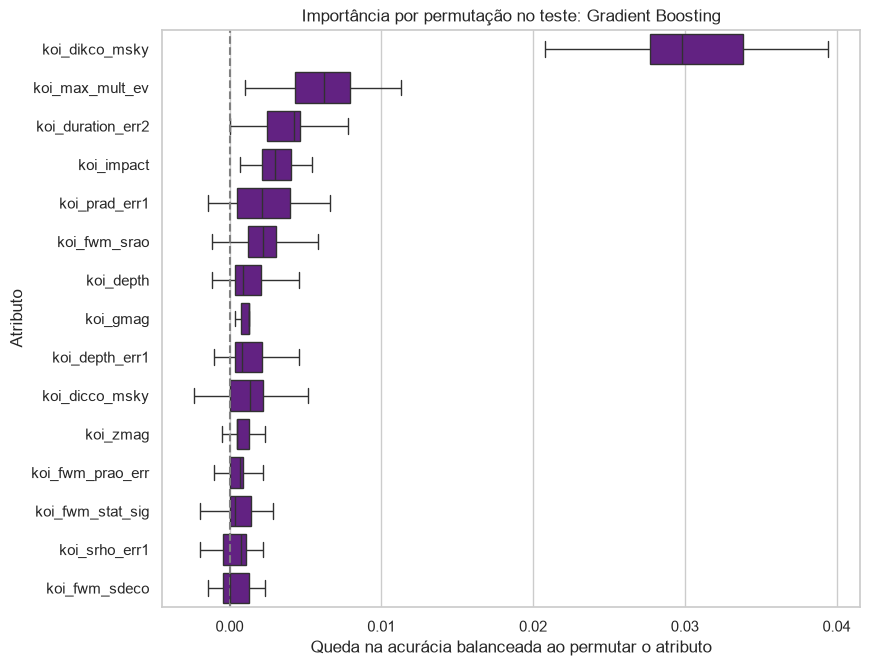

In [138]:
plota_importancia_permutacao(
    importancias_permutacao, resumo_permutacao, NUM_ATRIBUTOS_MOSTRADOS,
    COR_IMPORTANCIA_PERMUTACAO,
    f"Importância por permutação no teste: {MODELO_ESCOLHIDO}",
    "Queda na acurácia balanceada ao permutar o atributo", "Atributo",
)

O gráfico confirma a leitura da tabela: a caixa de `koi_dikco_msky` está muito à direita das demais e não se aproxima de zero em nenhuma repetição, enquanto as caixas dos outros atributos ficam próximas de zero e várias cruzam a linha tracejada.

O significado físico dos atributos mais importantes é coerente com os tipos de falso positivo descritos na seção 2.2 [10]:

- **`koi_dikco_msky`** é a distância angular, em segundos de arco, entre a posição da fonte do trânsito, estimada pelo centroide da imagem de diferença (imagem durante o trânsito menos imagem fora do trânsito), e a posição catalogada da estrela-alvo. Se essa distância é grande, a queda de brilho vem de **outra estrela** na mesma região do céu, como uma binária eclipsante de fundo [3];
- **`koi_fwm_srao`** também é uma medida de deslocamento do centroide: a diferença em ascensão reta entre os centroides ponderados pelo fluxo dentro e fora do trânsito;
- **`koi_max_mult_ev`** é a estatística de múltiplos eventos (MES), que mede a significância do sinal somado em todos os trânsitos. Sinais fracos, próximos do limiar de detecção, são mais suscetíveis a ruído e artefatos instrumentais;
- **`koi_impact`** é o parâmetro de impacto. Valores próximos ou acima de 1 indicam um trânsito rasante, comum em binárias eclipsantes (na seção 4.4, a mediana foi de 0,67 nos falsos positivos e 0,40 nos confirmados);
- **`koi_duration_err2`** e **`koi_prad_err1`** são incertezas (da duração do trânsito e do raio do planeta). Como discutido na seção 2.5, uma incerteza grande pode indicar um ajuste ruim do modelo de trânsito, típico de sinais que não são trânsitos de verdade.

Ou seja, o atributo em que o modelo mais se apoia é justamente uma das medidas usadas pelo processo de classificação para identificar falsos positivos por deslocamento de centroide (a *flag* `koi_fpflag_co`, removida dos atributos por vazar o target). Esse ponto é discutido na seção 11.

As importâncias individuais, em geral pequenas, não significam que o modelo usa pouca informação. Como vários atributos são redundantes (seção 4.6), o modelo pode recorrer a um atributo correlacionado quando outro é embaralhado. A seção 10.2 verifica isso.

### 10.2 Importância de grupos de atributos correlacionados

Para contornar a divisão da importância entre atributos correlacionados, os atributos são reunidos em **grupos de atributos correlacionados**, e cada grupo é embaralhado **de uma vez**, com a mesma ordem de linhas para todos os seus membros [43, 44]. Assim, a relação entre os atributos do grupo é preservada, mas a relação do grupo inteiro com o target é quebrada. Se a informação compartilhada pelo grupo for importante, o modelo não terá mais de onde obtê-la, e a queda será grande.

Os grupos são formados por **agrupamento hierárquico** [45], aplicado aos atributos (e não aos exemplos):

- a distância entre dois atributos é $d_{ij} = 1 - \lvert \rho_{s,ij} \rvert$, em que $\rho_s$ é a correlação de Spearman (seção 4.6). Ela vale 0 para atributos com correlação monotônica perfeita (positiva ou negativa) e 1 para atributos sem correlação monotônica;
- o critério de ligação é a **ligação média**: a distância entre dois grupos é a média das distâncias entre seus membros;
- o dendrograma é cortado na distância $0{,}2$: atributos (ou grupos) cuja distância média é menor que 0,2, isto é, com $\lvert\rho_s\rvert$ médio acima de 0,8, ficam no mesmo grupo.

O agrupamento usa **apenas o conjunto de treino**. O limite de 0,2 é uma escolha: valores menores produzem grupos menores e mais redundantes, e valores maiores juntariam atributos com informações diferentes.

In [139]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform

CRITERIO_LIGACAO = "average"
LIMITE_DISTANCIA_GRUPOS = 0.2

`CRITERIO_LIGACAO` e `LIMITE_DISTANCIA_GRUPOS` definem o critério de ligação e a distância de corte do agrupamento hierárquico.

In [140]:
def agrupa_atributos_correlacionados(X, criterio_ligacao, limite_distancia):

    correlacao = X.corr(method="spearman").fillna(0).values
    distancia = 1 - np.abs(correlacao)
    np.fill_diagonal(distancia, 0)
    distancia = (distancia + distancia.T) / 2

    matriz_conexoes = linkage(squareform(distancia, checks=False), method=criterio_ligacao)
    rotulos = fcluster(matriz_conexoes, t=limite_distancia, criterion="distance")

    grupos = {}
    for rotulo in np.unique(rotulos):
        membros = list(X.columns[rotulos == rotulo])
        grupos[membros[0]] = membros

    return matriz_conexoes, grupos

A função `agrupa_atributos_correlacionados` calcula a matriz de correlação de Spearman, a transforma na matriz de distâncias $1 - \lvert\rho_s\rvert$ e executa o agrupamento hierárquico com o `linkage` do SciPy. Três detalhes técnicos:

- correlações indefinidas (`NaN`) são tratadas como zero, isto é, distância máxima;
- a matriz é simetrizada e a diagonal é zerada, para evitar diferenças numéricas mínimas;
- o `linkage` recebe as distâncias no formato condensado (só o triângulo superior), obtido com `squareform`.

O `fcluster` corta o dendrograma na distância escolhida e devolve o rótulo do grupo de cada atributo. Cada grupo recebe o nome do seu primeiro atributo.

In [141]:
matriz_conexoes_atributos, GRUPOS_ATRIBUTOS = agrupa_atributos_correlacionados(
    X_treino, CRITERIO_LIGACAO, LIMITE_DISTANCIA_GRUPOS
)

tamanhos_grupos = pd.Series({nome: len(membros) for nome, membros in GRUPOS_ATRIBUTOS.items()})

print(f"Número de grupos: {len(GRUPOS_ATRIBUTOS)}")
print(f"Grupos com mais de um atributo: {(tamanhos_grupos > 1).sum()}")

Número de grupos: 43
Grupos com mais de um atributo: 19


Com o corte na distância 0,2, os 89 atributos formam **43 grupos**: **19 grupos com mais de um atributo** e 24 atributos isolados, que não têm correlação forte com nenhum outro.

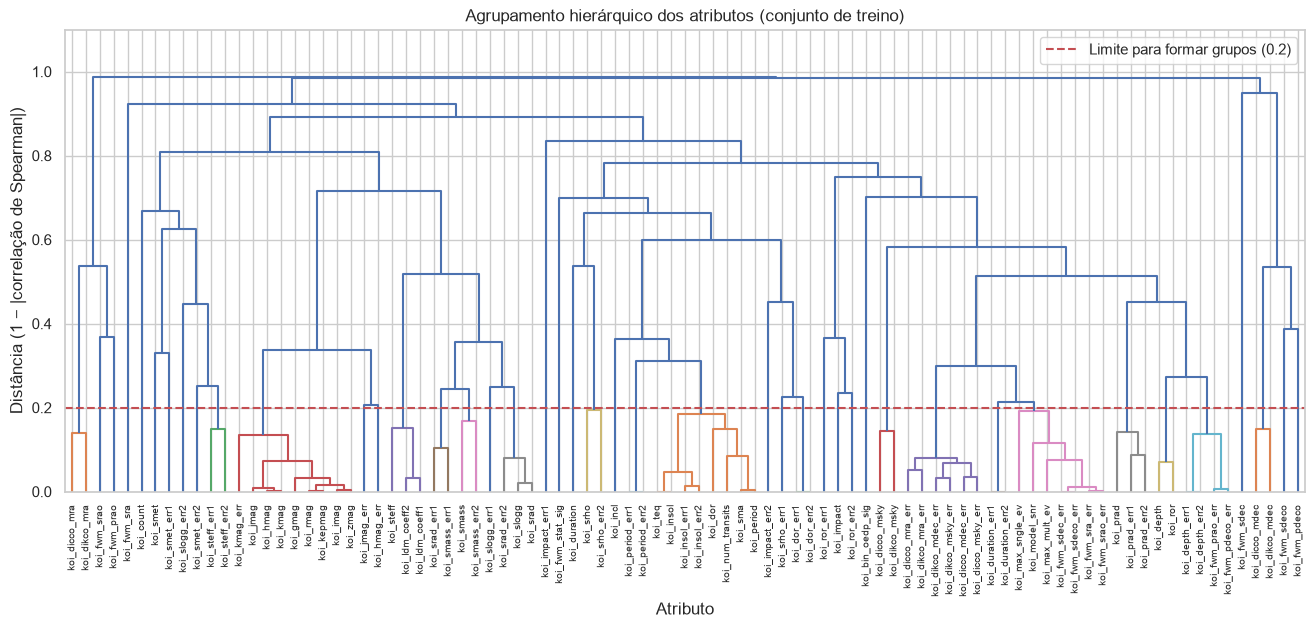

In [142]:
COR_LIMITE_GRUPOS = "#C44E52"

figura, eixo = plt.subplots(figsize=(16, 6))

dendrogram(
    matriz_conexoes_atributos,
    labels=list(X_treino.columns),
    leaf_rotation=90,
    leaf_font_size=7,
    color_threshold=LIMITE_DISTANCIA_GRUPOS,
    ax=eixo,
)
eixo.axhline(LIMITE_DISTANCIA_GRUPOS, color=COR_LIMITE_GRUPOS, linestyle="--",
             label=f"Limite para formar grupos ({LIMITE_DISTANCIA_GRUPOS})")

eixo.set(
    xlabel="Atributo",
    ylabel="Distância (1 − |correlação de Spearman|)",
    title="Agrupamento hierárquico dos atributos (conjunto de treino)",
)
eixo.set_ylim(0, 1.1)
eixo.legend(loc="upper right");

O dendrograma mostra a hierarquia completa do agrupamento. Cada folha (na base) é um atributo, e a altura em que dois ramos se unem é a distância entre eles. Os ramos coloridos abaixo da linha tracejada formam os grupos; os atributos ligados apenas acima dela ficam em grupos isolados.

Abaixo da linha de corte aparecem os blocos de atributos redundantes já identificados no mapa de calor da seção 4.6. Entre eles:

- as **magnitudes** da estrela nas diferentes bandas, que formam um único grupo de 9 atributos (8 magnitudes e uma incerteza);
- os atributos ligados à **órbita**: `koi_period`, `koi_sma` (relacionados pela terceira lei de Kepler), `koi_dor`, `koi_num_transits` (quanto maior o período, menos trânsitos cabem no tempo de observação), `koi_teq` e `koi_insol` (que dependem da distância à estrela), num grupo de 8 atributos;
- os atributos de **intensidade do sinal** (`koi_max_sngle_ev`, `koi_max_mult_ev` e `koi_model_snr`), agrupados com as incertezas de alguns centroides ponderados pelo fluxo;
- o raio do planeta com suas incertezas (`koi_prad`, `koi_prad_err1` e `koi_prad_err2`);
- a profundidade do trânsito com a razão de raios (`koi_depth` e `koi_ror`), coerente com a relação $\delta \approx \text{ror}^2$ (seção 4.5);
- os dois deslocamentos de centroide no céu, `koi_dicco_msky` e `koi_dikco_msky`, e, em outro grupo, as incertezas das medidas de centroide.

A composição completa dos grupos mais importantes aparece na tabela da célula seguinte.

In [143]:
def calcula_importancia_grupos(modelo, X, y, grupos, metrica, num_repeticoes, semente_aleatoria):

    gerador = np.random.default_rng(semente_aleatoria)
    nota_original = metrica(y, modelo.predict(X))

    quedas = {}
    for nome, membros in grupos.items():
        quedas[nome] = []
        for _ in range(num_repeticoes):
            ordem = gerador.permutation(len(X))
            X_permutado = X.copy()
            X_permutado[membros] = X[membros].to_numpy()[ordem]
            quedas[nome].append(nota_original - metrica(y, modelo.predict(X_permutado)))

    return pd.DataFrame(quedas)

A função `calcula_importancia_grupos` implementa a importância por permutação de grupos, que não existe pronta no scikit-learn. Para cada grupo e cada repetição, ela sorteia uma única ordem de linhas (`gerador.permutation`), aplica essa ordem a **todas as colunas do grupo ao mesmo tempo** e calcula a queda da acurácia balanceada em relação à nota original. Para um grupo com um único atributo, o resultado é a importância por permutação comum. São usadas as mesmas 30 repetições e o mesmo conjunto de teste da seção 10.1.

In [144]:
importancias_grupos = carrega_ou_calcula(
    PASTA_CACHE / "importancia_grupos_teste.csv",
    calcula_importancia_grupos,
    modelo_final, X_teste, y_teste, GRUPOS_ATRIBUTOS, balanced_accuracy_score,
    NUM_REPETICOES_PERMUTACAO, SEMENTE_ALEATORIA,
)

resumo_grupos = pd.DataFrame({
    "media": importancias_grupos.mean(),
    "desvio": importancias_grupos.std(),
    "num_atributos": tamanhos_grupos,
    "atributos": pd.Series({nome: ", ".join(membros) for nome, membros in GRUPOS_ATRIBUTOS.items()}),
}).sort_values("media", ascending=False)

resumo_grupos.head(NUM_ATRIBUTOS_MOSTRADOS).round(4)

,media,desvio,num_atributos,atributos
koi_dicco_msky,0.0718,0.0071,2,"koi_dicco_msky, koi_dikco_msky"
koi_prad,0.0199,0.0036,3,"koi_prad, koi_prad_err1, koi_prad_err2"
koi_num_transits,0.0163,0.0030,8,"koi_num_transits, koi_sma, koi_period, koi_dor..."
koi_max_sngle_ev,0.0136,0.0022,7,"koi_max_sngle_ev, koi_max_mult_ev, koi_model_s..."
koi_duration_err1,0.0045,0.0020,2,"koi_duration_err1, koi_duration_err2"
koi_depth_err1,0.0036,0.0019,4,"koi_depth_err1, koi_depth_err2, koi_fwm_prao_e..."
koi_impact,0.0033,0.0015,1,koi_impact
koi_gmag,0.0029,0.0014,9,"koi_gmag, koi_rmag, koi_imag, koi_zmag, koi_jm..."
koi_fwm_srao,0.0025,0.0019,1,koi_fwm_srao
koi_depth,0.0012,0.0017,2,"koi_depth, koi_ror"


Embaralhando os grupos inteiros, a importância muda bastante em relação à seção 10.1:

- o grupo **`koi_dicco_msky` + `koi_dikco_msky`** tem queda de **0,0718 ± 0,0071**, mais que o dobro da soma das importâncias individuais dos dois atributos (0,0302 + 0,0012 = 0,0314). Quando apenas `koi_dikco_msky` é embaralhado, o modelo ainda tem `koi_dicco_msky`, que carrega parte da mesma informação; quando os dois são embaralhados juntos, essa informação desaparece;
- o grupo do **raio do planeta** (`koi_prad` e suas incertezas) tem queda de **0,0199**, embora, individualmente, apenas `koi_prad_err1` apareça entre os 15 atributos mais importantes (com 0,0024);
- o grupo da **órbita** (8 atributos, nomeado por `koi_num_transits`) tem queda de **0,0163**, embora nenhum dos seus atributos apareça entre os 15 mais importantes individualmente. A informação sobre o período está espalhada entre 8 atributos correlacionados, e cada um, sozinho, parece dispensável;
- o grupo da **intensidade do sinal** (nomeado por `koi_max_sngle_ev`) tem queda de **0,0136**, contra 0,0063 de `koi_max_mult_ev` sozinho.

Para os grupos de um único atributo, como `koi_impact` (0,0033 no grupo, 0,0031 individualmente), as duas medidas praticamente coincidem, como esperado: a pequena diferença vem apenas das permutações sorteadas, que são diferentes nos dois cálculos.

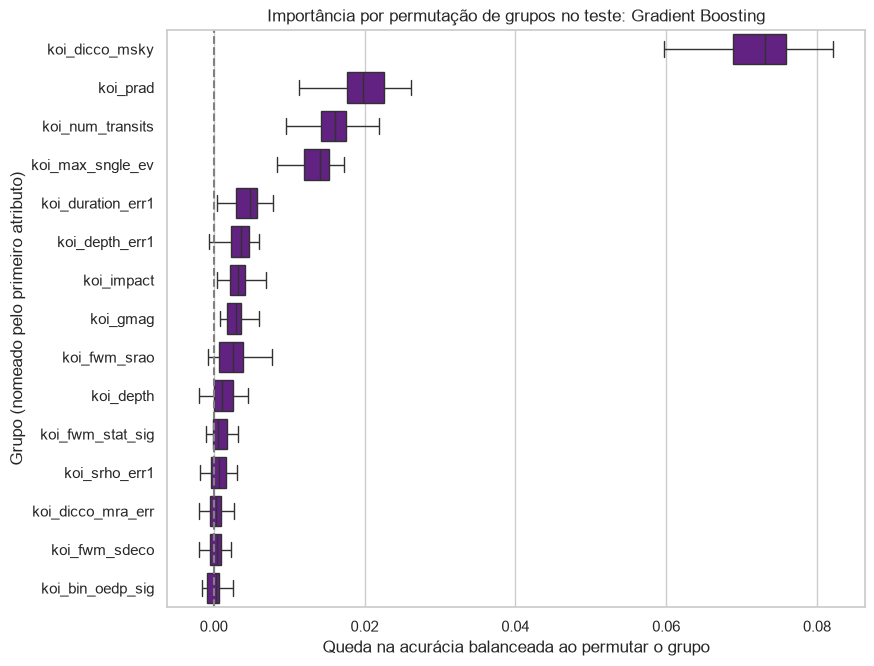

In [145]:
plota_importancia_permutacao(
    importancias_grupos, resumo_grupos, NUM_ATRIBUTOS_MOSTRADOS,
    COR_IMPORTANCIA_PERMUTACAO,
    f"Importância por permutação de grupos no teste: {MODELO_ESCOLHIDO}",
    "Queda na acurácia balanceada ao permutar o grupo", "Grupo (nomeado pelo primeiro atributo)",
)

Com os grupos, a explicação do modelo fica mais clara. Os quatro grupos mais importantes correspondem a quatro pistas físicas diferentes para separar planetas de falsos positivos (seção 2.2):

1. **deslocamento do centroide** (queda de 0,072): o sinal vem de outra estrela, como uma binária eclipsante de fundo [3];
2. **raio do planeta** (0,020): raios implícitos grandes indicam que o objeto em trânsito é uma estrela (na seção 4.4, a mediana foi de 2,17 $R_\oplus$ nos confirmados e 9,32 $R_\oplus$ nos falsos positivos);
3. **órbita** (0,016): falsos positivos têm períodos mais curtos (na seção 4.4, as medianas foram de 5,24 dias nos falsos positivos e 11,33 dias nos confirmados);
4. **intensidade do sinal** (0,014): sinais fracos são mais sujeitos a ruído e artefatos.

Depois desses quatro grupos, a importância cai para menos de 0,005. Assim, o modelo se apoia principalmente em poucas informações fisicamente interpretáveis, e não em detalhes sem significado claro. O deslocamento do centroide é, de longe, a informação mais importante.

### 10.3 Dependência parcial e curvas ICE

As importâncias dizem **quais** atributos o modelo usa, mas não **como**. A **dependência parcial** (PDP, *partial dependence plot*) [38] mostra como a previsão média do modelo muda quando um atributo varia. Sendo $f$ a probabilidade prevista de ser planeta, $j$ o atributo de interesse e $x_{i,-j}$ os demais atributos do exemplo $i$, a dependência parcial no valor $v$ é

$$
\text{PD}_j(v) = \frac{1}{n}\sum_{i=1}^{n} f\left(v,\, x_{i,-j}\right) ,
$$

ou seja: substitui-se o atributo $j$ de **todos** os exemplos pelo valor $v$, mantendo os outros atributos de cada exemplo, e tira-se a média das previsões. Repetindo para uma grade de valores de $v$, obtém-se uma curva.

As **curvas ICE** (*individual conditional expectation*) [46] são as parcelas dessa média: cada curva mostra $f(v, x_{i,-j})$ para um único exemplo $i$. A PDP é a média das curvas ICE. Mostrar as duas juntas revela se o efeito do atributo é parecido em todos os exemplos (curvas paralelas) ou se depende dos outros atributos (curvas com formas diferentes, sinal de **interação**).

Duas limitações devem ser consideradas:

- a PDP supõe que é possível variar o atributo $j$ mantendo os demais fixos. Para atributos correlacionados, isso cria combinações irreais. Por exemplo, mudar a profundidade do trânsito sem mudar a razão de raios, que é praticamente o seu quadrado (seção 4.5);
- como o gradient boosting produz probabilidades muito próximas de 0 ou de 1 para a maior parte dos KOIs, muitas curvas ICE ficam planas nesses extremos: para esses exemplos, mudar um único atributo não é suficiente para mudar a decisão.

As curvas são calculadas com o **conjunto de treino**, porque descrevem o comportamento do modelo ajustado, e não o seu desempenho. São mostrados os quatro atributos de maior importância por permutação individual (seção 10.1).

In [146]:
from scipy.stats import skew
from sklearn.inspection import PartialDependenceDisplay

NUM_ATRIBUTOS_PDP = 4
NUM_COLUNAS_PDP = 2
NUM_CURVAS_ICE = 200
LIMITE_ASSIMETRIA_LOG = 2
COR_CURVAS_ICE = "#9DA9C4"
COR_CURVA_PDP = "#671292"

ATRIBUTOS_PDP = list(resumo_permutacao.index[:NUM_ATRIBUTOS_PDP])
ATRIBUTOS_PDP

['koi_dikco_msky', 'koi_max_mult_ev', 'koi_duration_err2', 'koi_impact']

`NUM_ATRIBUTOS_PDP` define quantos atributos são mostrados, escolhidos automaticamente como os de maior importância média na seção 10.1, e `NUM_COLUNAS_PDP` define quantos gráficos ficam em cada linha da figura. `NUM_CURVAS_ICE` define quantos exemplos, sorteados ao acaso, têm sua curva ICE desenhada (desenhar todas deixaria o gráfico ilegível). `LIMITE_ASSIMETRIA_LOG` define a partir de qual assimetria o eixo horizontal é mostrado em escala logarítmica, como na análise exploratória (seção 4.3).

In [147]:
def plota_dependencia_parcial(modelo, X, atributos, num_colunas, num_curvas_ice, limite_assimetria,
                              cor_ice, cor_pdp, semente_aleatoria):

    X_sem_faltantes = X.dropna(subset=atributos)
    num_linhas = int(np.ceil(len(atributos) / num_colunas))

    figura, eixos = plt.subplots(num_linhas, num_colunas, figsize=(6.5 * num_colunas, 5 * num_linhas),
                                 sharey=True)
    eixos = np.atleast_1d(eixos).ravel()

    PartialDependenceDisplay.from_estimator(
        modelo, X_sem_faltantes, atributos,
        kind="both",
        subsample=num_curvas_ice,
        random_state=semente_aleatoria,
        ice_lines_kw={"color": cor_ice, "alpha": 0.3, "linewidth": 0.5},
        pd_line_kw={"color": cor_pdp, "linewidth": 3, "linestyle": "-", "label": "Média (PDP)"},
        ax=eixos[:len(atributos)],
    )

    for eixo, atributo in zip(eixos, atributos):
        valores = X_sem_faltantes[atributo]
        if valores.min() > 0 and skew(valores) > limite_assimetria:
            eixo.set_xscale("log")
        eixo.set(
            xlabel=atributo,
            ylabel="Probabilidade prevista de ser planeta",
            title=f"Dependência parcial: {atributo}",
        )

    for eixo in eixos[len(atributos):]:
        eixo.set_visible(False)

    figura.tight_layout()

A função `plota_dependencia_parcial` usa o `PartialDependenceDisplay` do scikit-learn [12] com `kind="both"`, que desenha as curvas ICE e a PDP no mesmo eixo. Os gráficos são organizados em uma grade com `NUM_COLUNAS_PDP` colunas, e os eixos que sobrarem na última linha são escondidos. Por padrão, a grade de valores de cada atributo vai do percentil 5 ao percentil 95, para evitar a região dos valores extremos, onde há poucos dados. As marcas na base de cada gráfico mostram os decis do atributo.

Antes do cálculo, são removidos os exemplos com valor faltante em algum dos atributos mostrados: com valores faltantes, as curvas ficam em branco. Os atributos sempre positivos e muito assimétricos são mostrados com o eixo horizontal em escala logarítmica.

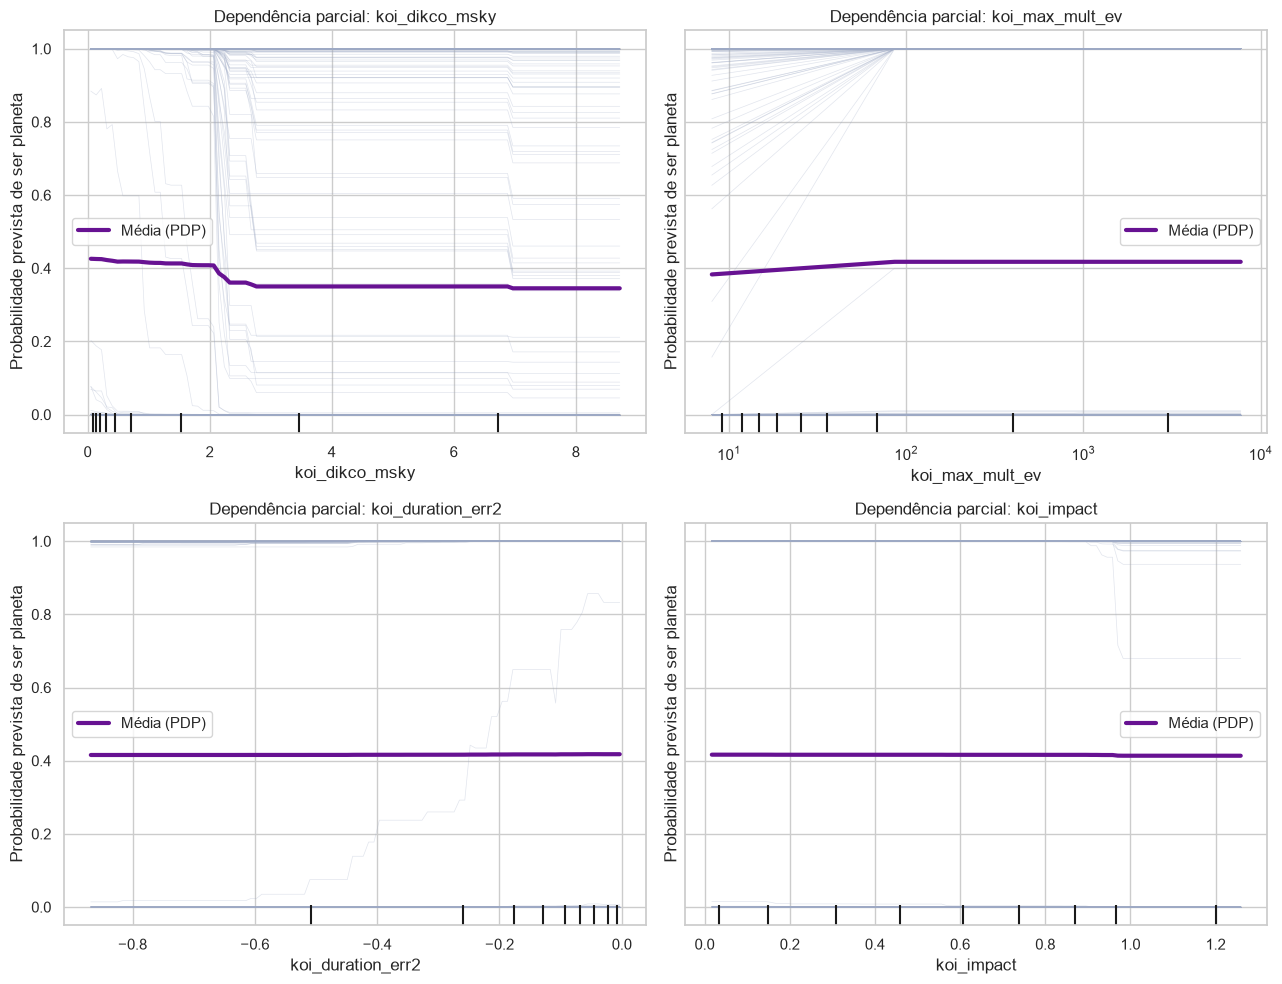

In [148]:
plota_dependencia_parcial(
    modelo_final, X_treino, ATRIBUTOS_PDP, NUM_COLUNAS_PDP, NUM_CURVAS_ICE, LIMITE_ASSIMETRIA_LOG,
    COR_CURVAS_ICE, COR_CURVA_PDP, SEMENTE_ALEATORIA,
)

A célula abaixo calcula duas informações do conjunto de treino que ajudam a ler os gráficos: quantos KOIs foram usados nas curvas (os que não têm valor faltante nos quatro atributos) e a proporção de confirmados entre eles; e, para o atributo mais importante, a mediana por classe e a fração de KOIs com deslocamento acima de 2 segundos de arco, valor em que as curvas ICE de `koi_dikco_msky` mudam de comportamento.

In [149]:
ATRIBUTO_CENTROIDE = "koi_dikco_msky"
LIMITE_DESLOCAMENTO_ARCSEC = 2

X_pdp = X_treino.dropna(subset=ATRIBUTOS_PDP)
y_pdp = y_treino.loc[X_pdp.index]
y_excluidos = y_treino.drop(X_pdp.index)

print(f"KOIs de treino usados nas curvas: {len(X_pdp)} de {len(X_treino)}")
print(f"Proporção de confirmados entre eles: {y_pdp.mean():.3f}")
print(f"Proporção de confirmados entre os excluídos: {y_excluidos.mean():.3f}")

classes_treino = y_treino.map(NOMES_CLASSES)

pd.DataFrame({
    "mediana": X_treino.groupby(classes_treino)[ATRIBUTO_CENTROIDE].median(),
    "fracao_acima_do_limite": (X_treino[ATRIBUTO_CENTROIDE] > LIMITE_DESLOCAMENTO_ARCSEC).groupby(classes_treino).mean(),
}).round(3)

KOIs de treino usados nas curvas: 5249 de 6070
Proporção de confirmados entre eles: 0.416
Proporção de confirmados entre os excluídos: 0.018


,mediana,fracao_acima_do_limite
koi_disposition,,
Confirmado,0.320,0.014
Falso positivo,1.504,0.393


As curvas foram calculadas com **5.249 dos 6.070 KOIs de treino**, os que não têm valor faltante nos quatro atributos. Entre eles, **41,6% são confirmados**, contra 1,8% entre os KOIs excluídos, porque os valores faltantes são muito mais comuns nos falsos positivos (seção 4.2). Isso explica por que as curvas de PDP ficam em torno de 0,4, e não da proporção de confirmados do treino inteiro (36,2%).

- **`koi_dikco_msky`:** é o único atributo com um efeito médio claro. A PDP cai de cerca de 0,43, para deslocamentos próximos de zero, para cerca de 0,35 a partir de aproximadamente 3 segundos de arco. As curvas ICE mostram que a mudança se concentra **entre cerca de 2 e 3 segundos de arco**: nessa faixa, muitas curvas descem de probabilidades próximas de 1 para valores baixos. Esse comportamento concorda com os dados: no treino, a mediana do deslocamento é de 1,50" nos falsos positivos e de 0,32" nos confirmados, e **39,3% dos falsos positivos** têm deslocamento acima de 2", contra apenas **1,4% dos confirmados**. Fisicamente, um deslocamento de alguns segundos de arco indica que a fonte do trânsito não coincide com a estrela-alvo.
- **`koi_max_mult_ev`:** a PDP sobe levemente, de cerca de 0,39 para 0,42, até uma estatística de múltiplos eventos de aproximadamente 100, e fica constante depois disso. As curvas ICE mostram que, para alguns KOIs, uma estatística baixa reduz a probabilidade de ser planeta, que volta a ficar próxima de 1 quando a estatística aumenta. Ou seja, o modelo desconfia de sinais pouco significativos.
- **`koi_duration_err2` e `koi_impact`:** a PDP é praticamente constante, e apenas poucas curvas ICE variam. Para `koi_impact`, algumas curvas próximas de 1 caem para valores de impacto próximos ou acima de 1, a região dos trânsitos rasantes.

O fato de a maioria das curvas ICE ficar plana em 0 ou em 1 mostra que, para a maior parte dos KOIs, mudar **um único** atributo não muda a decisão do modelo: ele tem várias evidências concordantes e atributos redundantes (seção 10.2). A importância por permutação desses atributos provavelmente vem de uma minoria de KOIs próximos da fronteira de decisão, justamente os casos em que um atributo a mais pode mudar a classe prevista.

### 10.4 Síntese da explicabilidade

As três ferramentas levam a uma interpretação consistente do modelo final:

1. **O deslocamento do centroide é a principal informação usada pelo modelo.** Ele é o atributo individual mais importante (seção 10.1), o grupo mais importante (seção 10.2) e o único atributo com efeito médio claro na dependência parcial (seção 10.3). A probabilidade de ser planeta cai quando a fonte do trânsito está a mais de 2 a 3 segundos de arco da estrela-alvo, coerente com a identificação de binárias eclipsantes de fundo [3].
2. **Além do centroide, o modelo usa o raio do planeta, a órbita e a intensidade do sinal**, informações que só aparecem com clareza quando os atributos correlacionados são avaliados em grupo. A importância por permutação individual, sozinha, teria subestimado essas informações.
3. **O modelo se apoia em atributos com significado físico**, que correspondem às pistas usadas pelos astrônomos para identificar falsos positivos (seção 2.2), e não em artefatos sem interpretação.
4. **As explicações têm limitações:** os resultados descrevem o comportamento do modelo, e não relações causais; atributos correlacionados dividem a importância; e a PDP supõe que um atributo pode variar com os demais fixos, o que nem sempre é realista.

Essa interpretação também ajuda a entender os erros da seção 9.5: o modelo identifica bem os falsos positivos que deixam pistas nos atributos do próprio KOI (centroide, raio, órbita e intensidade do sinal), mas não os identificados por uma evidência externa, como a coincidência de efemérides com outro objeto.

Por fim, a seção 4.7 deixou em aberto o papel do atributo `koi_count` (número de KOIs na mesma estrela), que carrega a informação de multiplicidade. Ele não aparece entre os 15 atributos nem entre os 15 grupos mais importantes (seções 10.1 e 10.2). Ou seja, embora a multiplicidade esteja fortemente associada ao alvo no treino, o modelo final pouco depende dela, provavelmente porque as demais pistas já são suficientes para a maioria dos KOIs.

## <b>11. Discussão e limitações</b>

Esta seção discute o significado dos resultados, compara o trabalho com estudos anteriores e reúne as limitações encontradas ao longo do notebook, incluindo uma verificação feita depois da otimização (seção 11.4).

### 11.1 Síntese dos resultados

Cinco algoritmos foram comparados na tarefa de separar planetas confirmados de falsos positivos entre os KOIs do Kepler, com 100 trials de otimização cada um e pipelines de pré-processamento controlados pelo Optuna. Os principais resultados foram:

- **Todos os algoritmos superaram os baselines ingênuos**, e quatro dos cinco superaram o baseline forte (regressão logística, com acurácia balanceada de 0,949 na validação cruzada). A exceção foi a árvore de decisão (0,947), o que mostra que um modelo mais complexo não é automaticamente melhor que um modelo linear bem regularizado.
- **O gradient boosting foi o melhor modelo** na validação cruzada (0,976), vencendo o segundo colocado (SVM, 0,972) em todas as dobras e em todas as métricas, mas por uma margem pequena (seção 8.4).
- **No teste, o desempenho se manteve:** acurácia balanceada de 0,979, com intervalo de confiança de 95% de [0,971; 0,986], contra 0,954 da regressão logística (seção 9). A nota do teste é compatível com a da validação cruzada, sem sinal de sobreajuste.
- **O pré-processamento importou mais nos modelos baseados em distâncias.** O kNN e o SVM tiveram os maiores ganhos com a otimização (+0,038 e +0,023), principalmente pela transformação de potência, enquanto os conjuntos de árvores já tinham bom desempenho com os hiperparâmetros padrão (seção 8.3).
- **O modelo final se apoia em informações fisicamente interpretáveis**, sobretudo no deslocamento do centroide (seção 10).

Um ponto deve ser destacado: com hiperparâmetros padrão, o gradient boosting já tinha acurácia balanceada de 0,9735 (seção 5.6.2). A otimização com 100 trials elevou essa nota para 0,9764, um ganho pequeno e da mesma ordem da variação entre as dobras. Para este conjunto de dados, a escolha do **algoritmo** e, nos modelos baseados em distâncias, a escolha do **pré-processamento** foram mais importantes que o ajuste fino dos hiperparâmetros.

### 11.2 Relação com trabalhos anteriores

Este trabalho segue a abordagem de McCauliff et al. [7], que também usaram atributos tabulares calculados pelo pipeline do Kepler e florestas aleatórias para classificar sinais de trânsito. Shallue e Vanderburg [8], por outro lado, usaram redes neurais convolucionais diretamente sobre as curvas de luz, sem depender de atributos calculados previamente. O processo de classificação que gerou os rótulos usados aqui combina o Robovetter, um conjunto de testes automáticos baseado em regras [4, 5], com análises adicionais e observações de acompanhamento [6].

Os resultados deste trabalho **não são diretamente comparáveis** com os desses estudos, por três motivos: o conjunto de dados é outro (a tabela cumulativa, e não um catálogo específico), os rótulos são diferentes (planetas confirmados contra falsos positivos, sem os candidatos) e as métricas relatadas não são as mesmas. A contribuição deste trabalho não é um classificador melhor que os existentes, e sim uma **comparação controlada** de algoritmos e pré-processamentos no mesmo conjunto de dados, com as mesmas dobras, a mesma métrica e um conjunto de teste usado uma única vez.

### 11.3 O que o modelo aprende e o que ele não pode aprender

**Os rótulos são o veredito do processo de classificação, e não a verdade.** Como discutido na seção 2.3, o modelo aprende a **reproduzir** esse veredito. Se houver KOIs classificados incorretamente, o modelo aprende esses erros, e eles também afetam a avaliação. A análise da seção 9.5 mostra que essa distinção não é só teórica: os cinco planetas que o modelo errou com mais confiança foram considerados **candidatos** com base apenas nos dados do Kepler e só foram confirmados depois, com informações que não fazem parte deste conjunto de dados.

**O modelo reaprende parte dos critérios do processo de classificação.** As *flags* de falso positivo foram removidas por vazarem o target (seção 2.5), mas as **medidas** que deram origem a algumas delas continuaram entre os atributos. O exemplo mais claro é o deslocamento do centroide: a *flag* `koi_fpflag_co` indica justamente que a fonte do sinal é uma estrela próxima, inferida a partir da posição do centroide [10], e `koi_dikco_msky` foi o atributo mais importante do modelo (seção 10). Isso não é vazamento, porque as medidas existem antes do veredito e estariam disponíveis para um KOI novo. Mas significa que parte do bom desempenho vem de o modelo reaprender, a partir das medidas, regras que o próprio processo de classificação já aplica.

**Falsos positivos identificados por informações externas ao KOI não podem ser detectados.** Três dos cinco falsos positivos que o modelo classificou como planeta com mais confiança foram identificados pela coincidência de efemérides com outro objeto (seção 9.5). Essa evidência depende de comparar o período e a época do KOI com os de outros objetos do catálogo, e nenhum atributo individual de um KOI carrega essa informação.

**Os candidatos ficaram de fora.** O modelo foi treinado e avaliado apenas com KOIs que já têm veredito. Os candidatos (1.977 KOIs) são, em geral, os casos mais difíceis, aqueles para os quais o processo de classificação ainda não chegou a uma conclusão. Aplicar o modelo a eles seria uma **extrapolação** para uma região em que o seu desempenho não foi medido, e as notas deste trabalho não devem ser usadas como estimativa do desempenho nesses casos.

### 11.4 Verificação: coordenadas no céu entre os atributos

Durante a preparação da análise de explicabilidade, foram identificadas entre os atributos as colunas `koi_fwm_sra` e `koi_fwm_sdec` (com suas incertezas). Elas são a ascensão reta e a declinação da fonte do trânsito, calculadas a partir dos centroides ponderados pelo fluxo [10], ou seja, uma **posição no céu**. Pelo critério da seção 2.5, elas deveriam ter sido removidas junto com `ra` e `dec`, mas passaram despercebidas na seleção de colunas.

A decisão sobre essas colunas foi tomada **antes de qualquer uso do conjunto de teste**: elas foram mantidas, para não refazer as otimizações, e o seu efeito foi verificado. A célula abaixo avalia o gradient boosting com os hiperparâmetros padrão (o mesmo modelo do Teste A, seção 5.6.2) na validação cruzada, com e sem as quatro colunas, e compara os dois com a função `calcula_separacao`. Apenas o conjunto de treino é usado.

In [150]:
COLUNAS_COORDENADAS = ["koi_fwm_sra", "koi_fwm_sra_err", "koi_fwm_sdec", "koi_fwm_sdec_err"]
ATRIBUTOS_SEM_COORDENADAS = [atributo for atributo in ATRIBUTOS if atributo not in COLUNAS_COORDENADAS]

notas_coordenadas = {
    "Com coordenadas": avalia_modelo(
        HistGradientBoostingClassifier(random_state=SEMENTE_ALEATORIA),
        X_treino, y_treino, grupos_treino, cv, METRICAS,
    ),
    "Sem coordenadas": avalia_modelo(
        HistGradientBoostingClassifier(random_state=SEMENTE_ALEATORIA),
        X_treino[ATRIBUTOS_SEM_COORDENADAS], y_treino, grupos_treino, cv, METRICAS,
    ),
}

calcula_separacao(notas_coordenadas, "Com coordenadas", "Sem coordenadas", METRICAS_COMPARADAS).round(4)

,metrica,diferenca_media,desvio_da_diferenca,separacao,dobras_a_favor_de_a
0,acuracia_balanceada,-0.0013,0.0021,-0.6100,1
1,f1,-0.0016,0.0028,-0.5663,1
2,precisao_media,0.0004,0.0005,0.8063,4
3,roc_auc,0.0003,0.0003,0.8376,4


A diferença entre os dois modelos ficou dentro do ruído entre as dobras em todas as métricas. Na acurácia balanceada, o modelo **com** coordenadas teve 0,9735 (o mesmo valor do Teste A) e o modelo **sem** coordenadas teve 0,9748: a diferença média foi de −0,0013, com desvio-padrão de 0,0021 entre as dobras (separação de −0,61), e o modelo com coordenadas venceu em apenas 1 das 5 dobras. Nas outras métricas, as separações também ficaram abaixo de 1 em valor absoluto.

Portanto, a posição no céu não trouxe vantagem ao modelo. Isso é coerente com a seção 10, em que nenhuma dessas colunas apareceu entre os atributos ou grupos mais importantes. Ainda assim, em uma versão futura do trabalho, elas devem ser removidas desde o início, junto com as demais coordenadas.

### 11.5 Limitações metodológicas

**Instabilidade numérica da seleção por VIF.** Com atributos fortemente correlacionados, a matriz de correlação usada pelo `SelecionadorVIF` fica quase singular, e os atributos selecionados podem mudar com diferenças mínimas de arredondamento numérico. Isso explica a diferença entre a nota do Optuna e a nota reavaliada do gradient boosting (seção 8.2) e impede que o modelo final seja reproduzido exatamente em outro computador. Uma implementação mais estável calcularia o VIF por regressão, removeria antes os atributos perfeitamente correlacionados ou usaria uma regularização maior na inversão da matriz.

**Reprodutibilidade entre computadores e versões.** A otimização foi dividida entre dois computadores, com as mesmas versões das bibliotecas (seção 5.5). Em um teste com versões mais novas (Optuna 5.1.0 e scikit-learn 1.9.1), a melhor nota do kNN foi de 0,9669, contra 0,9644 com as versões usadas neste trabalho (Optuna 5.0.0 e scikit-learn 1.9.0), provavelmente porque mudanças internas do amostrador alteram a sequência de trials sorteados. Por isso, as versões usadas estão registradas no `requirements.txt`, e os resultados exatos dependem delas.

**Limites da otimização.** Foram feitos 100 trials por algoritmo, com uma única semente. O TPE concentra a busca nas regiões que vão bem no início, e algumas opções foram pouco exploradas (por exemplo, na árvore de decisão, 92 dos 100 trials usaram a seleção por VIF). Outras sementes ou mais trials poderiam levar a configurações um pouco diferentes. Além disso, o número de árvores da floresta foi limitado a 300 por custo computacional (seção 5.5). Como a melhor nota de cada estudo é o máximo de 100 trials, ela é otimista (seção 7), e as diferenças pequenas entre os melhores modelos devem ser lidas com cautela.

**Uma única divisão treino/teste.** O conjunto de teste foi separado uma única vez, com a semente 810. O intervalo de confiança da seção 9.2 mede a incerteza devida à amostra de teste, mas não a variação que viria de outra divisão ou de treinar o modelo com outros dados. Uma estimativa mais completa usaria, por exemplo, validação cruzada aninhada, a um custo computacional muito maior.

**Limiar de decisão.** Todas as métricas baseadas na classe prevista usam o limiar padrão de 0,5. Em uma aplicação real, o limiar poderia ser escolhido conforme o custo de cada tipo de erro (perder um planeta ou gastar tempo de observação com um falso positivo), usando a validação cruzada no treino.

**Limites das ferramentas de explicação.** A importância por permutação e a dependência parcial foram calculadas para um único modelo ajustado e descrevem o comportamento desse modelo, e não relações causais. Os grupos de atributos dependem do limite de distância escolhido (0,2), e a dependência parcial supõe que um atributo pode variar com os demais fixos, o que cria combinações irreais para atributos correlacionados (seção 10.3).

### 11.6 Trabalhos futuros

A partir das limitações acima, alguns caminhos para continuar o trabalho são:

1. **remover as coordenadas no céu** (`koi_fwm_sra` e `koi_fwm_sdec`) desde a seleção de colunas;
2. **tornar a seleção por VIF numericamente estável**, para que o modelo final possa ser reproduzido exatamente em qualquer computador;
3. **repetir a otimização com outras sementes** e usar validação cruzada aninhada, para medir a variação dos resultados com a divisão dos dados e com a busca;
4. **escolher o limiar de decisão** de acordo com os custos de cada tipo de erro, usando apenas o conjunto de treino;
5. **avaliar o efeito de remover as medidas de centroide**, para saber quanto do desempenho depende delas e quanto vem das demais informações do sinal;
6. **aplicar o modelo aos candidatos** apenas como forma de **priorizar** observações de acompanhamento, e não como veredito, já que seu desempenho nesses casos não foi medido.

## <b>12. Descrição do uso de IA neste trabalho</b>

Este trabalho foi desenvolvido com o apoio do assistente de inteligência artificial **Claude**, da Anthropic [47], usado em conversas ao longo de todo o projeto. Esta seção descreve como foi essa interação, para que fique claro o que foi feito pela autora e o que foi feito com o auxílio da IA.

**Escolha do conjunto de dados e planejamento.** A IA foi usada para discutir conjuntos de dados que atendessem aos requisitos do enunciado. Além do conjunto de KOIs do Kepler, foram considerados e descartados um conjunto de neurociência (Allen Cell Types) e um de astronomia (SDSS DR17). A IA também foi usada para debater quais itens da pontuação complementar fazer e para planejar a estrutura do notebook, em formato de artigo.

**Código.** Os módulos `src/data.py`, `src/pipelines.py` e `src/optimize.py` e as funções do notebook foram escritos com o auxilio da IA, seguindo o estilo dos notebooks da disciplina (constantes em maiúsculas, nomes em português e gráficos com título e rótulos nos eixos). A IA testou o código em um ambiente próprio antes de entregá-lo, e a autora executou todo o notebook e as otimizações em seus computadores. Os resultados apresentados são os obtidos pela autora. Ao longo do trabalho, a IA também ajudou a encontrar e corrigir erros, como incompatibilidades com a versão do scikit-learn, curvas de dependência parcial em branco por causa de valores faltantes e a instabilidade numérica da seleção por VIF (seção 8.2). Alguns erros foram da própria IA e foram corrigidos durante o processo, como a falta de atenção às colunas de coordenadas `koi_fwm_sra` e `koi_fwm_sdec` na seleção de atributos (seção 11.4), os quais foram percebidos pela propria autora.

**Textos.** Os textos explicativos das seções foram corrigidos com a IA a partir dos resultados obtidos pela autora e do material da disciplina, e foram revisados e ajustados pela autora mesmo após a correção. A IA também foi usada para auxiliar ao explicar os conceitos, com as justificativas matemáticas, para que a autora pudesse compreender e defender cada escolha. Algumas referências bibliográficas foram sugeridas pela IA e conferidas.

**Decisões.** As decisões do trabalho (o conjunto de dados, a definição do alvo, a métrica principal, os itens complementares e a decisão sobre as colunas de coordenadas) foram discutidas com a IA e tomadas pela autora.

**Uso do conjunto de teste pela IA.** Depois que a autora executou a avaliação final (seção 9), a IA acessou o conjunto de teste em dois momentos, ambos **apenas para verificação e interpretação**, sem alterar o modelo: (1) para reproduzir o intervalo de confiança do bootstrap e confirmar que ele era coerente; e (2) para consultar as colunas do processo de classificação dos erros mais confiantes, o que deu origem à tabela incluída na seção 9.5. A verificação das colunas de coordenadas (seção 11.4) usou apenas o conjunto de treino.

**Responsabilidade.** A autora é responsável por todo o conteúdo do trabalho e conferiu os códigos, os resultados e os textos.

## <b>13. Referências</b>

[1] BORUCKI, W. J. et al. Kepler planet-detection mission: introduction and first results. **Science**, v. 327, n. 5968, p. 977-980, 2010. DOI: 10.1126/science.1185402.

[2] SEAGER, S.; MALLÉN-ORNELAS, G. A unique solution of planet and star parameters from an extrasolar planet transit light curve. **The Astrophysical Journal**, v. 585, n. 2, p. 1038-1055, 2003. DOI: 10.1086/346105.

[3] BRYSON, S. T. et al. Identification of background false positives from Kepler data. **Publications of the Astronomical Society of the Pacific**, v. 125, n. 930, p. 889-923, 2013. DOI: 10.1086/671767.

[4] COUGHLIN, J. L. et al. Planetary candidates observed by Kepler. VII. The first fully uniform catalog based on the entire 48-month data set (Q1-Q17 DR24). **The Astrophysical Journal Supplement Series**, v. 224, n. 1, art. 12, 2016. DOI: 10.3847/0067-0049/224/1/12.

[5] THOMPSON, S. E. et al. Planetary candidates observed by Kepler. VIII. A fully automated catalog with measured completeness and reliability based on Data Release 25. **The Astrophysical Journal Supplement Series**, v. 235, n. 2, art. 38, 2018. DOI: 10.3847/1538-4365/aab4f9.

[6] MORTON, T. D. et al. False positive probabilities for all Kepler objects of interest: 1284 newly validated planets and 428 likely false positives. **The Astrophysical Journal**, v. 822, n. 2, art. 86, 2016. DOI: 10.3847/0004-637X/822/2/86.

[7] McCAULIFF, S. D. et al. Automatic classification of Kepler planetary transit candidates. **The Astrophysical Journal**, v. 806, n. 1, art. 6, 2015. DOI: 10.1088/0004-637X/806/1/6.

[8] SHALLUE, C. J.; VANDERBURG, A. Identifying exoplanets with deep learning: a five-planet resonant chain around Kepler-80 and an eighth planet around Kepler-90. **The Astronomical Journal**, v. 155, n. 2, art. 94, 2018. DOI: 10.3847/1538-3881/aa9e09.

[9] NASA EXOPLANET ARCHIVE. **Kepler Objects of Interest Cumulative Table**. Pasadena: NExScI-Caltech/IPAC, [20--]. DOI: 10.26133/NEA4. Disponível em: https://exoplanetarchive.ipac.caltech.edu/. Acesso em: 10 set. 2026.

[10] NASA EXOPLANET ARCHIVE. **Data columns in the Kepler Objects of Interest table (cumulative)**. Pasadena: NExScI-Caltech/IPAC, [20--]. Disponível em: https://exoplanetarchive.ipac.caltech.edu/docs/API_kepcandidate_columns.html. Acesso em: 22 nov. 2026.

[11] KAUFMAN, S. et al. Leakage in data mining: formulation, detection, and avoidance. **ACM Transactions on Knowledge Discovery from Data**, v. 6, n. 4, art. 15, 2012. DOI: 10.1145/2382577.2382579.

[12] PEDREGOSA, F. et al. Scikit-learn: machine learning in Python. **Journal of Machine Learning Research**, v. 12, p. 2825-2830, 2011.

[13] CASSAR, D. R. **Vazamento de dados**. Notebook Jupyter (ATP-203 6.1) da disciplina Aprendizado de Máquina. Campinas: Ilum Escola de Ciência, [2026]. Material didático.

[14] AGGARWAL, C. C.; HINNEBURG, A.; KEIM, D. A. On the surprising behavior of distance metrics in high dimensional space. In: VAN DEN BUSSCHE, J.; VIANU, V. (ed.). **Database Theory — ICDT 2001**. Berlin: Springer, 2001. p. 420-434. DOI: 10.1007/3-540-44503-X_27.

[15] MANN, H. B.; WHITNEY, D. R. On a test of whether one of two random variables is stochastically larger than the other. **The Annals of Mathematical Statistics**, v. 18, n. 1, p. 50-60, 1947. DOI: 10.1214/aoms/1177730491.

[16] LITTLE, R. J. A.; RUBIN, D. B. **Statistical analysis with missing data**. 3. ed. Hoboken: Wiley, 2019.

[17] JOANES, D. N.; GILL, C. A. Comparing measures of sample skewness and kurtosis. **Journal of the Royal Statistical Society: Series D (The Statistician)**, v. 47, n. 1, p. 183-189, 1998. DOI: 10.1111/1467-9884.00122.

[18] YEO, I.-K.; JOHNSON, R. A. A new family of power transformations to improve normality or symmetry. **Biometrika**, v. 87, n. 4, p. 954-959, 2000. DOI: 10.1093/biomet/87.4.954.

[19] SPEARMAN, C. The proof and measurement of association between two things. **The American Journal of Psychology**, v. 15, n. 1, p. 72-101, 1904. DOI: 10.2307/1412159.

[20] LISSAUER, J. J. et al. Almost all of Kepler's multiple-planet candidates are planets. **The Astrophysical Journal**, v. 750, n. 2, art. 112, 2012. DOI: 10.1088/0004-637X/750/2/112.

[21] CASSAR, D. R. **Dados sintéticos e pipeline**. Notebook Jupyter (ATP-203 7.0) da disciplina Aprendizado de Máquina. Campinas: Ilum Escola de Ciência, [2026]. Material didático.

[22] CASSAR, D. R. **Redução de dimensionalidade com PCA**. Notebook Jupyter (ATP-203 8.0) da disciplina Aprendizado de Máquina. Campinas: Ilum Escola de Ciência, [2026]. Material didático.

[23] CASSAR, D. R. **Seleção de atributos**. Notebook Jupyter (ATP-203 8.1) da disciplina Aprendizado de Máquina. Campinas: Ilum Escola de Ciência, [2026]. Material didático.

[24] GUYON, I. et al. Gene selection for cancer classification using support vector machines. **Machine Learning**, v. 46, p. 389-422, 2002. DOI: 10.1023/A:1012487302797.

[25] AKIBA, T. et al. Optuna: a next-generation hyperparameter optimization framework. In: ACM SIGKDD INTERNATIONAL CONFERENCE ON KNOWLEDGE DISCOVERY & DATA MINING, 25., 2019, Anchorage. **Proceedings** [...]. New York: ACM, 2019. p. 2623-2631. DOI: 10.1145/3292500.3330701.

[26] CASSAR, D. R. **Validação cruzada e otimização de hiperparâmetros**. Notebook Jupyter (ATP-203 6.0) da disciplina Aprendizado de Máquina. Campinas: Ilum Escola de Ciência, [2026]. Material didático.

[27] BRODERSEN, K. H. et al. The balanced accuracy and its posterior distribution. In: INTERNATIONAL CONFERENCE ON PATTERN RECOGNITION, 20., 2010, Istanbul. **Proceedings** [...]. Los Alamitos: IEEE, 2010. p. 3121-3124. DOI: 10.1109/ICPR.2010.764.

[28] CASSAR, D. R. **Outras métricas**. Notebook Jupyter (ATP-203 9.0) da disciplina Aprendizado de Máquina. Campinas: Ilum Escola de Ciência, [2026]. Material didático.

[29] CASSAR, D. R. **Otimização de hiperparâmetros com Optuna**. Notebook Jupyter (ATP-203 7.1) da disciplina Aprendizado de Máquina. Campinas: Ilum Escola de Ciência, [2026]. Material didático.

[30] BERGSTRA, J.; BARDENET, R.; BENGIO, Y.; KÉGL, B. Algorithms for hyper-parameter optimization. In: **Advances in Neural Information Processing Systems 24 (NIPS 2011)**. Red Hook: Curran Associates, 2011. p. 2546-2554.

[31] CAWLEY, G. C.; TALBOT, N. L. C. On over-fitting in model selection and subsequent selection bias in performance evaluation. **Journal of Machine Learning Research**, v. 11, n. 70, p. 2079-2107, 2010.

[32] CASSAR, D. R. **Modelo linear e baseline**. Notebook Jupyter (ATP-203 3.0) da disciplina Aprendizado de Máquina. Campinas: Ilum Escola de Ciência, [2026]. Material didático.

[33] HUTTER, F.; HOOS, H.; LEYTON-BROWN, K. An efficient approach for assessing hyperparameter importance. In: INTERNATIONAL CONFERENCE ON MACHINE LEARNING, 31., 2014, Beijing. **Proceedings of Machine Learning Research**, v. 32, n. 1, p. 754-762, 2014.

[34] COVER, T. M.; HART, P. E. Nearest neighbor pattern classification. **IEEE Transactions on Information Theory**, v. 13, n. 1, p. 21-27, 1967. DOI: 10.1109/TIT.1967.1053964.

[35] CASSAR, D. R. **Árvore de decisão e floresta aleatória**. Notebook Jupyter (ATP-203 4.0) da disciplina Aprendizado de Máquina. Campinas: Ilum Escola de Ciência, [2026]. Material didático.

[36] BREIMAN, L. Random forests. **Machine Learning**, v. 45, n. 1, p. 5-32, 2001. DOI: 10.1023/A:1010933404324.

[37] HASTIE, T.; TIBSHIRANI, R.; FRIEDMAN, J. **The elements of statistical learning**: data mining, inference, and prediction. 2. ed. New York: Springer, 2009.

[38] FRIEDMAN, J. H. Greedy function approximation: a gradient boosting machine. **The Annals of Statistics**, v. 29, n. 5, p. 1189-1232, 2001. DOI: 10.1214/aos/1013203451.

[39] CORTES, C.; VAPNIK, V. Support-vector networks. **Machine Learning**, v. 20, n. 3, p. 273-297, 1995. DOI: 10.1007/BF00994018.

[40] EFRON, B.; TIBSHIRANI, R. J. **An introduction to the bootstrap**. New York: Chapman & Hall, 1993.

[41] FAWCETT, T. An introduction to ROC analysis. **Pattern Recognition Letters**, v. 27, n. 8, p. 861-874, 2006. DOI: 10.1016/j.patrec.2005.10.010.

[42] SAITO, T.; REHMSMEIER, M. The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. **PLoS ONE**, v. 10, n. 3, e0118432, 2015. DOI: 10.1371/journal.pone.0118432.

[43] FISHER, A.; RUDIN, C.; DOMINICI, F. All models are wrong, but many are useful: learning a variable's importance by studying an entire class of prediction models simultaneously. **Journal of Machine Learning Research**, v. 20, n. 177, p. 1-81, 2019.

[44] STROBL, C. et al. Conditional variable importance for random forests. **BMC Bioinformatics**, v. 9, art. 307, 2008. DOI: 10.1186/1471-2105-9-307.

[45] CASSAR, D. R. **Agrupamento**. Notebook Jupyter (ATP-203 A.0) da disciplina Aprendizado de Máquina. Campinas: Ilum Escola de Ciência, [2026]. Material didático.

[46] GOLDSTEIN, A. et al. Peeking inside the black box: visualizing statistical learning with plots of individual conditional expectation. **Journal of Computational and Graphical Statistics**, v. 24, n. 1, p. 44-65, 2015. DOI: 10.1080/10618600.2014.907095.

[47] ANTHROPIC. **Claude**: assistente de inteligência artificial (incluindo o modelo Claude Opus 5.5). San Francisco: Anthropic, 2026. Disponível em: https://claude.ai. Acesso em: 22 nov. 2026.

## <b>14. Conclusões e principais aprendizados</b>

**Conclusões**

1. **É possível reproduzir com alta acurácia o veredito do processo de classificação dos KOIs a partir dos seus atributos tabulares.** O melhor modelo, um gradient boosting, atingiu acurácia balanceada de 0,976 na validação cruzada e de 0,979 no conjunto de teste, com 29 erros em 1.517 KOIs, divididos quase igualmente entre planetas perdidos (15) e falsos positivos aceitos (14).
2. **Os conjuntos de árvores foram os melhores algoritmos para este problema.** O gradient boosting e a floresta já tinham bom desempenho com os hiperparâmetros padrão, e a otimização trouxe ganhos pequenos. Já o kNN e o SVM dependeram muito do pré-processamento e foram os que mais ganharam com a otimização, principalmente com a transformação de potência.
3. **Um baseline forte é indispensável.** A regressão logística, com acurácia balanceada de 0,949, mostrou que boa parte do problema é quase linear, e a árvore de decisão otimizada não conseguiu superá-la.
4. **O modelo final se apoia em pistas fisicamente interpretáveis**: principalmente o deslocamento do centroide, que indica que o sinal vem de outra estrela, seguido do raio do planeta, da órbita e da intensidade do sinal.
5. **O modelo tem limites claros.** Ele reproduz o veredito do processo de classificação, e não a verdade física, e não consegue identificar os falsos positivos que dependem de informações externas ao KOI, como a coincidência de efemérides com outro objeto. Por isso, ele seria útil para **priorizar** sinais, e não para substituir a análise dos astrônomos.

**Principais aprendizados**

- **O vazamento de dados aparece de várias formas e precisa ser evitado em cada etapa:** removendo colunas que são consequência do alvo, agrupando por estrela os KOIs que compartilham informação, colocando todo o pré-processamento dentro de *pipelines* e reservando o conjunto de teste para uma única avaliação, depois de todas as decisões.
- **A escolha da métrica importa.** A acurácia de um modelo que nunca encontra planetas chega a 63,8%, enquanto a acurácia balanceada mostra que ele não é melhor que o acaso.
- **A nota da otimização é otimista.** Escolher o melhor entre 100 trials favorece configurações que tiveram sorte nas dobras, e só um conjunto de teste independente dá uma estimativa sem esse viés.
- **Diferenças pequenas entre modelos precisam ser comparadas dobra a dobra.** A separação e a contagem de dobras a favor ajudaram a distinguir uma vantagem consistente de uma flutuação.
- **A análise exploratória orienta o desenho do experimento.** A assimetria levou à mediana na imputação e às transformações de potência, os faltantes informativos levaram ao indicador de faltante, a redundância levou à redução de dimensionalidade e à análise de grupos de atributos, e a multiplicidade de KOIs por estrela levou ao agrupamento na divisão dos dados.
- **Atributos correlacionados dividem a importância.** A importância por permutação de atributos isolados subestimou informações importantes, como o período e o raio do planeta, que só apareceram quando os atributos correlacionados foram avaliados em grupo.
- **A reprodutibilidade exige cuidado:** sementes fixas, versões das bibliotecas registradas e atenção a procedimentos numericamente instáveis, como a inversão de matrizes quase singulares na seleção por VIF.
- **Conhecer o domínio do problema é essencial** para escolher os atributos, verificar se os dados fazem sentido (como na relação entre a profundidade e a razão de raios) e interpretar o que o modelo aprendeu.